# CloudFormation Benchmark Pipeline (streamlined)

## Dependencies (run once per environment)

## §0 Configuration & Imports

In [1]:
import os
import re
import io
import csv
import json
import time
import uuid
import shutil
import random
import hashlib
import difflib
import pathlib
import tempfile
import subprocess
import urllib.parse
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import tiktoken
import yaml
from IPython.display import display
from tqdm.auto import tqdm

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

plt.style.use('ggplot')
sns.set_palette('muted')

BASE_DIR          = pathlib.Path('./cfn_benchmark')
REPOS_DIR         = BASE_DIR / 'repos'
DATASET_DIR       = BASE_DIR / 'dataset'
TMP_DIR           = BASE_DIR / 'tmp_validate'
CFN_TEMPLATES_DIR = BASE_DIR / 'cfn_templates'
GF_DIR            = BASE_DIR / 'cfn_templates_greenfield'
for d in [REPOS_DIR, DATASET_DIR, TMP_DIR, CFN_TEMPLATES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DISCOVERED_CACHE_FILE   = DATASET_DIR / 'discovered_repos_cache.json'
QUERY_CACHE_FILE        = DATASET_DIR / 'query_history_cache.json'
LICENCE_CACHE           = DATASET_DIR / 'licence_cache.csv'
CLONE_CACHE_FILE        = DATASET_DIR / 'clone_cache.json'
RAW_CACHE_FILE          = DATASET_DIR / 'df_raw_cache.csv'
DPIAC_EVAL_CACHE        = DATASET_DIR / 'dpiac_eval_cache.json'
MULTI_EVAL_CACHE        = DATASET_DIR / 'multi_iac_eval_cache.json'
CFN_METRICS_CACHE       = DATASET_DIR / 'cfn_metrics_cache.csv'
DF_AWS_CACHE_PATH       = DATASET_DIR / 'df_aws_cache.csv'
LINT_CACHE_PATH         = DATASET_DIR / 'lint_cache.csv'
SEC_CACHE_PATH          = DATASET_DIR / 'security_cache.csv'
TRIVY_TEMPLATE_RESCAN_DONE = DATASET_DIR / 'trivy_template_rescan_done.json'
LOCALSTACK_DEPLOY_CACHE = DATASET_DIR / 'deploy_cache_aws_stack.csv'
REAL_AWS_POOL_CSV       = DATASET_DIR / 'real_aws_candidate_pool.csv'
GT_DEPLOY_CACHE_PATH    = DATASET_DIR / 'ground_truth_deploy_check_aws.csv'
REAL_AWS_PROMPTS_CSV    = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'
REAL_AWS_CUSTOM_CSV     = DATASET_DIR / 'final_benchmark_real_aws_custom.csv'
FINAL_EVAL_CSV          = DATASET_DIR / 'cfn_eval_benchmark_real_aws.csv'

AWS_PROFILE = os.environ.get('CFN_AWS_PROFILE', 'senatwo')
AWS_REGION  = os.environ.get('AWS_REGION', 'us-east-1')
LOCALSTACK_ENDPOINT = os.environ.get('LOCALSTACK_ENDPOINT', 'http://localhost:4566')

CFN_EXTENSIONS = {'.json', '.yaml', '.yml', '.template'}

MIN_LOC         = 10
MAX_LOC         = 1_000
MAX_TOKENS      = 8_000
MIN_RESOURCES   = 1
MAX_RESOURCES   = 50
MAX_PARAMETERS  = 30

TOKENIZER = tiktoken.get_encoding('cl100k_base')

def count_tokens(text: str) -> int:
    return len(TOKENIZER.encode(text))


TARGETS_PER_LEVEL = {1: 50, 2: 50, 3: 50, 4: 50, 5: 50}
DUP_THRESHOLD = 0.90

TRIVY_CFN_SUFFIXES = {'.yaml', '.yml', '.json'}

RUN_REPO_CLEANUP             = True
RUN_GIT_DIR_CLEANUP          = True
METRICS_SAVE_EVERY           = 2000
RUN_NEAR_DUP_SCAN            = False
WRITE_CANONICAL_TEMPLATES    = True
WRITE_AWS_CACHE              = True
RESCAN_TEMPLATE_SUFFIX_TRIVY = True
RESCAN_TEMPLATE_MAX          = None
RUN_LOCALSTACK               = False
RUN_LOCALSTACK_DEBUG         = False
LOCALSTACK_LEVELS            = [1, 2, 3, 4, 5]
LOCALSTACK_MAX_NEW           = None
RUN_PREFLIGHT_SETUP          = True
RUN_REAL_AWS_DEBUG_VALIDATE  = False
RUN_DEPLOYMENT               = True
RUN_NUKE_SWEEP               = False
RUN_POSTFLIGHT_TEARDOWN      = True
RUN_PROMPT_MERGE             = False
ASSEMBLY_DRY_RUN             = True
ALLOW_MASS_DROP              = False
MASS_DROP_THRESHOLD          = 0.10
RUN_L5_TRIAGE                = False

DEBUG_DEST_FILE = None

if os.environ.get('GITHUB_TOKEN'):
    GITHUB_TOKEN = os.environ['GITHUB_TOKEN']
    print('✅ Using GITHUB_TOKEN from environment.')
else:
    import getpass
    print('No GITHUB_TOKEN found in environment.')
    GITHUB_TOKEN = getpass.getpass('Paste a GitHub personal access token (leave blank to continue unauthenticated): ').strip()
    if GITHUB_TOKEN:
        os.environ['GITHUB_TOKEN'] = GITHUB_TOKEN
        print('✅ Token captured for this session (not written to disk).')
    else:
        print('⚠️  Continuing unauthenticated — 60 req/hr (core) / 10 req/min (search) limits apply.')

GH_HEADERS = {'Authorization': f'token {GITHUB_TOKEN}'} if GITHUB_TOKEN else {}

try:
    r = requests.get('https://api.github.com/rate_limit', headers=GH_HEADERS, timeout=15)
    if r.status_code == 200:
        core = r.json()['resources']['core']
        search = r.json()['resources']['search']
        auth_state = 'authenticated' if GITHUB_TOKEN else 'unauthenticated'
        print(f'\nGitHub API quota ({auth_state}):')
        print(f'  core   : {core["remaining"]}/{core["limit"]} per hour')
        print(f'  search : {search["remaining"]}/{search["limit"]} per minute-window')
    elif r.status_code == 401:
        print('\n❌ Token rejected (401 Unauthorized) — check it was copied correctly / has not expired.')
        print('   Falling back to unauthenticated GH_HEADERS for the rest of this session.')
        GITHUB_TOKEN = ''
        GH_HEADERS = {}
    else:
        print(f'\n⚠️  Could not verify quota (HTTP {r.status_code}) — proceeding with current GH_HEADERS anyway.')
except requests.exceptions.RequestException as e:
    print(f'\n⚠️  Could not reach GitHub to verify quota ({e}) — proceeding with current GH_HEADERS anyway.')


MANUAL_EXCLUDE_DEST_FILES = {
    'manual_quality_review': [
        'cfn_templates/cloudtools__troposphere/tests/examples_output/WAF_Common_Attacks_Sample.template',
        'cfn_templates/cloudtools__troposphere/tests/examples_output/WAF_Regional_Common_Attacks_Sample.template',
        'cfn_templates/aws__aws-app-mesh-examples/walkthroughs/howto-mutual-tls-file-provided-by-acm/infrastructure/mesh.yaml',
    ],
    'compliance_rule_list': [
        'cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_11820_Cyber-Resilience-Best-Practices-for-S3-EBS-DynamoDB.yml',
        'cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operational-Best-Practices-for-Encryption-and-Keys.yaml',
        'cfn_templates/antoniasouza__aws1/aws-config-conformance-packs/Operational-Best-Practices-for-CIS-AWS-v1.4-Level1.yaml',
        'cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operational-Best-Practices-for-CIS-AWS-FB-v1.3-Level1.yaml',
        'cfn_templates/antoniasouza__aws1/aws-config-conformance-packs/Operational-Best-Practices-for-AWS-Well-Architected-Reliability-Pillar.yaml',
        'cfn_templates/antoniasouza__aws1/aws-config-conformance-packs/Operational-Best-Practices-for-AI-and-ML.yaml',
        'cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operational-Best-Practices-for-CIS-AWS-v1.3-Level2.yaml',
        'cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operational-Best-Practices-for-CIS-AWS-v1.4-Level2.yaml',
        'cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Security-and-Governance-Best-Practices-for-Amazon-Bedrock.yaml',
        'cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operational-Best-Practices-for-Datalakes-and-Analytics-Services.yaml',
        'cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operational-Best-Practices-For-Security-Identity-and-Compliance-Services.yaml',
        'cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operational-Best-Practices-for-NIST-800-172.yaml',
        'cfn_templates/mewil__aws-config-rules/aws-config-conformance-packs/Operational-Best-Practices-for-Security-Services.yaml',
        'cfn_templates/antoniasouza__aws1/aws-config-conformance-packs/Operational-Best-Practices-for-MAS-Notice-655.yaml',
        'cfn_templates/awslabs__aws-config-rules/aws-config-conformance-packs/Operational-Best-Practices-for-ACSC-Essential8.yaml',
    ],
    'near_duplicate': [
        'cfn_templates/subfuzion__voting-app/aws/worker.yml',
        'cfn_templates/kubernetes-sigs__cluster-api-provider-aws/cmd/clusterawsadm/cloudformation/bootstrap/fixtures/with_ssm_secret_backend.yaml',
        'cfn_templates/kubernetes-sigs__cluster-api-provider-aws/cmd/clusterawsadm/cloudformation/bootstrap/fixtures/with_allow_assume_role.yaml',
        'cfn_templates/dxctechnology__dxcf-templates/Core-VPCPeeringConnections.yaml',
        'cfn_templates/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/311269100.yaml',
        'cfn_templates/Sage-Bionetworks__Synapse-Stack-Builder/src/test/resources/vpc/private-subnet-green-test.json',
        'cfn_templates/Sage-Bionetworks-IT__organizations-infra/org-formation/075-security-hub/security-hub.yaml',
        'cfn_templates/kalleeh__aws-msb/cfn/vpc-regional.yaml',
        'cfn_templates/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-compliance-cjis/submodules/quickstart-compliance-common/templates/vpc-management.template',
        'cfn_templates/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-compliance-dod-scca/submodules/quickstart-compliance-common/templates/vpc-management.template',
        'cfn_templates/PRX__Infrastructure/event-rules/org-sink-rules/template.yml',
        'cfn_templates/aws-samples__sagemaker-studio-admin-iac-templates/src-cloudformation-iac/create-studio-and-datascientist-vpc-only.yaml',
        'cfn_templates/aws-solutions-library-samples__guidance-for-multi-region-resilient-microservice-on-aws/deployment/chaos/multi-region-scenario.yaml',
    ],
    'real_aws_deploy_incompatible': [
        'cfn_templates/DontShaveTheYak__cloud-radar/tests/templates/test_media_getatt.yaml',
        'cfn_templates/PRX__Infrastructure/security/waf-sample.yml',
        'cfn_templates/caldas479__InfraPaC/data/datasets/spec_bug_fix_kics_extended/cloudformation/aws/kics_cloudformation_aws_emr_security_configuration_encryptions_enabled_002/patch.yaml',
        'cfn_templates/caldas479__InfraPaC/data/datasets/spec_bug_fix_kics_extended/cloudformation/aws/kics_cloudformation_aws_elb_access_log_disabled_001/patch.yaml',
        'cfn_templates/caldas479__InfraPaC/data/datasets/spec_bug_fix_kics_extended/cloudformation/aws/kics_cloudformation_aws_alb_is_not_integrated_with_waf_001/patch.yaml',
        'cfn_templates/Checkmarx__kics/assets/queries/common/passwords_and_secrets/test/negative39.yaml',
        'cfn_templates/postman-cs__postman-aws-spec-discovery-action/tests/fixtures/iac-static/cdk-nested/cdk.out/assembly-Nested/ChildStack.template.json',
        'cfn_templates/mapbox__cloudfriend/test/fixtures/shortcuts/firehose-defaults.json',
        'cfn_templates/aws__serverless-application-model/tests/translator/output/aws-cn/state_machine_with_api_auth_default_scopes.json',
        'cfn_templates/bsunobs-github-io__serverless-application-model/tests/translator/output/aws-cn/state_machine_with_api_auth_default_scopes.json',
        'cfn_templates/subfuzion__enable-appmesh/mesh/route.yaml',
        'cfn_templates/aws-solutions-library-samples__guidance-for-multi-region-resilient-microservice-on-aws/deployment/failover.yaml',
        'cfn_templates/aws__serverless-application-model/tests/translator/output/connector_sfn_to_sfn.json',
        'cfn_templates/aws__serverless-application-model/tests/translator/output/http_api_with_custom_domain_route53_multiple.json',
        'cfn_templates/aws__aws-sam-cli/tests/unit/lib/cfn_language_extensions/compatibility/templates/conditionWithNull.json',
        'cfn_templates/aws-cloudformation__cloudformation-validate/src/resources/templates/good/region_conditional_resource_type.yaml',
        'cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_17587_CI.yaml',
        'cfn_templates/aws__serverless-application-model/tests/translator/output/state_machine_with_api_auth_default_scopes.json',
        'cfn_templates/bsunobs-github-io__serverless-application-model/tests/translator/output/state_machine_with_api_auth_default_scopes.json',
        'cfn_templates/aws__serverless-application-model/tests/translator/output/aws-cn/state_machine_with_events_and_alias.json',
    ],
}
MANUAL_EXCLUDE_SET = {p for paths in MANUAL_EXCLUDE_DEST_FILES.values() for p in paths}

NEAR_DUPLICATE_DROP_HASHES = {
    '7d9bf134d3b589650a967004697f57c8dfe4ee66cdcf365b546021eb2196e109',
    '50c461bc13eb0e67d3143fb79fdee4c04e266be4e6dd3898e2aa3df8615e730a',
    '8f6ab94e5a2ad4d8215fadedce039333cc5e2e3eb95efb49920455052783d1d5',
    '1529f73e154471e74d75f4a009fba34e8a26277cb992a5a499d5e32aacfa3738',
    'db71708c3a4313ae4b903b8e4f8cecb20a4fe0fc83f3934305ae9da36694d954',
    '285371dff523ed972fa7d7f462b462633231f4acb936f2bfb21e11e5affcc81d',
    '1cec1f02587ce41f4550d289be1273ce501aaf3719dd07aebf6fdd79ee2b80f1',
    'e58d7d5ce8af80f8468e9ba2a76f1efdce966cf3301614dad3d841fae080a64e',
    'b6595fb73ba50fd7760c9becf1ccbe062a2b5056cc7764715a4b246fb560adb6',
    '940efe2e13d8c070188af0fee6d0ea0d30697c16641235a41ad93038ff8cdce1',
    'c9e913418cc6cc267976a9f95f8a79ca0ad6f00f8ba695ef0d877d93009df0be',
}

_SKIP_RE = re.compile(
    r'(^|/)(\.|__pycache__|\.git|\.terraform|'
    r'testdata|vendor|node_modules)(/|$)',
    re.IGNORECASE,
)

def _should_skip(rel_path: str) -> bool:
    return bool(_SKIP_RE.search(rel_path))

class CfnYamlLoader(yaml.SafeLoader): pass

def _cfn_multi_constructor(loader, tag_suffix, node):
    key = tag_suffix if tag_suffix == 'Ref' else f'Fn::{tag_suffix}'
    if isinstance(node, yaml.ScalarNode):
        value = loader.construct_scalar(node)
        if key == 'Fn::GetAtt' and isinstance(value, str) and '.' in value:
            value = value.split('.')
    elif isinstance(node, yaml.SequenceNode):
        value = loader.construct_sequence(node)
    else:
        value = loader.construct_mapping(node)
    return {key: value}

CfnYamlLoader.add_multi_constructor('!', _cfn_multi_constructor)

def _parse_cfn_content(content: str):
    for loader in (json.loads, lambda c: yaml.load(c, Loader=CfnYamlLoader)):
        try:
            parsed = loader(content)
            if isinstance(parsed, dict): return parsed
        except Exception:
            continue
    return None

def _is_cfn_template(content: str, ext: str) -> tuple[bool, dict | None]:
    parsed = _parse_cfn_content(content)
    if not isinstance(parsed, dict) or 'Resources' not in parsed:
        return False, None
    return True, parsed

def normalise_cfn(text: str) -> str:
    text = text.replace('\r\n', '\n').replace('\r', '\n')
    text = text.replace('\t', '  ')
    text = '\n'.join(line.rstrip() for line in text.split('\n'))
    text = re.sub(r'\n{3,}', '\n\n', text)
    return text.strip()

def content_hash(text: str) -> str:
    return hashlib.sha256(text.encode('utf-8')).hexdigest()

def parse_cfn_metrics(row):
    empty = {'n_resources': 0, 'n_parameters': 0,
              'resource_types': '', 'cfn_description': '',
              'dominant_resource_type': '', 'dominant_resource_count': 0,
              'dominant_resource_frac': 0.0}

    content = row.get('content') or row.get('template_body') or ''
    if not isinstance(content, str) or not content.strip():
        return empty

    parsed = _parse_cfn_content(content)

    if not isinstance(parsed, dict):
        return empty

    resources  = parsed.get('Resources', {}) or {}
    parameters = parsed.get('Parameters', {}) or {}
    if not isinstance(resources, dict):  resources = {}
    if not isinstance(parameters, dict): parameters = {}

    type_counts = Counter(
        str(v.get('Type', '')) for v in resources.values()
        if isinstance(v, dict) and v.get('Type')
    )
    resource_types = sorted(type_counts)
    dominant_type, dominant_count = type_counts.most_common(1)[0] if type_counts else ('', 0)

    return {
        'n_resources'    : len(resources),
        'n_parameters'   : len(parameters),
        'resource_types' : ' | '.join(t for t in resource_types if t),
        'cfn_description': str(parsed.get('Description', ''))[:200],
        'dominant_resource_type' : dominant_type,
        'dominant_resource_count': dominant_count,
        'dominant_resource_frac' : round(dominant_count / len(resources), 4) if resources else 0.0,
    }

def calculate_difficulty_cfn(row):
    loc, res = row['loc'], row['n_resources']
    if loc >= 400 and res >= 12: return 5
    elif loc >= 250 and res >= 8:  return 4
    elif loc >= 150 and res >= 4:  return 3
    elif loc >= 80  and res >= 2:  return 2
    else: return 1

AWS_SERVICE_RE = re.compile(r'^AWS::([A-Za-z0-9]+)::')

def extract_aws_service(resource_types_str: str) -> str:
    services = set()
    for rtype in str(resource_types_str).split(' | '):
        m = AWS_SERVICE_RE.match(rtype.strip())
        if m:
            services.add(m.group(1))
    return ', '.join(sorted(services))

def is_aws_targeted(resource_types_str: str) -> bool:
    for rtype in str(resource_types_str).split(' | '):
        if rtype.strip().startswith('AWS::'):
            return True
    return False

TRIVY_SUPPRESSION_RE = re.compile(r'trivy:ignore', re.IGNORECASE)


def has_trivy_suppression(path) -> bool:
    p = Path(path)
    if not p.exists():
        return False
    return bool(TRIVY_SUPPRESSION_RE.search(p.read_text(encoding='utf-8', errors='ignore')))


def sample_diverse(df_candidates, target, group_col='aws_services', seed=42):
    df_shuffled = df_candidates.sample(frac=1, random_state=seed).reset_index(drop=True)
    group_rows = [g.to_dict('records') for _, g in df_shuffled.groupby(group_col)]
    import random
    random.seed(seed)
    random.shuffle(group_rows)
    sampled = []
    while len(sampled) < target and group_rows:
        next_group_rows = []
        for g_list in group_rows:
            if len(sampled) >= target: break
            if g_list: sampled.append(g_list.pop(0))
            if g_list: next_group_rows.append(g_list)
        group_rows = next_group_rows
    return pd.DataFrame(sampled)

def _block_key(row):
    return (row['n_resources'], frozenset(str(row.get('resource_types', '')).split(' | ')))


def read_cfn_content(dest_file):
    p = BASE_DIR / str(dest_file)
    return p.read_text(encoding='utf-8', errors='ignore') if p.exists() else ''


def _append_rows_to_cache(path, rows, columns):
    if not rows:
        return
    path = Path(path)
    df = pd.DataFrame(rows)
    if path.exists() and path.stat().st_size > 0:
        header = pd.read_csv(path, nrows=0).columns
        df.reindex(columns=header).to_csv(path, mode='a', header=False, index=False)
    else:
        df.reindex(columns=columns).to_csv(path, index=False)


def _persist_external_records(records):
    n_new = 0
    for rec in records:
        dest = CFN_TEMPLATES_DIR / rec['source_slug'].replace('/', '__') / pathlib.Path(rec['file_path'])
        if not dest.exists():
            dest.parent.mkdir(parents=True, exist_ok=True)
            dest.write_text(normalise_cfn(rec['content']), encoding='utf-8')
            n_new += 1
    return n_new


def pick_debug_row(prefer_dest_file=None):
    dest = prefer_dest_file or DEBUG_DEST_FILE
    if dest:
        candidates = [dest]
    elif REAL_AWS_PROMPTS_CSV.exists():
        _f = pd.read_csv(REAL_AWS_PROMPTS_CSV, usecols=['dest_file', 'file_ext', 'source_category'])
        _f = _f[_f['source_category'] != 'manual-fix']
        candidates = list(_f.sort_values('file_ext', key=lambda s: s.ne('.yaml'), kind='stable')['dest_file'])
    else:
        candidates = []
    for d in candidates:
        p = BASE_DIR / str(d)
        if p.exists():
            raw = p.read_text(encoding='utf-8', errors='ignore')
            norm = normalise_cfn(raw)
            return {'dest_file': str(d), 'file_ext': Path(str(d)).suffix.lower(), 'content': raw,
                    'content_norm': norm, 'content_hash': content_hash(norm)}
    raise LookupError(f"No debug sample found (DEBUG_DEST_FILE={dest!r}); set DEBUG_DEST_FILE in §0.")


def cached_row(path, content_hash_value, usecols=None):
    path = Path(path)
    if not path.exists():
        return None
    df_c = pd.read_csv(path, usecols=usecols, low_memory=False)
    hit = df_c[df_c['content_hash'] == content_hash_value]
    return None if hit.empty else hit.iloc[-1].to_dict()


print('✅ Configuration loaded.')
print(f'  Workspace   : {BASE_DIR.resolve()}')
print(f'  Size filter : LOC [{MIN_LOC}, {MAX_LOC}], tokens <= {MAX_TOKENS}, resources [{MIN_RESOURCES}, {MAX_RESOURCES}], params <= {MAX_PARAMETERS}')
print(f'  Exclusions  : {sum(len(v) for v in MANUAL_EXCLUDE_DEST_FILES.values())} dest_files, {len(NEAR_DUPLICATE_DROP_HASHES)} near-duplicate hashes')
print(f'  AWS profile : {AWS_PROFILE!r} (region {AWS_REGION!r}); LocalStack {LOCALSTACK_ENDPOINT}')
print(f'  AWS-touching flags: preflight={RUN_PREFLIGHT_SETUP} deploy={RUN_DEPLOYMENT} nuke={RUN_NUKE_SWEEP} '
      f'postflight={RUN_POSTFLIGHT_TEARDOWN} localstack={RUN_LOCALSTACK}; assembly dry-run={ASSEMBLY_DRY_RUN}')

✅ Using GITHUB_TOKEN from environment.

GitHub API quota (authenticated):
  core   : 5000/5000 per hour
  search : 30/30 per minute-window
✅ Configuration loaded.
  Workspace   : /Users/iksena/Documents/research/data_analysis/cfn_benchmark
  Size filter : LOC [10, 1000], tokens <= 8000, resources [1, 50], params <= 30
  Exclusions  : 51 dest_files, 11 near-duplicate hashes
  AWS profile : 'senatwo' (region 'us-east-1'); LocalStack http://localhost:4566
  AWS-touching flags: preflight=True deploy=True nuke=False postflight=True localstack=False; assembly dry-run=True


### §0b Stage functions

In [2]:
CFNLINT_TIMEOUT = 60

def cfnlint_check(content: str, ext: str) -> dict:
    suffix = ext if ext.startswith('.') else f'.{ext}'
    with tempfile.NamedTemporaryFile(suffix=suffix, mode='w',
                                     encoding='utf-8', delete=False) as f:
        f.write(content)
        tmp_path = f.name
    try:
        result = subprocess.run(
            ['cfn-lint', '--format', 'json', tmp_path],
            capture_output=True, text=True, timeout=CFNLINT_TIMEOUT
        )
        exit_code = result.returncode
        try:
            matches = json.loads(result.stdout) if result.stdout.strip() else []
        except json.JSONDecodeError:
            matches = []

        errors   = [m for m in matches if m.get('Level') == 'Error']
        warnings = [m for m in matches if m.get('Level') == 'Warning']
        infos    = [m for m in matches if m.get('Level') == 'Informational']

        return {
            'lint_pass'      : len(errors) == 0,
            'lint_errors'    : len(errors),
            'lint_warnings'  : len(warnings),
            'lint_info'      : len(infos),
            'lint_error_codes': ' | '.join({m.get('Rule', {}).get('Id', '') for m in errors}),
            'lint_error_msg' : str(errors[0].get('Message', ''))[:300] if errors else '',
        }
    except subprocess.TimeoutExpired:
        return {'lint_pass': None, 'lint_errors': -1, 'lint_warnings': 0,
                'lint_info': 0, 'lint_error_codes': 'TIMEOUT', 'lint_error_msg': 'cfn-lint timeout'}
    except FileNotFoundError:
        return {'lint_pass': None, 'lint_errors': -1, 'lint_warnings': 0,
                'lint_info': 0, 'lint_error_codes': 'NOT_FOUND', 'lint_error_msg': 'cfn-lint not on PATH'}
    except Exception as e:
        return {'lint_pass': None, 'lint_errors': -1, 'lint_warnings': 0,
                'lint_info': 0, 'lint_error_codes': 'ERROR', 'lint_error_msg': str(e)[:200]}
    finally:
        pathlib.Path(tmp_path).unlink(missing_ok=True)

def trivy_cfn_scan(content: str, ext: str) -> dict:
    suffix = ext if ext.startswith('.') else f'.{ext}'
    if suffix.lower() not in TRIVY_CFN_SUFFIXES:
        suffix = '.json' if content.lstrip().startswith('{') else '.yaml'
    with tempfile.NamedTemporaryFile(suffix=suffix, mode='w', encoding='utf-8', delete=False) as f:
        f.write(content)
        tmp_path = f.name

    try:
        result = subprocess.run(
            ['trivy', 'config', '--format', 'json', '--quiet', tmp_path],
            capture_output=True, text=True, timeout=90
        )

        try:
            data = json.loads(result.stdout) if result.stdout.strip() else {}
        except Exception:
            return {
                'trivy_pass': None,
                'trivy_critical': -1,
                'trivy_high': -1,
                'trivy_medium': -1,
                'trivy_low': -1,
                'trivy_unknown': -1,
                'trivy_findings_json': '[]',
                'trivy_checks_with_severity': '',
                'trivy_error': 'parse_error'
            }

        results = data.get('Results', []) if isinstance(data, dict) else []
        if not any(r.get('Type') == 'cloudformation' for r in results):
            return {
                'trivy_pass'                : False,
                'trivy_critical'            : -1,
                'trivy_high'                : -1,
                'trivy_medium'              : -1,
                'trivy_low'                 : -1,
                'trivy_unknown'             : -1,
                'trivy_findings_json'       : '[]',
                'trivy_checks_with_severity': '',
                'trivy_error'               : 'not_scanned_by_trivy'
            }
        misconfigs = []
        for r in results:
            misconfigs.extend(r.get('Misconfigurations', []))

        findings = []
        sev_counts = {'CRITICAL': 0, 'HIGH': 0, 'MEDIUM': 0, 'LOW': 0, 'UNKNOWN': 0}

        for m in misconfigs:
            sev = str(m.get('Severity', 'UNKNOWN')).upper()
            if sev not in sev_counts:
                sev = 'UNKNOWN'
            sev_counts[sev] += 1
            findings.append({
                'id': m.get('ID', ''),
                'severity': sev,
                'title': m.get('Title', ''),
                'type': m.get('Type', ''),
                'message': m.get('Message', ''),
                'resolution': m.get('Resolution', ''),
                'resource': m.get('CauseMetadata', {}).get('Resource', ''),
                'query': m.get('Query', ''),
            })

        checks_with_severity = ' | '.join(
            f"{f['id']}:{f['severity']}" for f in findings if f['id']
        )

        return {
            'trivy_pass'                : sev_counts['CRITICAL'] == 0 and sev_counts['HIGH'] == 0,
            'trivy_critical'            : sev_counts['CRITICAL'],
            'trivy_high'                : sev_counts['HIGH'],
            'trivy_medium'              : sev_counts['MEDIUM'],
            'trivy_low'                 : sev_counts['LOW'],
            'trivy_unknown'             : sev_counts['UNKNOWN'],
            'trivy_findings_json'       : json.dumps(findings, ensure_ascii=False),
            'trivy_checks_with_severity': checks_with_severity,
            'trivy_error'               : '',
        }

    except subprocess.TimeoutExpired:
        return {
            'trivy_pass': None,
            'trivy_critical': -1,
            'trivy_high': -1,
            'trivy_medium': -1,
            'trivy_low': -1,
            'trivy_unknown': -1,
            'trivy_findings_json': '[]',
            'trivy_checks_with_severity': 'TIMEOUT',
            'trivy_error': 'timeout'
        }
    except FileNotFoundError:
        return {
            'trivy_pass': None,
            'trivy_critical': -1,
            'trivy_high': -1,
            'trivy_medium': -1,
            'trivy_low': -1,
            'trivy_unknown': -1,
            'trivy_findings_json': '[]',
            'trivy_checks_with_severity': 'NOT_FOUND',
            'trivy_error': 'trivy not on PATH'
        }
    except Exception as e:
        return {
            'trivy_pass': None,
            'trivy_critical': -1,
            'trivy_high': -1,
            'trivy_medium': -1,
            'trivy_low': -1,
            'trivy_unknown': -1,
            'trivy_findings_json': '[]',
            'trivy_checks_with_severity': 'ERROR',
            'trivy_error': str(e)[:200]
        }
    finally:
        pathlib.Path(tmp_path).unlink(missing_ok=True)

def checkov_cfn_scan(content: str, ext: str) -> dict:
    suffix = ext if ext.startswith('.') else f'.{ext}'
    with tempfile.NamedTemporaryFile(suffix=suffix, mode='w', encoding='utf-8', delete=False) as f:
        f.write(content)
        tmp_path = f.name

    try:
        result = subprocess.run(
            ['checkov', '-f', tmp_path, '--framework', 'cloudformation',
             '-o', 'json', '--compact', '--quiet'],
            capture_output=True, text=True, timeout=90
        )

        try:
            data = json.loads(result.stdout)
        except Exception:
            return {
                'checkov_pass': None,
                'checkov_failed': -1,
                'checkov_passed': 0,
                'checkov_critical': -1,
                'checkov_high': -1,
                'checkov_medium': -1,
                'checkov_low': -1,
                'checkov_unknown': -1,
                'checkov_findings_json': '[]',
                'checkov_checks_with_severity': '',
                'checkov_error': 'parse_error'
            }

        if isinstance(data, list):
            data = data[0] if data else {}

        summary = data.get('summary', {})
        failed_checks = data.get('results', {}).get('failed_checks', [])

        findings = []
        sev_counts = {'CRITICAL': 0, 'HIGH': 0, 'MEDIUM': 0, 'LOW': 0, 'UNKNOWN': 0}

        for c in failed_checks:
            sev = str(c.get('severity') or 'UNKNOWN').upper()
            if sev not in sev_counts:
                sev = 'UNKNOWN'
            sev_counts[sev] += 1

            findings.append({
                'id': c.get('check_id', ''),
                'severity': sev,
                'check_name': c.get('check_name', ''),
                'resource': c.get('resource', ''),
                'file_path': c.get('file_path', ''),
                'file_line_range': c.get('file_line_range', []),
                'guideline': c.get('guideline', ''),
            })

        checks_with_severity = ' | '.join(
            f"{f['id']}:{f['severity']}" for f in findings if f['id']
        )

        return {
            'checkov_pass'                 : summary.get('failed', 1) == 0,
            'checkov_failed'               : summary.get('failed', 0),
            'checkov_passed'               : summary.get('passed', 0),
            'checkov_critical'             : sev_counts['CRITICAL'],
            'checkov_high'                 : sev_counts['HIGH'],
            'checkov_medium'               : sev_counts['MEDIUM'],
            'checkov_low'                  : sev_counts['LOW'],
            'checkov_unknown'              : sev_counts['UNKNOWN'],
            'checkov_findings_json'        : json.dumps(findings, ensure_ascii=False),
            'checkov_checks_with_severity' : checks_with_severity,
            'checkov_error'                : '',
        }

    except subprocess.TimeoutExpired:
        return {
            'checkov_pass': None,
            'checkov_failed': -1,
            'checkov_passed': 0,
            'checkov_critical': -1,
            'checkov_high': -1,
            'checkov_medium': -1,
            'checkov_low': -1,
            'checkov_unknown': -1,
            'checkov_findings_json': '[]',
            'checkov_checks_with_severity': 'TIMEOUT',
            'checkov_error': 'timeout'
        }
    except FileNotFoundError:
        return {
            'checkov_pass': None,
            'checkov_failed': -1,
            'checkov_passed': 0,
            'checkov_critical': -1,
            'checkov_high': -1,
            'checkov_medium': -1,
            'checkov_low': -1,
            'checkov_unknown': -1,
            'checkov_findings_json': '[]',
            'checkov_checks_with_severity': 'NOT_FOUND',
            'checkov_error': 'checkov not on PATH'
        }
    except Exception as e:
        return {
            'checkov_pass': None,
            'checkov_failed': -1,
            'checkov_passed': 0,
            'checkov_critical': -1,
            'checkov_high': -1,
            'checkov_medium': -1,
            'checkov_low': -1,
            'checkov_unknown': -1,
            'checkov_findings_json': '[]',
            'checkov_checks_with_severity': 'ERROR',
            'checkov_error': str(e)[:200]
        }
    finally:
        pathlib.Path(tmp_path).unlink(missing_ok=True)

### §0c Tool sanity checks & canaries

In [3]:
for tool, args in [('cfn-lint', ['--version']), ('trivy', ['--version']), ('aws', ['--version']),
                   ('aws-nuke', ['version']), ('docker', ['--version'])]:
    try:
        r = subprocess.run([tool] + args, capture_output=True, text=True, timeout=30)
        out = (r.stdout or r.stderr).strip()
        print(f"  {tool:<9} {out.splitlines()[0] if out else '(no output)'}")
    except FileNotFoundError:
        print(f"  {tool:<9} ❌ NOT FOUND on PATH")

_CANARY_BAD_SG = {
    'AWSTemplateFormatVersion': '2010-09-09',
    'Resources': {
        'CanarySG': {'Type': 'AWS::EC2::SecurityGroup', 'Properties': {
            'GroupDescription': 'canary',
            'SecurityGroupIngress': [{'IpProtocol': 'tcp', 'FromPort': 22, 'ToPort': 22, 'CidrIp': '0.0.0.0/0'}]}},
        'CanaryBucket': {'Type': 'AWS::S3::Bucket'},
    },
}
_yaml_body = yaml.safe_dump(_CANARY_BAD_SG, sort_keys=False)
_json_body = json.dumps(_CANARY_BAD_SG, indent=2)

print("\nTrivy canary (via trivy_cfn_scan):")
for _ext, _body in [('.yaml', _yaml_body), ('.yml', _yaml_body), ('.json', _json_body),
                    ('.template', _yaml_body), ('.template', _json_body)]:
    _r = trivy_cfn_scan(_body, _ext)
    _kind = 'json' if _body.lstrip().startswith('{') else 'yaml'
    print(f"  {_ext:<9} ({_kind} body) critical={_r['trivy_critical']} high={_r['trivy_high']} "
          f"medium={_r['trivy_medium']} error={_r['trivy_error']!r}")
    assert _r['trivy_error'] == '', f"Trivy errored for {_ext}: {_r['trivy_error']}"
    assert _r['trivy_critical'] + _r['trivy_high'] >= 1, (
        f"Trivy found no HIGH/CRITICAL for the {_ext} canary -- the security gate would silently pass.")
print("✅ Trivy canary passed for every suffix.")

print("\nTrivy unparseable-template canary:")
for _label, _body, _ext in [
    ('duplicate YAML key', _yaml_body + "\nResources:\n  CanaryDuplicateKey: {}\n", '.yaml'),
    ('trailing comma JSON', _json_body.rstrip()[:-1].rstrip() + ',\n}\n', '.json'),
]:
    _ru = trivy_cfn_scan(_body, _ext)
    print(f"  {_label:<20} trivy_pass={_ru['trivy_pass']} error={_ru['trivy_error']!r}")
    assert _ru['trivy_pass'] is False and _ru['trivy_error'] == 'not_scanned_by_trivy', (
        f"Unparseable {_label} canary did not fail the gate ({_ru}) -- an unscannable "
        f"template would silently pass the security gate.")
print("✅ Unparseable templates correctly fail the Trivy gate.")

with tempfile.NamedTemporaryFile('w', suffix='.template', delete=False) as _f:
    _f.write(_yaml_body)
    _unpatched_tmp = _f.name
_raw = subprocess.run(['trivy', 'config', '--format', 'json', '--quiet', _unpatched_tmp],
                      capture_output=True, text=True, timeout=90)
Path(_unpatched_tmp).unlink(missing_ok=True)
try:
    _n_unpatched = sum(len(r.get('Misconfigurations') or []) for r in json.loads(_raw.stdout).get('Results') or [])
except Exception:
    _n_unpatched = 'non-JSON'
print(f"  (for reference: the same canary scanned as a raw *.template temp file -> {_n_unpatched} misconfiguration(s))")

_LINT_BAD = "AWSTemplateFormatVersion: '2010-09-09'\nResources:\n  Bucket:\n    Type: AWS::S3::Bucket\n    Properties:\n      NotARealProperty: 1\n"
_LINT_GOOD = "AWSTemplateFormatVersion: '2010-09-09'\nResources:\n  Bucket:\n    Type: AWS::S3::Bucket\n"
_lb, _lg = cfnlint_check(_LINT_BAD, '.template'), cfnlint_check(_LINT_GOOD, '.yaml')
print(f"\ncfn-lint canary: bad -> lint_pass={_lb['lint_pass']} codes={_lb['lint_error_codes']!r}; good -> lint_pass={_lg['lint_pass']}")
assert _lb['lint_pass'] is False and _lg['lint_pass'] is True, "cfn-lint canary failed -- check the cfn-lint install."
print("✅ cfn-lint canary passed.")

  cfn-lint  cfn-lint 1.48.1
  trivy     Version: 0.69.3
  aws       aws-cli/2.34.3 Python/3.13.12 Darwin/25.6.0 source/arm64
  aws-nuke  aws-nuke version 3.66.0
  docker    Docker version 29.7.2, build a7dcaa6

Trivy canary (via trivy_cfn_scan):
  .yaml     (yaml body) critical=0 high=6 medium=1 error=''
  .yml      (yaml body) critical=0 high=6 medium=1 error=''
  .json     (json body) critical=0 high=6 medium=1 error=''
  .template (yaml body) critical=0 high=6 medium=1 error=''
  .template (json body) critical=0 high=6 medium=1 error=''
✅ Trivy canary passed for every suffix.

Trivy unparseable-template canary:
  duplicate YAML key   trivy_pass=False error='not_scanned_by_trivy'
  trailing comma JSON  trivy_pass=False error='not_scanned_by_trivy'
✅ Unparseable templates correctly fail the Trivy gate.
  (for reference: the same canary scanned as a raw *.template temp file -> 0 misconfiguration(s))

cfn-lint canary: bad -> lint_pass=False codes='E3002'; good -> lint_pass=True
✅ cfn-li

## §1 GitHub Repository Search

In [103]:
import os
import json
import time
import hashlib
import requests
import pandas as pd
from pathlib import Path

if 'DATASET_DIR' not in globals():
    BASE_DIR = Path('./cfn_benchmark')
    DATASET_DIR = BASE_DIR / 'dataset'
DATASET_DIR.mkdir(parents=True, exist_ok=True)

DISCOVERED_CACHE_FILE = DATASET_DIR / 'discovered_repos_cache.json'
HASH_CACHE_FILE = DATASET_DIR / 'discovered_queries_hash.txt'
QUERY_CACHE_FILE = DATASET_DIR / 'query_history_cache.json'

DISCOVERED_REPOS_DICT = {}
QUERY_HISTORY = {}

REPO_SEARCH_QUERIES = [
    "topic:cloudformation stars:>10",
    "topic:aws-cloudformation stars:>10",
    "cloudformation in:name,description,topics stars:>10",
    "cfn in:name,description,topics stars:>10",
    "aws cloudformation yaml stars:>10",
    "aws cloudformation yml stars:>10",
    "aws cloudformation json stars:>10",
    "aws cfn template stars:>10",
    "cloudformation template yaml stars:>10",
    "cloudformation template yml stars:>10",
    "cloudformation template json stars:>10",

    "topic:cloudformation license:mit stars:>5",
    "topic:cloudformation license:apache-2.0 stars:>5",
    "topic:cloudformation license:mit-0 stars:>5",
    "aws cloudformation template license:mit",
    "aws cloudformation template license:apache-2.0"
]

CODE_SEARCH_QUERIES = [
    '"AWSTemplateFormatVersion" extension:yaml size:>4000',
    '"AWSTemplateFormatVersion" extension:yml size:>4000',
    '"AWSTemplateFormatVersion" extension:json size:>8000',

    '"EKS::Cluster" "Resources" extension:yaml',
    '"RDS::DBCluster" "Resources" extension:yaml',
    '"OpenSearchService::Domain" "Resources" extension:yaml',
    '"MSK::Cluster" "Resources" extension:yaml',
    '"EC2::TransitGateway" "Resources" extension:yaml',
    '"ECS::Service" "Resources" extension:yaml',
    '"ApiGateway::RestApi" "Resources" extension:yaml',
    '"Cognito::UserPool" "Resources" extension:yaml',

    '"EKS::Nodegroup" "Resources" extension:yaml',
    '"Neptune::DBCluster" "Resources" extension:yaml',
    '"DocDB::DBCluster" "Resources" extension:yaml',
    '"Redshift::Cluster" "Resources" extension:yaml',
    '"EMR::Cluster" "Resources" extension:yaml',
    '"ElastiCache::ReplicationGroup" "Resources" extension:yaml',
    '"GlobalAccelerator::Accelerator" "Resources" extension:yaml',
    '"NetworkFirewall::Firewall" "Resources" extension:yaml',
    '"AppSync::GraphQLApi" "Resources" extension:yaml',
    '"Batch::ComputeEnvironment" "Resources" extension:yaml',
    '"DMS::ReplicationInstance" "Resources" extension:yaml',
    '"SageMaker::Pipeline" "Resources" extension:yaml',

    '"AWS::ECS::Cluster" "AWS::RDS::DBInstance" "AWS::ElastiCache" extension:yaml',
    '"AWS::EC2::VPC" "AWS::AutoScaling::AutoScalingGroup" "AWS::ElasticLoadBalancingV2" extension:yaml',
    '"AWS::EKS::Cluster" "AWS::RDS::DBCluster" extension:yaml',
    '"AWS::ApiGateway::RestApi" "AWS::DynamoDB::Table" "AWS::Lambda::Function" extension:yaml',
    '"AWS::CloudFront::Distribution" "AWS::S3::Bucket" "AWS::Lambda::Function" extension:yaml',
    '"AWS::EC2::TransitGateway" "AWS::EC2::VPC" "AWS::EC2::VPNConnection" extension:yaml'
]

queries_state = json.dumps({"repo": REPO_SEARCH_QUERIES, "code": CODE_SEARCH_QUERIES}, sort_keys=True)
current_queries_hash = hashlib.md5(queries_state.encode('utf-8')).hexdigest()

queries_changed = True
if HASH_CACHE_FILE.exists():
    if HASH_CACHE_FILE.read_text().strip() == current_queries_hash:
        queries_changed = False

if DISCOVERED_CACHE_FILE.exists() and not queries_changed:
    print(f"📂 Queries are unchanged. Loading local cache from {DISCOVERED_CACHE_FILE.name}...")
    try:
        with open(DISCOVERED_CACHE_FILE, 'r', encoding='utf-8') as f:
            DISCOVERED_REPOS_DICT = json.load(f)
        with open(QUERY_CACHE_FILE, 'r', encoding='utf-8') as f:
            QUERY_HISTORY = json.load(f)
        print(f"✅ Loaded {len(DISCOVERED_REPOS_DICT)} unique repositories from cache.")
    except Exception as e:
        print(f"⚠️ Failed to load cache ({e}). Re-running search...")
        DISCOVERED_REPOS_DICT = {}
        QUERY_HISTORY = {}
else:
    if queries_changed and DISCOVERED_CACHE_FILE.exists():
        print("🔄 Queries have changed! Loading previous history but executing new queries...")
        try:
            with open(DISCOVERED_CACHE_FILE, 'r', encoding='utf-8') as f:
                DISCOVERED_REPOS_DICT = json.load(f)
            with open(QUERY_CACHE_FILE, 'r', encoding='utf-8') as f:
                QUERY_HISTORY = json.load(f)
        except:
            pass
    else:
        print("🌐 No cache found. Running search...")

GITHUB_SEARCH_RESULT_CAP = 1000
SEARCH_PER_PAGE = 100
SEARCH_PAGE_SLEEP_S = 2.0 

def fetch_all_search_items(endpoint, query, per_page=SEARCH_PER_PAGE, max_results=GITHUB_SEARCH_RESULT_CAP, sleep_s=SEARCH_PAGE_SLEEP_S):
    all_items = []
    total_count = None
    page = 1
    
    headers = globals().get('GH_HEADERS', {})
    if not headers and os.environ.get('GITHUB_TOKEN'):
        headers = {'Authorization': f'token {os.environ["GITHUB_TOKEN"]}'}

    while True:
        url = (f"https://api.github.com/search/{endpoint}?q={requests.utils.quote(query)}"
               f"&per_page={per_page}&page={page}")
        if endpoint == 'repositories':
            url += "&sort=stars&order=desc"
            
        response = requests.get(url, headers=headers)
        
        if response.status_code in [403, 429]:
            retry_after = int(response.headers.get('Retry-After', 60))
            print(f"    ⏳ Rate Limit Hit (403). Sleeping for {retry_after} seconds before retrying...")
            time.sleep(retry_after + 1)
            continue
            
        if response.status_code == 422:
            print(f"    ⚠️ GitHub Query Error (422 Unprocessable Entity) for {query!r}")
            break
        elif response.status_code != 200:
            print(f"    ❌ GitHub API Error for {query!r} (page {page}): {response.status_code}")
            break

        payload = response.json()
        if total_count is None:
            total_count = payload.get('total_count', 0)
        items = payload.get('items', [])
        all_items.extend(items)

        capped_total = min(total_count, max_results)
        print(f"    page {page}: +{len(items)} items (cumulative {len(all_items)}/{capped_total})")

        if len(items) < per_page or len(all_items) >= max_results or len(all_items) >= total_count:
            break

        page += 1
        time.sleep(sleep_s)

    return all_items, total_count

new_fetches_made = False

def process_query(endpoint, q):
    global new_fetches_made
    
    if q in QUERY_HISTORY:
        cached_slugs = QUERY_HISTORY[q]
        print(f"  ⚡ Cache hit for {q!r} - Found {len(cached_slugs)} previously cached repos.")
        return
    
    print(f"\n  🌐 Fetching {q!r}...")
    items, total_count = fetch_all_search_items(endpoint, q)
    print(f"  ✅ {q!r}: fetched {len(items)} / total_count={total_count}")
    
    slugs_for_query = []
    for item in items:
        repo = item if endpoint == 'repositories' else item.get('repository', {})
        full_name = repo.get('full_name')
        
        if full_name:
            desc = str(repo.get('description') or '').replace("'", "").replace('"', '').strip()
            DISCOVERED_REPOS_DICT[full_name] = {
                'slug': full_name,
                'subdir': '',
                'category': 'discovered',
                'description': desc
            }
            slugs_for_query.append(full_name)
            
    QUERY_HISTORY[q] = list(set(slugs_for_query))
    new_fetches_made = True

print("Searching GitHub Repositories & Code for CFN templates...")

print("\n--- Processing Repository Searches ---")
for q in REPO_SEARCH_QUERIES:
    process_query('repositories', q)

print("\n--- Processing High-Complexity Code Searches ---")
for q in CODE_SEARCH_QUERIES:
    process_query('code', q)

if new_fetches_made:
    try:
        with open(DISCOVERED_CACHE_FILE, 'w', encoding='utf-8') as f:
            json.dump(DISCOVERED_REPOS_DICT, f, ensure_ascii=False, indent=2)
        with open(QUERY_CACHE_FILE, 'w', encoding='utf-8') as f:
            json.dump(QUERY_HISTORY, f, ensure_ascii=False, indent=2)
        HASH_CACHE_FILE.write_text(current_queries_hash)
        print(f"\n💾 Discovered repos and query history cached to disk.")
    except Exception as e:
        print(f"\n⚠️ Failed to save discovery cache: {e}")
else:
    print(f"\n📂 All queries loaded from cache. No new API calls needed.")

print(f"\n✅ Total distinct repositories in dictionary: {len(DISCOVERED_REPOS_DICT)}. Ready for registry merge.")

📂 Queries are unchanged. Loading local cache from discovered_repos_cache.json...
✅ Loaded 7533 unique repositories from cache.
Searching GitHub Repositories & Code for CFN templates...

--- Processing Repository Searches ---
  ⚡ Cache hit for 'topic:cloudformation stars:>10' - Found 464 previously cached repos.
  ⚡ Cache hit for 'topic:aws-cloudformation stars:>10' - Found 166 previously cached repos.
  ⚡ Cache hit for 'cloudformation in:name,description,topics stars:>10' - Found 961 previously cached repos.
  ⚡ Cache hit for 'cfn in:name,description,topics stars:>10' - Found 188 previously cached repos.
  ⚡ Cache hit for 'aws cloudformation yaml stars:>10' - Found 21 previously cached repos.
  ⚡ Cache hit for 'aws cloudformation yml stars:>10' - Found 3 previously cached repos.
  ⚡ Cache hit for 'aws cloudformation json stars:>10' - Found 9 previously cached repos.
  ⚡ Cache hit for 'aws cfn template stars:>10' - Found 23 previously cached repos.
  ⚡ Cache hit for 'cloudformation temp

### §1b Manual Repository Registry

In [104]:
MANUAL_REGISTRY = [
    dict(
        slug='aws-cloudformation/iac-model-evaluation',
        subdir='cloudformation',
        category='benchmark-source',
        description='High-quality CFN samples curated specifically for LLM evaluation'
    ),
    dict(
        slug='aws-samples/aws-cloudformation-templates',
        subdir='',
        category='official',
        description='AWS official CloudFormation sample templates — broad service coverage'
    ),
    dict(
        slug='awslabs/aws-cloudformation-templates',
        subdir='',
        category='official',
        description='AWS Labs CFN templates — well-structured, production-grade examples'
    ),
    dict(
        slug='aws-samples/aws-cdk-examples',
        subdir='',
        category='official',
        description='CDK-generated CFN templates — captures real-world synthesised output'
    ),
    dict(
        slug='aws-quickstart/quickstart-aws-vpc',
        subdir='templates',
        category='official',
        description='VPC foundation Quick Start — multi-AZ, subnets, NAT gateways'
    ),
    dict(
        slug='aws-quickstart/quickstart-linux-bastion',
        subdir='templates',
        category='official',
        description='Bastion host Quick Start — EC2, IAM, Security Groups'
    ),
    dict(
        slug='widdix/aws-cf-templates',
        subdir='',
        category='educational',
        description='Production-ready CFN templates for EC2, VPC, RDS, ECS, Ops'
    ),
    dict(
        slug='stelligent/cloudformation_templates',
        subdir='',
        category='educational',
        description='Stelligent community templates — CI/CD, security, and infrastructure patterns'
    ),
    dict(
        slug='GeorgeDavis/CloudFormation',
        subdir='',
        category='educational',
        description='Community CFN examples covering EC2, S3, Lambda, API Gateway'
    ),
    dict(
        slug='tongueroo/cloudformation-examples',
        subdir='',
        category='educational',
        description='Step-by-step CFN examples — beginner to intermediate complexity'
    ),
    dict(
        slug='mikepfeiffer/cloudformation-101',
        subdir='',
        category='educational',
        description='Introductory CFN templates — single-resource to multi-tier apps'
    ),
    dict(
        slug='awslabs/aws-security-benchmark',
        subdir='',
        category='best-practices',
        description='Security benchmark CFN templates — IAM, GuardDuty, Security Hub'
    ),
    dict(
        slug='aws-samples/aws-security-reference-architecture-examples',
        subdir='',
        category='best-practices',
        description='AWS SRA: security guardrails and reference patterns in CFN'
    ),
    dict(
        slug='aws-samples/serverless-patterns',
        subdir='',
        category='specialised',
        description='Serverless Patterns — Lambda + API GW + DynamoDB + SQS + EventBridge'
    ),
    dict(
        slug='aws-samples/amazon-ecs-fargate-examples',
        subdir='',
        category='specialised',
        description='ECS Fargate CFN templates — task definitions, services, load balancers'
    ),
    dict(
        slug='Tianyi2/IRIS',
        subdir='',
        cloud='multi',
        category='benchmark-source',
        description='Benchmark for IaC static analysis'
    ),
    dict(
        slug='aws-quickstart/quickstart-eks-architecture',
        subdir='',
        category='enterprise-reference',
        description='Massive EKS Quick Start deployment architecture'
    ),
    dict(
        slug='aws-solutions/serverless-image-handler',
        subdir='',
        category='enterprise-reference',
        description='Complex serverless application solution'
    ),
    dict(
        slug='awslabs/aws-deployment-framework',
        subdir='',
        category='enterprise-reference',
        description='Heavyweight deployment framework templates'
    ),
    dict(
        slug='bridgecrewio/checkov',
        subdir='tests/cloudformation',
        category='security-fixtures',
        description='Checkov CFN test fixtures containing hundreds of resource combinations'
    ),
    dict(
        slug='stelligent/cfn_nag',
        subdir='spec',
        category='security-fixtures',
        description='CFN-nag test fixtures with high resource density'
    ),
]

BLACKLIST_REPOS = {
    'iksena/llm-iac-data-analysis',
}

merged_registry_dict = {}

if 'DISCOVERED_REPOS_DICT' in globals():
    for slug, repo in DISCOVERED_REPOS_DICT.items():
        if slug not in BLACKLIST_REPOS:
            merged_registry_dict[slug] = repo
else:
    DISCOVERED_REPOS_DICT = {}
    if DISCOVERED_CACHE_FILE.exists():
        import json
        with open(DISCOVERED_CACHE_FILE, 'r', encoding='utf-8') as f:
            DISCOVERED_REPOS_DICT = json.load(f)
        for slug, repo in DISCOVERED_REPOS_DICT.items():
            if slug not in BLACKLIST_REPOS:
                merged_registry_dict[slug] = repo

for repo in MANUAL_REGISTRY:
    if repo['slug'] not in BLACKLIST_REPOS:
        merged_registry_dict[repo['slug']] = repo

REPO_REGISTRY = list(merged_registry_dict.values())

print(f'✅ Successfully built REPO_REGISTRY.')
print(f'   Manual Entries     : {len(MANUAL_REGISTRY)}')
print(f'   Discovered Entries : {len(DISCOVERED_REPOS_DICT)}')
print(f'   Blacklisted Skips  : {len(BLACKLIST_REPOS)}')
print(f'   Total Unique Repos : {len(REPO_REGISTRY)}')

✅ Successfully built REPO_REGISTRY.
   Manual Entries     : 21
   Discovered Entries : 7533
   Blacklisted Skips  : 1
   Total Unique Repos : 7543


## §2 Ethical Licence Filter

In [105]:
import time
import requests
import pandas as pd
from tqdm.auto import tqdm

LICENCE_CACHE = DATASET_DIR / 'licence_cache.csv'

ALLOWED_SPDX   = {'MIT', 'MIT-0', 'Apache-2.0', 'BSD-2-Clause', 'BSD-3-Clause',
                   'ISC', 'MPL-2.0', 'CC0-1.0', 'Unlicense', 'WTFPL'}
COPYLEFT_SPDX  = {'GPL-2.0', 'GPL-3.0', 'LGPL-2.1', 'LGPL-3.0', 'AGPL-3.0'}

_GH_AUTHENTICATED = bool(GH_HEADERS.get('Authorization'))
LICENCE_API_MIN_INTERVAL_S = 0.03 if _GH_AUTHENTICATED else 1.0
LICENCE_API_RATE_BUFFER    = 50 if _GH_AUTHENTICATED else 5
LICENCE_API_MAX_RETRIES    = 5

print(f'Licence fetch pacing: {"authenticated" if _GH_AUTHENTICATED else "UNAUTHENTICATED"} '
      f'(min interval {LICENCE_API_MIN_INTERVAL_S}s, quota buffer {LICENCE_API_RATE_BUFFER})')
if not _GH_AUTHENTICATED:
    print('  ⚠️  No GitHub token detected — run cell 2b to set one and avoid the 60 req/hr unauthenticated cap.')

def _sleep_for_reset(reset_header, pad_s=5):
    try:
        wait_s = max(0, int(reset_header) - int(time.time())) + pad_s
    except (TypeError, ValueError):
        wait_s = 60
    print(f'\n    ⏳ Rate limit exhausted — waiting {wait_s}s for reset')
    time.sleep(wait_s)

def fetch_licence(slug: str) -> dict:
    url = f'https://api.github.com/repos/{slug}/license'
    last_status = None
    for attempt in range(LICENCE_API_MAX_RETRIES):
        try:
            r = requests.get(url, headers=GH_HEADERS, timeout=15)
        except requests.exceptions.RequestException as e:
            time.sleep(min(2 ** attempt, 30))
            last_status = f'EXC:{e}'
            continue

        last_status = r.status_code
        remaining = r.headers.get('X-RateLimit-Remaining')
        reset_at  = r.headers.get('X-RateLimit-Reset')

        if r.status_code == 200:
            data = r.json()
            if remaining is not None and int(remaining) < LICENCE_API_RATE_BUFFER:
                _sleep_for_reset(reset_at)
            else:
                time.sleep(LICENCE_API_MIN_INTERVAL_S)
            return {'spdx': data.get('license', {}).get('spdx_id', 'NOASSERTION'),
                    'name': data.get('license', {}).get('name', 'Unknown')}

        if r.status_code == 404:
            time.sleep(LICENCE_API_MIN_INTERVAL_S)
            return {'spdx': 'NONE', 'name': f'HTTP {r.status_code}'}

        if r.status_code in (403, 429):
            retry_after = r.headers.get('Retry-After')
            if retry_after:
                wait_s = int(retry_after) + 2
                print(f'\n    ⏳ Secondary rate limit on {slug} — waiting {wait_s}s (Retry-After)')
                time.sleep(wait_s)
            elif remaining is not None and int(remaining) == 0:
                _sleep_for_reset(reset_at)
            else:
                time.sleep(min(2 ** attempt * 2, 60))
            continue

        time.sleep(min(2 ** attempt, 30))

    return {'spdx': 'ERROR', 'name': f'HTTP {last_status}'}

n_before_dedup = len(REPO_REGISTRY)
_seen_slugs = set()
_deduped_registry = []
for repo in REPO_REGISTRY:
    if repo['slug'] not in _seen_slugs:
        _seen_slugs.add(repo['slug'])
        _deduped_registry.append(repo)

REPO_REGISTRY[:] = _deduped_registry
if n_before_dedup > len(REPO_REGISTRY):
    print(f'🧹 Removed {n_before_dedup - len(REPO_REGISTRY)} duplicate slugs from REPO_REGISTRY.')

if LICENCE_CACHE.exists():
    _cache_df = pd.read_csv(LICENCE_CACHE, index_col='slug')
    if _cache_df.index.duplicated().any():
        _cache_df = _cache_df[~_cache_df.index.duplicated(keep='last')]
    _cache = _cache_df.to_dict('index')
    
    _n_cached_errors = sum(1 for v in _cache.values() if v.get('spdx') == 'ERROR')
    if _n_cached_errors:
        _cache = {k: v for k, v in _cache.items() if v.get('spdx') != 'ERROR'}
    print(f'✅ Loaded licence cache ({len(_cache)} usable entries). Delete file to refresh.\n')
else:
    _cache = {}
    print('No cache found — querying GitHub API…\n')


APPROVED_REPOS, EXCLUDED_REPOS = [], []
cache_updated = False
new_fetches = 0

for repo in tqdm(REPO_REGISTRY, desc='Filtering Licences'):
    slug = repo['slug']
    
    if slug in _cache:
        spdx = _cache[slug].get('spdx', 'NONE')
        name = _cache[slug].get('name', 'Unknown')
    else:
        lic = fetch_licence(slug)
        spdx, name = lic['spdx'], lic['name']
        new_fetches += 1
        
    repo['licence_spdx'] = spdx
    repo['licence_name'] = name

    if spdx in ALLOWED_SPDX:
        eligible, note = True, 'Permissive – clear for redistribution'
        repo['licence_eligible'] = True
        APPROVED_REPOS.append(repo)
    elif spdx in COPYLEFT_SPDX:
        eligible, note = True, 'Review NOTICE/README for dataset clause'
        repo['licence_eligible'] = True
        APPROVED_REPOS.append(repo)
    else:
        eligible, note = False, f'No/unknown licence ({spdx})'
        repo['licence_eligible'] = False
        EXCLUDED_REPOS.append(repo)
        
    if slug not in _cache:
        _cache[slug] = {'spdx': spdx, 'name': name, 'eligible': eligible, 'note': note}
        cache_updated = True

    if cache_updated and new_fetches % 25 == 0:
        df_save = pd.DataFrame.from_dict(_cache, orient='index')
        df_save.index.name = 'slug'
        df_save.to_csv(LICENCE_CACHE)
        cache_updated = False

if cache_updated:
    df_save = pd.DataFrame.from_dict(_cache, orient='index')
    df_save.index.name = 'slug'
    df_save.to_csv(LICENCE_CACHE)

print(f'\n✅ Approved: {len(APPROVED_REPOS)} | ❌ Excluded: {len(EXCLUDED_REPOS)}')
print(f'💾 Licence cache saved → {LICENCE_CACHE}')

Licence fetch pacing: authenticated (min interval 0.03s, quota buffer 50)
✅ Loaded licence cache (8085 usable entries). Delete file to refresh.



Filtering Licences:   0%|          | 0/7543 [00:00<?, ?it/s]


✅ Approved: 3546 | ❌ Excluded: 3997
💾 Licence cache saved → cfn_benchmark/dataset/licence_cache.csv


## §3 Clone Repositories (append-only snapshot)

In [106]:
import git
import shutil
import json
import pathlib
from tqdm.notebook import tqdm

CLONE_CACHE_FILE = DATASET_DIR / 'clone_cache.json'

if CLONE_CACHE_FILE.exists():
    with open(CLONE_CACHE_FILE, 'r') as f:
        cloned_cache = set(json.load(f))
else:
    cloned_cache = set()

def clone_snapshot(slug: str, dest: pathlib.Path) -> bool:
    url = f'https://github.com/{slug}.git'
    try:
        if dest.exists():
            shutil.rmtree(dest, ignore_errors=True)
            
        git.Repo.clone_from(url, dest, depth=1, single_branch=True)
        
        git_dir = dest / '.git'
        if git_dir.exists():
            shutil.rmtree(git_dir, ignore_errors=True)
            
        return True
    except Exception as e:
        print(f'  ⚠️  {slug}: {e}')
        return False

if 'APPROVED_REPOS' in globals():
    eligible = APPROVED_REPOS
else:
    eligible = [r for r in REPO_REGISTRY if r.get('licence_eligible')]

print(f'Evaluating {len(eligible)} approved repositories for cloning…')

new_clones = 0
for repo in tqdm(eligible, desc='Cloning new repos'):
    slug = repo['slug']
    dest = REPOS_DIR / slug.replace('/', '__')
    repo['local_path'] = str(dest)
    
    if slug in cloned_cache:
        continue
        
    ok = clone_snapshot(slug, dest)
    if ok:
        cloned_cache.add(slug)
        new_clones += 1
        
        if new_clones % 25 == 0:
            with open(CLONE_CACHE_FILE, 'w', encoding='utf-8') as f:
                json.dump(list(cloned_cache), f)

with open(CLONE_CACHE_FILE, 'w', encoding='utf-8') as f:
    json.dump(list(cloned_cache), f)

print(f'\nClone phase complete. Downloaded {new_clones} new repositories.')

Evaluating 3546 approved repositories for cloning…


Cloning new repos:   0%|          | 0/3546 [00:00<?, ?it/s]


Clone phase complete. Downloaded 0 new repositories.


## §4 Collect CloudFormation Templates from Cloned Repos

In [107]:
import json, yaml, re, pathlib
import pandas as pd

RAW_CACHE_FILE = DATASET_DIR / 'df_raw_cache.csv'

if 'eligible' not in globals() or not eligible:
    if 'APPROVED_REPOS' in globals() and APPROVED_REPOS:
        eligible = APPROVED_REPOS
    elif 'REPO_REGISTRY' in globals():
        eligible = [r for r in REPO_REGISTRY if r.get('licence_eligible') is True]
    else:
        eligible = []

if RAW_CACHE_FILE.exists():
    df_raw = pd.read_csv(RAW_CACHE_FILE)
    cached_slugs = set(df_raw['source_slug'].unique())
    print(f"📂 Loaded raw template cache ({len(df_raw):,} templates from {len(cached_slugs)} sources).")
else:
    df_raw = pd.DataFrame()
    cached_slugs = set()

repos_to_scan = [r for r in eligible if r['slug'] not in cached_slugs]


RAW_RECORDS = []

if not repos_to_scan:
    print("✅ All eligible repositories are already in the cache. No local scanning needed.")
else:
    print(f"🔍 Scanning {len(repos_to_scan)} new repositories for CFN templates...")
    for repo in repos_to_scan:
        slug = repo['slug']
        dest = REPOS_DIR / slug.replace('/', '__')
        
        if not dest.exists() or not dest.is_dir():
            continue

        root = pathlib.Path(dest)
        subdir = repo.get('subdir', '')
        scan_root = root / subdir if subdir else root

        for cfn_path in scan_root.rglob('*'):
            if cfn_path.suffix.lower() not in CFN_EXTENSIONS or not cfn_path.is_file():
                continue
            
            rel = str(cfn_path.relative_to(root))
            if _should_skip(rel):
                continue

            try:
                content = cfn_path.read_text(encoding='utf-8', errors='replace')
            except Exception:
                continue

            is_cfn, _ = _is_cfn_template(content, cfn_path.suffix.lower())
            if not is_cfn:
                continue

            RAW_RECORDS.append({
                'source_slug'     : repo['slug'],
                'source_category' : repo['category'],
                'licence_spdx'    : repo['licence_spdx'],
                'file_path'       : rel,
                'file_ext'        : cfn_path.suffix.lower(),
                'github_url'      : f'https://github.com/{repo["slug"]}/blob/HEAD/{rel}',
                'content'         : content,
                'loc'             : content.count('\n') + 1,
                'tokens'          : count_tokens(content),
            })


if RAW_RECORDS:
    df_new = pd.DataFrame(RAW_RECORDS)
    df_raw = pd.concat([df_raw, df_new], ignore_index=True) if not df_raw.empty else df_new
    df_raw.to_csv(RAW_CACHE_FILE, index=False)
    print(f"💾 Appended {len(df_new):,} new templates. Total cached: {len(df_raw):,}")

if not df_raw.empty:
    print(f'\nFile extension breakdown:')
    print(df_raw['file_ext'].value_counts().to_string())
else:
    print("\n⚠️ No templates collected. Ensure your repositories are cloned.")

📂 Loaded raw template cache (106,717 templates from 3075 sources).
🔍 Scanning 472 new repositories for CFN templates...

File extension breakdown:
file_ext
.yaml        66973
.json        26634
.yml          9182
.template     3928


## §5 Cleanup Unused Raw Clones (optional)

In [108]:
if not RUN_REPO_CLEANUP:
    print('⏸️  RUN_REPO_CLEANUP is False -- raw clones kept.')
else:

    import shutil
    import pathlib

    REPOS_DIR = BASE_DIR / 'repos'

    def get_dir_size_mb(path: pathlib.Path) -> float:
        total_size = 0
        for f in path.rglob('*'):
            if f.is_file() and not f.is_symlink():
                total_size += f.stat().st_size
        return total_size / (1024 * 1024)

    if REPOS_DIR.exists():
        initial_size_mb = get_dir_size_mb(REPOS_DIR)
        print(f"🧹 Commencing cleanup of raw clones in: {REPOS_DIR.resolve()}")
        print(f"   Initial size: {initial_size_mb:.2f} MB")
    
        shutil.rmtree(REPOS_DIR)
        REPOS_DIR.mkdir(parents=True, exist_ok=True)
    
        print(f"✅ Cleanup complete! Recovered ~{initial_size_mb:.2f} MB of disk space.")
        print("   (Note: cfn_templates/ still holds your canonical dataset securely.)")
    else:
        print(f"ℹ️ {REPOS_DIR} does not exist. Nothing to clean.")

🧹 Commencing cleanup of raw clones in: /Users/iksena/Documents/research/data_analysis/cfn_benchmark/repos
   Initial size: 0.00 MB
✅ Cleanup complete! Recovered ~0.00 MB of disk space.
   (Note: cfn_templates/ still holds your canonical dataset securely.)


In [109]:
if not RUN_GIT_DIR_CLEANUP:
    print('⏸️  RUN_GIT_DIR_CLEANUP is False -- .git folders not scanned.')
else:
    import shutil
    import pathlib
    from tqdm.notebook import tqdm

    if 'REPOS_DIR' not in globals():
        if 'BASE_DIR' in globals():
            REPOS_DIR = BASE_DIR / 'repos'
        else:
            REPOS_DIR = pathlib.Path('./cfn_benchmark/repos')

    def get_dir_size_mb(path: pathlib.Path) -> float:
        total_size = 0
        try:
            for f in path.rglob('*'):
                if f.is_file() and not f.is_symlink():
                    total_size += f.stat().st_size
        except Exception:
            pass
        return total_size / (1024 * 1024)

    if REPOS_DIR.exists():
        print(f"🔍 Scanning {REPOS_DIR.resolve()} for hidden .git folders...")
    
        git_dirs = [d for d in REPOS_DIR.rglob('.git') if d.is_dir()]
    
        if not git_dirs:
            print("✅ No .git folders found. Your repository directory is already clean.")
        else:
            print(f"🗑️ Found {len(git_dirs)} .git folders. Calculating recoverable space...")
        
            total_git_size_mb = sum(get_dir_size_mb(g) for g in git_dirs)
            print(f"📦 Expected space recovery: ~{total_git_size_mb:,.2f} MB")
        
            success_count = 0
            for git_dir in tqdm(git_dirs, desc="Deleting .git folders"):
                try:
                    shutil.rmtree(git_dir, ignore_errors=True)
                    success_count += 1
                except Exception as e:
                    print(f"  ⚠️ Failed to delete {git_dir}: {e}")
                
            print(f"\n✅ Successfully deleted {success_count} .git folders.")
            print(f"💾 Recovered ~{total_git_size_mb:,.2f} MB of disk space!")
    else:
        print(f"ℹ️ {REPOS_DIR} does not exist. Nothing to clean.")

🔍 Scanning /Users/iksena/Documents/research/data_analysis/cfn_benchmark/repos for hidden .git folders...
✅ No .git folders found. Your repository directory is already clean.


## §6 DPIaC-Eval ground truth (Tianyi2/IaCGen, Apache-2.0)

In [110]:
import io, csv, urllib.parse, json
from pathlib import Path
import requests

EXTERNAL_RECORDS = globals().get('EXTERNAL_RECORDS', [])
DPIAC_EVAL_CACHE = DATASET_DIR / 'dpiac_eval_cache.json'

DPIAC_REPO = 'Tianyi2/IaCGen'
DPIAC_RAW_BASE = f'https://raw.githubusercontent.com/{DPIAC_REPO}/main/Data'
DPIAC_LICENCE_SPDX = 'Apache-2.0'

print('Downloading/Loading DPIaC-Eval ground-truth templates from Tianyi2/IaCGen...')

n_before = len(EXTERNAL_RECORDS)

if DPIAC_EVAL_CACHE.exists():
    print("📂 Found local cache. Loading DPIaC-Eval from disk...")
    try:
        with open(DPIAC_EVAL_CACHE, 'r', encoding='utf-8') as f:
            cached_records = json.load(f)
        
        existing_paths = {r.get('file_path') for r in EXTERNAL_RECORDS}
        added = 0
        for rec in cached_records:
            if rec.get('file_path') not in existing_paths:
                EXTERNAL_RECORDS.append(rec)
                added += 1
                
        print(f'✅ Loaded DPIaC-Eval: {added} cached CFN ground-truth templates.')
    except Exception as e:
        print(f"❌ Failed to load local cache: {e}")
else:
    print("🌐 No cache found. Fetching from GitHub...")
    try:
        diff_csv_url = f'{DPIAC_RAW_BASE}/iac_with_difficulty_levels.csv'
        r = requests.get(diff_csv_url, headers=GH_HEADERS, timeout=30)
        r.raise_for_status()
        reader = csv.DictReader(io.StringIO(r.text))
        rows = list(reader)
        print(f'  Manifest rows: {len(rows)}')

        n_ok, n_fail = 0, 0
        new_records = []
        
        for row in rows:
            rel_path = row['ground_truth_path'].replace('\\', '/')
            fname = rel_path.split('/')[-1]
            tpl_url = f'{DPIAC_RAW_BASE}/groud_truth/template/{urllib.parse.quote(fname)}'
            try:
                tr = requests.get(tpl_url, headers=GH_HEADERS, timeout=20)
                tr.raise_for_status()
                content = tr.text.strip()
                if not content:
                    n_fail += 1
                    continue
                
                new_records.append({
                    'source_slug'     : DPIAC_REPO,
                    'source_category' : 'benchmark-source',
                    'licence_spdx'    : DPIAC_LICENCE_SPDX,
                    'file_path'       : f"dpiac_eval/{fname}",
                    'file_ext'        : '.' + fname.rsplit('.', 1)[-1].lower(),
                    'github_url'      : f'https://github.com/{DPIAC_REPO}/blob/main/Data/groud_truth/template/{fname}',
                    'content'         : content,
                })
                n_ok += 1
            except Exception:
                n_fail += 1

        with open(DPIAC_EVAL_CACHE, 'w', encoding='utf-8') as f:
            json.dump(new_records, f, ensure_ascii=False, indent=2)

        existing_paths = {r.get('file_path') for r in EXTERNAL_RECORDS}
        added = 0
        for rec in new_records:
            if rec.get('file_path') not in existing_paths:
                EXTERNAL_RECORDS.append(rec)
                added += 1

        print(f'✅ Fetched and Cached DPIaC-Eval: {added} CFN ground-truth templates ({n_fail} failed).')
    except Exception as e:
        print(f'❌ Failed to fetch DPIaC-Eval: {e}')

print(f'\nDPIaC-Eval contribution this cell: {len(EXTERNAL_RECORDS) - n_before}')
print(f'Total external CFN templates collected so far: {len(EXTERNAL_RECORDS)}')


if WRITE_CANONICAL_TEMPLATES:
    _n = _persist_external_records([r for r in EXTERNAL_RECORDS if r.get('source_slug') == DPIAC_REPO])
    print(f"📁 {_n} new file(s) written under {CFN_TEMPLATES_DIR / DPIAC_REPO.replace('/', '__')}")

Downloading/Loading DPIaC-Eval ground-truth templates from Tianyi2/IaCGen...
📂 Found local cache. Loading DPIaC-Eval from disk...
✅ Loaded DPIaC-Eval: 0 cached CFN ground-truth templates.

DPIaC-Eval contribution this cell: 0
Total external CFN templates collected so far: 416
📁 0 new file(s) written under cfn_benchmark/cfn_templates/Tianyi2__IaCGen


## §7 Multi-IaC-Eval (HuggingFace `AmazonScience/Multi-IaC-Eval`, CloudFormation subset)

In [111]:
from datasets import load_dataset
import pandas as pd
import json
from pathlib import Path

EXTERNAL_RECORDS = globals().get('EXTERNAL_RECORDS', [])
MULTI_EVAL_CACHE = DATASET_DIR / 'multi_iac_eval_cache.json'

print('Downloading/Loading Multi-IaC-Eval from HuggingFace...')

if MULTI_EVAL_CACHE.exists():
    print("📂 Found local cache. Loading Multi-IaC-Eval from disk...")
    try:
        with open(MULTI_EVAL_CACHE, 'r', encoding='utf-8') as f:
            cached_records = json.load(f)
        
        existing_paths = {r.get('file_path') for r in EXTERNAL_RECORDS}
        added = 0
        for rec in cached_records:
            if rec.get('file_path') not in existing_paths:
                EXTERNAL_RECORDS.append(rec)
                added += 1
                
        print(f'✅ Loaded Multi-IaC-Eval: {added} cached CFN scenarios.')
    except Exception as e:
        print(f"❌ Failed to load local cache: {e}")
else:
    try:
        print("🌐 No cache found. Fetching from HuggingFace (forcing redownload to bypass corrupted cache)...")
        try:
            ds_multi = load_dataset('AmazonScience/Multi-IaC-Eval', split='test')
        except Exception as _e:
            print(f"   plain load failed ({_e}); retrying with force_redownload...")
            ds_multi = load_dataset('AmazonScience/Multi-IaC-Eval', split='test', download_mode="force_redownload")
        df_multi = ds_multi.to_pandas()
        
        if 'type' in df_multi.columns:
            df_multi_cfn = df_multi[df_multi['type'].astype(str).str.lower() == 'cloudformation']
        else:
            mask = df_multi.apply(lambda x: x.astype(str).str.contains('cloudformation', case=False).any(), axis=1)
            df_multi_cfn = df_multi[mask]

        if 'expected' not in df_multi_cfn.columns:
            raise KeyError(f"Could not find 'expected' column. Available columns: {df_multi.columns.tolist()}")
        
        new_records = []
        for idx, row in df_multi_cfn.iterrows():
            content = str(row['expected']).strip()
            
            if content and content.lower() != 'nan':
                new_records.append({
                    'source_slug'     : 'AmazonScience/Multi-IaC-Eval',
                    'source_category' : 'benchmark-source',
                    'licence_spdx'    : 'CC-BY-NC-4.0', 
                    'file_path'       : f"multi_iac_eval/task_{idx}.yaml",
                    'file_ext'        : '.yaml',
                    'github_url'      : '',
                    'content'         : content,
                })
                
        with open(MULTI_EVAL_CACHE, 'w', encoding='utf-8') as f:
            json.dump(new_records, f, ensure_ascii=False, indent=2)
            
        existing_paths = {r.get('file_path') for r in EXTERNAL_RECORDS}
        added = 0
        for rec in new_records:
            if rec.get('file_path') not in existing_paths:
                EXTERNAL_RECORDS.append(rec)
                added += 1

        print(f'✅ Fetched and Cached Multi-IaC-Eval: {added} CFN scenarios.')
        
    except Exception as e:
        print(f"❌ Failed to fetch Multi-IaC-Eval: {e}")

print(f'\nTotal external CFN templates collected so far: {len(EXTERNAL_RECORDS)}')


if WRITE_CANONICAL_TEMPLATES:
    _n = _persist_external_records([r for r in EXTERNAL_RECORDS if r.get('source_slug') == 'AmazonScience/Multi-IaC-Eval'])
    print(f"📁 {_n} new file(s) written under {CFN_TEMPLATES_DIR / 'AmazonScience__Multi-IaC-Eval'}")

Downloading/Loading Multi-IaC-Eval from HuggingFace...
📂 Found local cache. Loading Multi-IaC-Eval from disk...
✅ Loaded Multi-IaC-Eval: 0 cached CFN scenarios.

Total external CFN templates collected so far: 416
📁 0 new file(s) written under cfn_benchmark/cfn_templates/AmazonScience__Multi-IaC-Eval


## §8 Combine All Scenarios into One Dataset

In [112]:
if 'df_raw' not in globals() or not isinstance(df_raw, pd.DataFrame) or df_raw.empty:
    df_raw = pd.read_csv(RAW_CACHE_FILE) if RAW_CACHE_FILE.exists() else pd.DataFrame()
cached_slugs = set(df_raw['source_slug'].unique()) if not df_raw.empty else set()
RAW_RECORDS = []

if 'AmazonScience/Multi-IaC-Eval' not in cached_slugs:
    MULTI_EVAL_CACHE = DATASET_DIR / 'multi_iac_eval_cache.json'
    if MULTI_EVAL_CACHE.exists():
        with open(MULTI_EVAL_CACHE, 'r', encoding='utf-8') as f:
            for rec in json.load(f):
                rec['loc'] = rec['content'].count('\n') + 1
                rec['tokens'] = count_tokens(rec['content'])
                RAW_RECORDS.append(rec)

if 'Tianyi2/IaCGen' not in cached_slugs:
    DPIAC_EVAL_CACHE = DATASET_DIR / 'dpiac_eval_cache.json'
    if DPIAC_EVAL_CACHE.exists():
        with open(DPIAC_EVAL_CACHE, 'r', encoding='utf-8') as f:
            for rec in json.load(f):
                rec['loc'] = rec['content'].count('\n') + 1
                rec['tokens'] = count_tokens(rec['content'])
                RAW_RECORDS.append(rec)

if RAW_RECORDS:
    df_new = pd.DataFrame(RAW_RECORDS)
    df_raw = pd.concat([df_raw, df_new], ignore_index=True) if not df_raw.empty else df_new
    df_raw.to_csv(RAW_CACHE_FILE, index=False)
    print(f"💾 Appended {len(df_new):,} new templates. Total cached: {len(df_raw):,}")

if not df_raw.empty:
    print(f'\nFile extension breakdown:')
    print(df_raw['file_ext'].value_counts().to_string())
else:
    print("\n⚠️ No templates collected. Ensure your repositories are cloned.")

df_raw = df_raw[df_raw['source_category'] != 'manual-fix'].reset_index(drop=True)
df_raw['content'] = df_raw['content'].fillna('').astype(str)
df_raw['content_norm'] = df_raw['content'].apply(normalise_cfn)
df_raw['content_hash'] = df_raw['content_norm'].apply(content_hash)
df_raw['dest_file'] = [
    str((CFN_TEMPLATES_DIR / str(slug).replace('/', '__') / pathlib.Path(str(fp))).relative_to(BASE_DIR))
    for slug, fp in zip(df_raw['source_slug'], df_raw['file_path'])
]

print(f"\n▶ Combined dataset: {len(df_raw):,} templates, {df_raw['content_hash'].nunique():,} unique normalised contents")
_src = df_raw['source_slug'].map(lambda s: s if s in ('Tianyi2/IaCGen', 'AmazonScience/Multi-IaC-Eval') else 'GitHub repositories')
print(_src.value_counts().rename('templates by source').to_string())


File extension breakdown:
file_ext
.yaml        66973
.json        26634
.yml          9182
.template     3928

▶ Combined dataset: 106,717 templates, 41,790 unique normalised contents
source_slug
GitHub repositories             106145
Tianyi2/IaCGen                     309
AmazonScience/Multi-IaC-Eval       263


## §9 Register Manually Fixed Scenarios

In [220]:
MANUAL_FIX_SCENARIOS = [
    {'gf_dest_file': 'cfn_templates_greenfield/estanqueiroa__awscode/cloudformation/vpc-endpoints-tags/vpce-tags.yaml',
     'orig_dest_file': 'cfn_templates/estanqueiroa__awscode/cloudformation/vpc-endpoints-tags/vpce-tags.yaml',
     'category': 'security_suppression_removed'},
    {
        'gf_dest_file': 'cfn_templates_greenfield/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_05405_cf-example-10.json',
        'orig_dest_file': 'cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_05405_cf-example-10.json',
        'category': 'managed_policy_typo',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__aws-cloudformation-security-automation-for-wazuh/vpc-management.template',
        'orig_dest_file': 'cfn_templates/aws-samples__aws-cloudformation-security-automation-for-wazuh/vpc-management.template',
        'category': 'hardcoded_az',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/Final_Version/With_DDL/quick_admin_suite_vended_logs.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/Final_Version/With_DDL/quick_admin_suite_vended_logs.yaml',
        'category': 'missing_glue_database',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/eijikominami__aws-cloudformation-templates/notification/sam-app/template.yaml',
        'orig_dest_file': 'cfn_templates/eijikominami__aws-cloudformation-templates/notification/sam-app/template.yaml',
        'category': 'sam_codeuri_local_path',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Yoshiki0705__FSx-for-ONTAP-S3AccessPoints-Serverless-Patterns/shared/cfn/flexclone-serverless-pipeline.yaml',
        'orig_dest_file': 'cfn_templates/Yoshiki0705__FSx-for-ONTAP-S3AccessPoints-Serverless-Patterns/shared/cfn/flexclone-serverless-pipeline.yaml',
        'category': 'sam_codeuri_local_path',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__amazon-guardduty-automated-response-sample/template.yml',
        'orig_dest_file': 'cfn_templates/aws-samples__amazon-guardduty-automated-response-sample/template.yml',
        'category': 'sam_codeuri_global',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-ai-campaign-orchestrator/template.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-ai-campaign-orchestrator/template.yaml',
        'category': 'sam_codeuri_local_path',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/SWO-GS__auto-tag/cloud_formation/event_multi_region_template/autotag_event_main-template.json',
        'orig_dest_file': 'cfn_templates/SWO-GS__auto-tag/cloud_formation/event_multi_region_template/autotag_event_main-template.json',
        'category': 'raw_lambda_missing_s3_artifact',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-nih-genai-assistant/bucketfiles/nih-grants-ws-api.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-nih-genai-assistant/bucketfiles/nih-grants-ws-api.yaml',
        'category': 'raw_lambda_missing_s3_artifact',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/eijikominami__aws-cloudformation-templates/network/templates/globalaccelerator.yaml',
        'orig_dest_file': 'cfn_templates/eijikominami__aws-cloudformation-templates/network/templates/globalaccelerator.yaml',
        'category': 'blank_required_default',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__aws-cloud-compliance-assurance/aws-systemsmanager-changemanager/cft/aws-changemanager-ssmautomation.yml',
        'orig_dest_file': 'cfn_templates/aws-samples__aws-cloud-compliance-assurance/aws-systemsmanager-changemanager/cft/aws-changemanager-ssmautomation.yml',
        'category': 'deprecated_runtime',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-codepipeline-bluegreen-deployment/templates/elasticbeanstalk-sample.template',
        'orig_dest_file': 'cfn_templates/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-codepipeline-bluegreen-deployment/templates/elasticbeanstalk-sample.template',
        'category': 'deprecated_solution_stack',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/eijikominami__aws-cloudformation-templates/security/templates/securitylake.yaml',
        'orig_dest_file': 'cfn_templates/eijikominami__aws-cloudformation-templates/security/templates/securitylake.yaml',
        'category': 'invalid_enum_value',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/kyhau__aws-tools/SSM/CustomInventory/custom-ec2processes-document-association.yaml',
        'orig_dest_file': 'cfn_templates/kyhau__aws-tools/SSM/CustomInventory/custom-ec2processes-document-association.yaml',
        'category': 'typo_undeclared_param',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sagemaker-studio-admin-iac-templates/src-cloudformation-iac/create-studio-and-user-internet-only.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sagemaker-studio-admin-iac-templates/src-cloudformation-iac/create-studio-and-user-internet-only.yaml',
        'category': 'placeholder_default',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/build-on-aws__bookstore-demo-app-with-authz/backend/authorization.yaml',
        'orig_dest_file': 'cfn_templates/build-on-aws__bookstore-demo-app-with-authz/backend/authorization.yaml',
        'category': 'invalid_schema_field',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/311269100.yaml',
        'orig_dest_file': 'cfn_templates/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/311269100.yaml',
        'category': 'missing_self_contained_dependency',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Sage-Bionetworks-Workflows__nextflow-infra/templates/wave-ecr-user.yaml',
        'orig_dest_file': 'cfn_templates/Sage-Bionetworks-Workflows__nextflow-infra/templates/wave-ecr-user.yaml',
        'category': 'missing_self_contained_dependency',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/kyhau__aws-tools/FinOps/cfn/budgets.yml',
        'orig_dest_file': 'cfn_templates/kyhau__aws-tools/FinOps/cfn/budgets.yml',
        'category': 'wrong_type_format',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_18754_deploy.yml',
        'orig_dest_file': 'cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_18754_deploy.yml',
        'category': 'placeholder_value',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/eijikominami__aws-cloudformation-templates/network/templates/ipam.yaml',
        'orig_dest_file': 'cfn_templates/eijikominami__aws-cloudformation-templates/network/templates/ipam.yaml',
        'category': 'blank_required_default_ram_principal',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/manpaz__aws/cloudformation/bashlinux_single_vpc-network.yaml',
        'orig_dest_file': 'cfn_templates/manpaz__aws/cloudformation/bashlinux_single_vpc-network.yaml',
        'category': 'unconditional_output_on_conditional_resource',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__aws-service-catalog-preventive-control/templates/examples/sc-test-resources-cfn.yml',
        'orig_dest_file': 'cfn_templates/aws-samples__aws-service-catalog-preventive-control/templates/examples/sc-test-resources-cfn.yml',
        'category': 'missing_self_contained_dependency_iam_roles',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_15096_cfn-nested-cognito.yaml',
        'orig_dest_file': 'cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_15096_cfn-nested-cognito.yaml',
        'category': 'missing_self_contained_dependency_secret',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-solutions-library-samples__guidance-for-claude-code-with-amazon-bedrock/deployment/infrastructure/cowork-dashboard.yaml',
        'orig_dest_file': 'cfn_templates/aws-solutions-library-samples__guidance-for-claude-code-with-amazon-bedrock/deployment/infrastructure/cowork-dashboard.yaml',
        'category': 'missing_self_contained_dependency_loggroup',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws__aws-database-encryption-sdk-dynamodb/cfn/CW-Filters.yml',
        'orig_dest_file': 'cfn_templates/aws__aws-database-encryption-sdk-dynamodb/cfn/CW-Filters.yml',
        'category': 'missing_self_contained_dependency_loggroup',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/rewindio__aws-security-hub-CIS-metrics/CIS-alarms-cfn.yml',
        'orig_dest_file': 'cfn_templates/rewindio__aws-security-hub-CIS-metrics/CIS-alarms-cfn.yml',
        'category': 'placeholder_default_missing_self_contained_dependency',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Vaarun-C__DiagramsToCode/CloudformationTemplate/Arch_Amazon-ECS-Anywhere_64.yaml',
        'orig_dest_file': 'cfn_templates/Vaarun-C__DiagramsToCode/CloudformationTemplate/Arch_Amazon-ECS-Anywhere_64.yaml',
        'category': 'invalid_ssm_document_plugin',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-nih-genai-assistant/bucketfiles/nih-grants-api.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-nih-genai-assistant/bucketfiles/nih-grants-api.yaml',
        'category': 'placeholder_default_missing_self_contained_dependency',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__rosa-patterns/templates/cloudformation/privatelink/rosa-privatelink-egress-vpc.yml',
        'orig_dest_file': 'cfn_templates/aws-samples__rosa-patterns/templates/cloudformation/privatelink/rosa-privatelink-egress-vpc.yml',
        'category': 'conflicting_default_route_table_association',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/kalleeh__aws-msb/cfn/vpc-regional.yaml',
        'orig_dest_file': 'cfn_templates/kalleeh__aws-msb/cfn/vpc-regional.yaml',
        'category': 'missing_self_contained_dependency_s3_bucket',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Sage-Bionetworks-IT__organizations-infra/org-formation/075-security-hub/security-hub.yaml',
        'orig_dest_file': 'cfn_templates/Sage-Bionetworks-IT__organizations-infra/org-formation/075-security-hub/security-hub.yaml',
        'category': 'conflicts_with_account_singleton_preflight',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Sage-Bionetworks__aws-infra/templates/ImageBuilder/amazon-linux-2023-agora-bastian.yaml',
        'orig_dest_file': 'cfn_templates/Sage-Bionetworks__aws-infra/templates/ImageBuilder/amazon-linux-2023-agora-bastian.yaml',
        'category': 'missing_self_contained_dependency_vpc',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Sage-Bionetworks__aws-infra/templates/ImageBuilder/amazon-linux-2023-docker.yaml',
        'orig_dest_file': 'cfn_templates/Sage-Bionetworks__aws-infra/templates/ImageBuilder/amazon-linux-2023-docker.yaml',
        'category': 'missing_self_contained_dependency_vpc',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__aws-cloud-compliance-assurance/aws-devsecops-conformancepack-pci/cft/aws-pci-conformancepack-update-v1.yml',
        'orig_dest_file': 'cfn_templates/aws-samples__aws-cloud-compliance-assurance/aws-devsecops-conformancepack-pci/cft/aws-pci-conformancepack-update-v1.yml',
        'category': 'placeholder_default_missing_self_contained_dependency',
    },    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__aws-service-catalog-reference-architectures/conformance_packs/sc_OperationalBestPracticesForAmazonDynamoDB.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__aws-service-catalog-reference-architectures/conformance_packs/sc_OperationalBestPracticesForAmazonDynamoDB.yaml',
        'category': 'missing_self_contained_dependency_ssm_param',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sagemaker-studio-admin-iac-templates/src-cloudformation-iac/create-studio-and-datascientist-vpc-only.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sagemaker-studio-admin-iac-templates/src-cloudformation-iac/create-studio-and-datascientist-vpc-only.yaml',
        'category': 'placeholder_default',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-scientific-tools-on-amazon-bedrock-agentcore-gateway/cloudformation/templates/gateway.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-scientific-tools-on-amazon-bedrock-agentcore-gateway/cloudformation/templates/gateway.yaml',
        'category': 'missing_self_contained_dependency_ssm_param',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-emr-celeborn-shuffle-service/shared-infra/cloudformation/vpc.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-emr-celeborn-shuffle-service/shared-infra/cloudformation/vpc.yaml',
        'category': 'missing_self_contained_dependency_kms_key',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/mohammedfirdouss__3-Tier-Architecture-with-AWS-CloudFormation/VPC/network-template.yaml',
        'orig_dest_file': 'cfn_templates/mohammedfirdouss__3-Tier-Architecture-with-AWS-CloudFormation/VPC/network-template.yaml',
        'category': 'missing_dependson_igw_route',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/chrictoria2025__AI/02-use-cases/AWS-operations-agent/mcp-tool-lambda/mcp-tool-template.yaml',
        'orig_dest_file': 'cfn_templates/chrictoria2025__AI/02-use-cases/AWS-operations-agent/mcp-tool-lambda/mcp-tool-template.yaml',
        'category': 'missing_build_artifact_lambda_image',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/389538044.yaml',
        'orig_dest_file': 'cfn_templates/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/389538044.yaml',
        'category': 'missing_build_artifact_ecr_image',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/240212194.yaml',
        'orig_dest_file': 'cfn_templates/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/240212194.yaml',
        'category': 'instance_type_quota',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__aws-service-catalog-reference-architectures/blog_content/securing-third-party-data-and-ml-apps/admin-setup-app.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__aws-service-catalog-reference-architectures/blog_content/securing-third-party-data-and-ml-apps/admin-setup-app.yaml',
        'category': 'missing_self_contained_dependency_service_catalog_portfolio',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/rafaelglima__smarthealth/cloudformation-shdm/shdm-item15-endpoint-users-fog.yaml',
        'orig_dest_file': 'cfn_templates/rafaelglima__smarthealth/cloudformation-shdm/shdm-item15-endpoint-users-fog.yaml',
        'category': 'hardcoded_foreign_vpc_and_missing_self_contained_dependency',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/fch-bsp__AWS-CloudFormation/criacao_VPC_ECS_Fargate/service-fargate-private-subnet-public-lb.yml',
        'orig_dest_file': 'cfn_templates/fch-bsp__AWS-CloudFormation/criacao_VPC_ECS_Fargate/service-fargate-private-subnet-public-lb.yml',
        'category': 'missing_self_contained_dependency_ecs_cluster_vpc_alb',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/paulvitic__peof/.aws/ecs/service/service-ec2-private-discovery.yml',
        'orig_dest_file': 'cfn_templates/paulvitic__peof/.aws/ecs/service/service-ec2-private-discovery.yml',
        'category': 'missing_self_contained_dependency_ecs_cluster_vpc',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/paulvitic__peof/.aws/ecs/service/service-ec2-private-lb.yml',
        'orig_dest_file': 'cfn_templates/paulvitic__peof/.aws/ecs/service/service-ec2-private-lb.yml',
        'category': 'missing_self_contained_dependency_ecs_cluster_vpc_alb',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/144745766.yaml',
        'orig_dest_file': 'cfn_templates/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/144745766.yaml',
        'category': 'missing_self_contained_dependency_ecs_cluster_vpc_alb',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sagemaker-studio-admin-iac-templates/workshop-user-journeys/lab_4_mlops_engineer/mlops_engineer.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sagemaker-studio-admin-iac-templates/workshop-user-journeys/lab_4_mlops_engineer/mlops_engineer.yaml',
        'category': 'dead_code_condition_never_wired',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-emr-celeborn-shuffle-service/emr-on-eks/cloudformation/emr-nodegroups.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-emr-celeborn-shuffle-service/emr-on-eks/cloudformation/emr-nodegroups.yaml',
        'category': 'missing_self_contained_dependency_eks_cluster_vpc',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_18945_roles.yml',
        'orig_dest_file': 'cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_18945_roles.yml',
        'category': 'missing_self_contained_dependency_kms_key',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/subfuzion__voting-app/aws/worker.yml',
        'orig_dest_file': 'cfn_templates/subfuzion__voting-app/aws/worker.yml',
        'category': 'missing_self_contained_dependency_ecs_cluster_vpc',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Sage-Bionetworks__Synapse-Stack-Builder/src/test/resources/vpc/private-subnet-red-test.json',
        'orig_dest_file': 'cfn_templates/Sage-Bionetworks__Synapse-Stack-Builder/src/test/resources/vpc/private-subnet-red-test.json',
        'category': 'missing_self_contained_dependency_vpc_nat_gateway',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Sage-Bionetworks__Synapse-Stack-Builder/src/test/resources/vpc/private-subnet-green-test.json',
        'orig_dest_file': 'cfn_templates/Sage-Bionetworks__Synapse-Stack-Builder/src/test/resources/vpc/private-subnet-green-test.json',
        'category': 'missing_self_contained_dependency_vpc_nat_gateway',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/PRX__Infrastructure/etc/squarespace-commerce-webhooks.yml',
        'orig_dest_file': 'cfn_templates/PRX__Infrastructure/etc/squarespace-commerce-webhooks.yml',
        'category': 'broken_inline_lambda_code',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-cloudformation__iac-model-evaluation/cloudformation/image-builder.json',
        'orig_dest_file': 'cfn_templates/aws-cloudformation__iac-model-evaluation/cloudformation/image-builder.json',
        'category': 'region_out_of_scope',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-cloudformation__iac-model-evaluation/cloudformation/image-builder.yaml',
        'orig_dest_file': 'cfn_templates/aws-cloudformation__iac-model-evaluation/cloudformation/image-builder.yaml',
        'category': 'region_out_of_scope',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/PRX__Infrastructure/event-rules/org-sink-rules/template.yml',
        'orig_dest_file': 'cfn_templates/PRX__Infrastructure/event-rules/org-sink-rules/template.yml',
        'category': 'region_out_of_scope',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-compliance-cjis/submodules/quickstart-compliance-common/templates/vpc-management.template',
        'orig_dest_file': 'cfn_templates/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-compliance-cjis/submodules/quickstart-compliance-common/templates/vpc-management.template',
        'category': 'hardcoded_az',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-compliance-dod-scca/submodules/quickstart-compliance-common/templates/vpc-management.template',
        'orig_dest_file': 'cfn_templates/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-compliance-dod-scca/submodules/quickstart-compliance-common/templates/vpc-management.template',
        'category': 'hardcoded_az',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/chrictoria2025__AI/02-use-cases/A2A-multi-agent-incident-response/cloudformation/cognito.yaml',
        'orig_dest_file': 'cfn_templates/chrictoria2025__AI/02-use-cases/A2A-multi-agent-incident-response/cloudformation/cognito.yaml',
        'category': 'missing_pattern_matching_default',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/PTP-PeakPlus__aws-hcls-agents-app/agents_catalog/15-clinical-study-research-agent/clinical-study-agent.yaml',
        'orig_dest_file': 'cfn_templates/PTP-PeakPlus__aws-hcls-agents-app/agents_catalog/15-clinical-study-research-agent/clinical-study-agent.yaml',
        'category': 'dynamic_ssm_reference_never_created',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-datalake-cognizant-talend/modules/datasource/templates/datasource-buckets.template',
        'orig_dest_file': 'cfn_templates/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-datalake-cognizant-talend/modules/datasource/templates/datasource-buckets.template',
        'category': 'trivy_s3_public_access_block_encryption',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__aws-cloudformation-publisher/cfn.template',
        'orig_dest_file': 'cfn_templates/aws-samples__aws-cloudformation-publisher/cfn.template',
        'category': 'trivy_sns_customer_managed_key',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/fungusakafungus__cloudformation-jsonschema/tests/examples-troposphere/NatGateway.template',
        'orig_dest_file': 'cfn_templates/fungusakafungus__cloudformation-jsonschema/tests/examples-troposphere/NatGateway.template',
        'category': 'trivy_subnet_public_ip',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/Final_Version/With_DDL/quick_admin_suite_data_collection.template',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/Final_Version/With_DDL/quick_admin_suite_data_collection.template',
        'category': 'trivy_s3_star_iam_and_bucket_encryption',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/thoughtbot__cloudformation-terraform-state-backend/terraform-state-backend.template',
        'orig_dest_file': 'cfn_templates/thoughtbot__cloudformation-terraform-state-backend/terraform-state-backend.template',
        'category': 'trivy_cloudtrail_cmk_false_positive',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-puppet/templates/Puppet-VPC.template',
        'orig_dest_file': 'cfn_templates/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-puppet/templates/Puppet-VPC.template',
        'category': 'trivy_subnet_public_ip',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/Retired/glue_cft.template',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/Retired/glue_cft.template',
        'category': 'trivy_s3_star_iam_and_bucket_encryption',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-netapp-ontapcloud-sql/templates/netapp-otc-newvpc.template',
        'orig_dest_file': 'cfn_templates/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-netapp-ontapcloud-sql/templates/netapp-otc-newvpc.template',
        'category': 'trivy_nacl_all_protocols',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/UpdateOption/quick_admin_suite_data_collection.template',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/UpdateOption/quick_admin_suite_data_collection.template',
        'category': 'trivy_s3_star_iam_and_bucket_encryption',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__amazon-redshift-with-cloudformation/aws-vpc-blog.template',
        'orig_dest_file': 'cfn_templates/aws-samples__amazon-redshift-with-cloudformation/aws-vpc-blog.template',
        'category': 'trivy_intent_required_suppression',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/fungusakafungus__cloudformation-jsonschema/tests/examples-troposphere/Kinesis_Stream.template',
        'orig_dest_file': 'cfn_templates/fungusakafungus__cloudformation-jsonschema/tests/examples-troposphere/Kinesis_Stream.template',
        'category': 'trivy_kinesis_encryption',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/superyhee__serverless-live-streaming/templates/assets.template',
        'orig_dest_file': 'cfn_templates/superyhee__serverless-live-streaming/templates/assets.template',
        'category': 'trivy_s3_public_access_block_encryption',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/monken__cfn-include/examples/base.out.template',
        'orig_dest_file': 'cfn_templates/monken__cfn-include/examples/base.out.template',
        'category': 'trivy_s3_public_access_block_encryption',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-cloudformation__aws-cloudformation-samples/hooks/python-hooks/lambda-function-invoker/example-lambda-functions/s3-versioning-enabled/example-test-templates/test-s3-bucket-compliant.template',
        'orig_dest_file': 'cfn_templates/aws-cloudformation__aws-cloudformation-samples/hooks/python-hooks/lambda-function-invoker/example-lambda-functions/s3-versioning-enabled/example-test-templates/test-s3-bucket-compliant.template',
        'category': 'trivy_s3_public_access_block_encryption',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__developing-on-amazon-ecs-with-cloudformation/templates/4-task-def-book.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__developing-on-amazon-ecs-with-cloudformation/templates/4-task-def-book.yaml',
        'category': 'security_suppression_removed',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/Tianyi2__IaCGen/Data/groud_truth/template/compliant-bucket.yaml',
        'orig_dest_file': 'cfn_templates/Tianyi2__IaCGen/Data/groud_truth/template/compliant-bucket.yaml',
        'category': 'security_suppression_removed',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-nih-genai-assistant/bucketfiles/nih-grants-auth.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-nih-genai-assistant/bucketfiles/nih-grants-auth.yaml',
        'category': 'security_suppression_removed',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/awslabs__agentcore-samples/06-workshops/02-AgentCore-gateway/05-mcp-server-as-a-target/cloudformation/cognito-signup-stack.yaml',
        'orig_dest_file': 'cfn_templates/awslabs__agentcore-samples/06-workshops/02-AgentCore-gateway/05-mcp-server-as-a-target/cloudformation/cognito-signup-stack.yaml',
        'category': 'security_suppression_removed',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-multi-region-resilient-microservice-on-aws/deployment/chaos/multi-region-scenario.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-multi-region-resilient-microservice-on-aws/deployment/chaos/multi-region-scenario.yaml',
        'category': 'security_suppression_removed',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/awslabs__genai-idp-terraform/sources/scripts/alb-test-vpc.yaml',
        'orig_dest_file': 'cfn_templates/awslabs__genai-idp-terraform/sources/scripts/alb-test-vpc.yaml',
        'category': 'security_suppression_removed',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-solutions-library-samples__guidance-for-multi-region-resilient-microservice-on-aws/deployment/chaos/multi-region-scenario.yaml',
        'orig_dest_file': 'cfn_templates/aws-solutions-library-samples__guidance-for-multi-region-resilient-microservice-on-aws/deployment/chaos/multi-region-scenario.yaml',
        'category': 'security_suppression_removed',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-emr-eks-spark-kerberos-hms/data-infra/eks/cloudformation/network-stack.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-emr-eks-spark-kerberos-hms/data-infra/eks/cloudformation/network-stack.yaml',
        'category': 'security_suppression_removed',
    },
    {
        'gf_dest_file': 'cfn_templates_greenfield/aws-samples__sample-emr-eks-spark-kerberos-hms/microsoft-ad/cloudformation/network-stack.yaml',
        'orig_dest_file': 'cfn_templates/aws-samples__sample-emr-eks-spark-kerberos-hms/microsoft-ad/cloudformation/network-stack.yaml',
        'category': 'security_suppression_removed',
    },
]


_prov_cols = ['dest_file', 'source_slug', 'licence_spdx', 'github_url', 'file_path']
df_raw = df_raw[df_raw['source_category'] != 'manual-fix'].reset_index(drop=True)
df_prov = df_raw[_prov_cols].drop_duplicates('dest_file').set_index('dest_file')
_missing_prov = {s['orig_dest_file'] for s in MANUAL_FIX_SCENARIOS} - set(df_prov.index)
if _missing_prov and DF_AWS_CACHE_PATH.exists():
    _prov_extra = pd.read_csv(DF_AWS_CACHE_PATH, usecols=_prov_cols, low_memory=False)
    _prov_extra = _prov_extra[_prov_extra['dest_file'].isin(_missing_prov)].drop_duplicates('dest_file').set_index('dest_file')
    df_prov = pd.concat([df_prov, _prov_extra])
    print(f"ℹ️ Provenance for {len(_prov_extra)} original(s) taken from {DF_AWS_CACHE_PATH.name} "
          f"(not present in the combined raw dataset).")

new_rows = []
for scen in MANUAL_FIX_SCENARIOS:
    gf_path = BASE_DIR / scen['gf_dest_file']
    if not gf_path.exists():
        raise FileNotFoundError(f"❌ Expected already-fixed file missing: {gf_path}")
    if scen['orig_dest_file'] not in df_prov.index:
        raise KeyError(f"❌ No provenance row for {scen['orig_dest_file']}")
    prov = df_prov.loc[scen['orig_dest_file']]
    _norm = normalise_cfn(gf_path.read_text(encoding='utf-8'))
    new_rows.append({
        'source_slug': prov['source_slug'],
        'source_category': 'manual-fix',
        'licence_spdx': prov['licence_spdx'],
        'file_path': prov['file_path'],
        'file_ext': pathlib.Path(scen['gf_dest_file']).suffix,
        'github_url': prov['github_url'],
        'content': _norm,
        'content_norm': _norm,
        'content_hash': content_hash(_norm),
        'dest_file': scen['gf_dest_file'],
    })

df_manual_fix = pd.DataFrame(new_rows)
_already = df_manual_fix['content_hash'].isin(set(df_raw['content_hash']))
df_raw = pd.concat([df_raw, df_manual_fix[~_already]], ignore_index=True, sort=False)
print(f"✅ Registered {int((~_already).sum())} manual-fix scenario(s) "
      f"({int(_already.sum())} identical to an already-collected template, kept as that row).")
display(pd.DataFrame({'category': [s['category'] for s in MANUAL_FIX_SCENARIOS],
                      'content_hash': df_manual_fix['content_hash'].str[:12],
                      'gf_dest_file': df_manual_fix['dest_file']})
        .groupby('category').size().rename('fixes').to_frame())

✅ Registered 87 manual-fix scenario(s) (0 identical to an already-collected template, kept as that row).


,fixes
category,
blank_required_default,1
blank_required_default_ram_principal,1
broken_inline_lambda_code,1
conflicting_default_route_table_association,1
conflicts_with_account_singleton_preflight,1
dead_code_condition_never_wired,1
deprecated_runtime,1
deprecated_solution_stack,1
dynamic_ssm_reference_never_created,1


## §10 Count & Parse Templates

In [221]:
_dbg = pick_debug_row()
_c = _dbg['content_norm']
print(f"Sample: {_dbg['dest_file']}\n  ext={_dbg['file_ext']}  content_hash={_dbg['content_hash'][:16]}…")

try:
    json.loads(_c)
    _via = 'json.loads'
except Exception:
    _via = 'yaml.load(CfnYamlLoader)  (short tags like !Ref / !GetAtt become {"Ref": ..} / {"Fn::GetAtt": [..]})'
_parsed = _parse_cfn_content(_c)
print(f"\n_parse_cfn_content -> {type(_parsed).__name__} via {_via}")
print(f"  top-level keys: {list(_parsed)[:12] if isinstance(_parsed, dict) else None}")
print(f"  _is_cfn_template (collection gate, needs a 'Resources' key): {_is_cfn_template(_c, _dbg['file_ext'])[0]}")

_res = (_parsed or {}).get('Resources', {}) or {}
_types = Counter(str(v.get('Type', '')) for v in _res.values() if isinstance(v, dict) and v.get('Type'))
display(pd.Series(_types, name='count').sort_values(ascending=False).to_frame().head(15))

_m = parse_cfn_metrics({'content': _c})
_m['loc'] = _c.count('\n') + 1
_m['tokens'] = count_tokens(_c)
display(pd.Series(_m, name='parsed metrics').to_frame())

_size_checks = {
    f'LOC in [{MIN_LOC}, {MAX_LOC}]': MIN_LOC <= _m['loc'] <= MAX_LOC,
    f'tokens <= {MAX_TOKENS}': _m['tokens'] <= MAX_TOKENS,
    f'n_resources in [{MIN_RESOURCES}, {MAX_RESOURCES}]': MIN_RESOURCES <= _m['n_resources'] <= MAX_RESOURCES,
    f'n_parameters <= {MAX_PARAMETERS}': _m['n_parameters'] <= MAX_PARAMETERS,
    'not a Config rule-list dump (§11: dominant AWS::Config::* type, frac >= 0.7, count >= 8)': not (
        str(_m['dominant_resource_type']).startswith('AWS::Config::')
        and _m['dominant_resource_frac'] >= 0.7 and _m['dominant_resource_count'] >= 8),
}
for k, v in _size_checks.items():
    print(f"  {'✅' if v else '❌'} {k}")
print(f"\ncalculate_difficulty_cfn -> L{calculate_difficulty_cfn(_m)}   (L5 loc>=400&res>=12, L4 250&8, L3 150&4, L2 80&2)")
print(f"extract_aws_service -> {extract_aws_service(_m['resource_types'])!r};  is_aws_targeted -> {is_aws_targeted(_m['resource_types'])}")

_cached = cached_row(CFN_METRICS_CACHE, _dbg['content_hash'])
if _cached is None:
    print(f"\ncached: (not in {CFN_METRICS_CACHE.name} yet)")
else:
    _diff = {k: (_cached.get(k), _m[k]) for k in ['loc', 'tokens', 'n_resources', 'n_parameters', 'dominant_resource_count']
             if str(_cached.get(k)) != str(_m[k])}
    print(f"\ncached metrics: {'✅ match the live parse' if not _diff else '⚠️ MISMATCH (cached, live): ' + str(_diff)}")

Sample: cfn_templates/aws-samples__aws-config-pci-fsbp-ssmremediations/aws-devops-backupcompliance/cft/aws-backupcompliance-framework-v1.yaml
  ext=.yaml  content_hash=b69f6430725cec4b…

_parse_cfn_content -> dict via yaml.load(CfnYamlLoader)  (short tags like !Ref / !GetAtt become {"Ref": ..} / {"Fn::GetAtt": [..]})
  top-level keys: ['AWSTemplateFormatVersion', 'Description', 'Resources']
  _is_cfn_template (collection gate, needs a 'Resources' key): True


,count
AWS::Backup::Framework,1


,parsed metrics
n_resources,1
n_parameters,0
resource_types,AWS::Backup::Framework
cfn_description,DevOps automation for backup compliance
dominant_resource_type,AWS::Backup::Framework
dominant_resource_count,1
dominant_resource_frac,1.0
loc,41
tokens,297


  ✅ LOC in [10, 1000]
  ✅ tokens <= 8000
  ✅ n_resources in [1, 50]
  ✅ n_parameters <= 30
  ✅ not a Config rule-list dump (§11: dominant AWS::Config::* type, frac >= 0.7, count >= 8)

calculate_difficulty_cfn -> L1   (L5 loc>=400&res>=12, L4 250&8, L3 150&4, L2 80&2)
extract_aws_service -> 'Backup';  is_aws_targeted -> True

cached metrics: ✅ match the live parse


In [222]:
METRIC_COLS = ['loc', 'tokens', 'n_resources', 'n_parameters', 'resource_types', 'cfn_description',
               'dominant_resource_type', 'dominant_resource_count', 'dominant_resource_frac']
_STR_METRICS = ['resource_types', 'cfn_description', 'dominant_resource_type']

if not CFN_METRICS_CACHE.exists() and DF_AWS_CACHE_PATH.exists():
    _seed = pd.read_csv(DF_AWS_CACHE_PATH, usecols=['content_hash'] + METRIC_COLS, low_memory=False)
    _seed = _seed.drop_duplicates('content_hash', keep='first')
    _seed[['content_hash'] + METRIC_COLS].to_csv(CFN_METRICS_CACHE, index=False)
    print(f"🌱 Seeded {CFN_METRICS_CACHE.name} with {len(_seed):,} rows from {DF_AWS_CACHE_PATH.name}.")

if CFN_METRICS_CACHE.exists():
    df_mcache = pd.read_csv(CFN_METRICS_CACHE, low_memory=False).drop_duplicates('content_hash', keep='last')
else:
    df_mcache = pd.DataFrame(columns=['content_hash'] + METRIC_COLS)
_first = df_raw.drop_duplicates('content_hash', keep='first')
_todo = _first[~_first['content_hash'].isin(set(df_mcache['content_hash']))]
print(f"📂 {CFN_METRICS_CACHE.name}: {len(df_mcache):,} cached | {len(_first):,} unique templates | {len(_todo):,} to parse")

_buf = []
for rec in tqdm(_todo[['content', 'content_norm', 'content_hash']].to_dict('records'), desc='Parsing CFN metrics'):
    m = parse_cfn_metrics(rec)
    m['loc'] = rec['content_norm'].count('\n') + 1
    m['tokens'] = count_tokens(rec['content_norm'])
    m['content_hash'] = rec['content_hash']
    _buf.append(m)
    if len(_buf) >= METRICS_SAVE_EVERY:
        _append_rows_to_cache(CFN_METRICS_CACHE, _buf, ['content_hash'] + METRIC_COLS)
        _buf = []
_append_rows_to_cache(CFN_METRICS_CACHE, _buf, ['content_hash'] + METRIC_COLS)
if len(_todo):
    df_mcache = pd.read_csv(CFN_METRICS_CACHE, low_memory=False).drop_duplicates('content_hash', keep='last')

df_raw = df_raw.drop(columns=[c for c in METRIC_COLS if c in df_raw.columns]).merge(
    df_mcache[['content_hash'] + METRIC_COLS], on='content_hash', how='left')
for _col in _STR_METRICS:
    df_raw[_col] = df_raw[_col].fillna('').astype(str)
assert df_raw['n_resources'].notna().all(), 'some templates have no metrics row -- rerun this cell'

n_zero_resources = (df_raw['n_resources'] == 0).sum()
print(f'\nRecords with n_resources == 0 after parsing: {n_zero_resources:,} / {len(df_raw):,}')
if n_zero_resources:
    print(df_raw.loc[df_raw['n_resources'] == 0, 'source_slug'].value_counts().to_string())

print(f'\nResource count distribution:')
print(df_raw['n_resources'].describe().round(1))
print(f'\nParameter count distribution:')
print(df_raw['n_parameters'].describe().round(1))
print(f'\nTop 15 most common resource types:')
all_types = [t for row in df_raw['resource_types'] for t in row.split(' | ') if t]
print(pd.Series(Counter(all_types)).sort_values(ascending=False).head(15).to_string())

📂 cfn_metrics_cache.csv: 41,914 cached | 41,877 unique templates | 2 to parse


Parsing CFN metrics:   0%|          | 0/2 [00:00<?, ?it/s]


Records with n_resources == 0 after parsing: 502 / 106,804
source_slug
Tianyi2/IRIS                                                                      125
Chinjo10/cloudformation-templates                                                  32
swe-train/aws-cloudformation__cfn-python-lint                                      24
vkhadela1985/cfn-lint-test                                                         24
aws-cloudformation/cfn-lint                                                        22
mohinder-github/cfn-lint                                                           22
aws-cloudformation/cloudformation-validate                                         22
AmazonScience/Multi-IaC-Eval                                                       14
Azure/Azure-Sentinel                                                               11
sasmita1005/AWSSAM                                                                  5
Armor-test/serverless-patterns                                      

## §11 Size Filter (LoC, tokens, resources, parameters, compliance rule-lists)

In [223]:
mask_loc    = df_raw['loc'].between(MIN_LOC, MAX_LOC)
mask_tokens = df_raw['tokens'] <= MAX_TOKENS
mask_res    = df_raw['n_resources'].between(MIN_RESOURCES, MAX_RESOURCES)
mask_params = df_raw['n_parameters'] <= MAX_PARAMETERS

RULE_LIST_TYPES = {
    'AWS::Config::ConfigRule',
    'AWS::Config::ConformancePack',
    'AWS::Config::OrganizationConfigRule',
    'AWS::Config::OrganizationConformancePack',
}
mask_rule_list = ~(
    df_raw['dominant_resource_type'].isin(RULE_LIST_TYPES)
    & (df_raw['dominant_resource_frac'] >= 0.7)
    & (df_raw['dominant_resource_count'] >= 8)
)

df_sized = df_raw[mask_loc & mask_tokens & mask_res & mask_params & mask_rule_list].copy()

print(f'After size filter: {len(df_sized):,} templates (from {len(df_raw):,})')
print(f'  Removed (LOC <{MIN_LOC} or >{MAX_LOC})     : {(~mask_loc).sum():,}')
print(f'  Removed (tokens >{MAX_TOKENS})             : {(~mask_tokens).sum():,}')
print(f'  Removed (#resources <{MIN_RESOURCES} or >{MAX_RESOURCES}) : {(~mask_res).sum():,}')
print(f'  Removed (#parameters >{MAX_PARAMETERS})    : {(~mask_params).sum():,}')
print(f'  Removed (Config/ConformancePack rule-list scenarios) : {(~mask_rule_list).sum():,}')
print()

After size filter: 96,832 templates (from 106,804)
  Removed (LOC <10 or >1000)     : 7,840
  Removed (tokens >8000)             : 4,271
  Removed (#resources <1 or >50) : 2,318
  Removed (#parameters >30)    : 1,479
  Removed (Config/ConformancePack rule-list scenarios) : 548



## §12 Difficulty Levels (L1–L5) & AWS Targeting

In [224]:
df_sized['difficulty'] = df_sized.apply(calculate_difficulty_cfn, axis=1)

print('Difficulty distribution (joint LoC + #resources):')
print(df_sized['difficulty'].value_counts().sort_index().to_string())
print()
print('Resource count stats:')
print(df_sized['n_resources'].describe().round(1).to_string())
print()
print('Parameter count stats:')
print(df_sized['n_parameters'].describe().round(1).to_string())

Difficulty distribution (joint LoC + #resources):
difficulty
1    55135
2    15866
3    12558
4     6846
5     6427

Resource count stats:
count    96832.0
mean         5.1
std          7.0
min          1.0
25%          1.0
50%          2.0
75%          6.0
max         50.0

Parameter count stats:
count    96832.0
mean         3.0
std          4.6
min          0.0
25%          0.0
50%          1.0
75%          4.0
max         30.0


In [225]:
import re

AWS_SERVICE_RE = re.compile(r'^AWS::([A-Za-z0-9]+)::')

def extract_aws_service(resource_types_str: str) -> str:
    services = set()
    for rtype in str(resource_types_str).split(' | '):
        m = AWS_SERVICE_RE.match(rtype.strip())
        if m:
            services.add(m.group(1))
    return ', '.join(sorted(services))

def is_aws_targeted(resource_types_str: str) -> bool:
    for rtype in str(resource_types_str).split(' | '):
        if rtype.strip().startswith('AWS::'):
            return True
    return False

df_sized['aws_services']  = df_sized['resource_types'].apply(extract_aws_service)
df_sized['is_aws_target'] = df_sized['resource_types'].apply(is_aws_targeted)

before = len(df_sized)
df_aws = df_sized[df_sized['is_aws_target']].copy()
print(f'AWS-targeted filter: {len(df_aws):,} / {before:,} templates pass')
print(f'  Excluded (no AWS:: resources): {before - len(df_aws):,}')
print()
print('Top 15 AWS services represented:')
from collections import Counter
svc_counter = Counter()
for svc_str in df_aws['aws_services']:
    for s in svc_str.split(', '):
        if s: svc_counter[s] += 1
for svc, cnt in svc_counter.most_common(15):
    print(f'  {cnt:4d}  AWS::{svc}')

AWS-targeted filter: 95,741 / 96,832 templates pass
  Excluded (no AWS:: resources): 1,091

Top 15 AWS services represented:
  32079  AWS::IAM
  20893  AWS::EC2
  17620  AWS::Lambda
  12015  AWS::Serverless
  10732  AWS::S3
  7099  AWS::ApiGateway
  4904  AWS::CloudFormation
  4868  AWS::Logs
  4303  AWS::SNS
  3670  AWS::RDS
  3524  AWS::DynamoDB
  3437  AWS::ECS
  3287  AWS::ElasticLoadBalancingV2
  2868  AWS::SQS
  2858  AWS::Events


## §13 Deduplicate & Persist

In [226]:
_dbg = pick_debug_row()
_hit = df_aws[df_aws['content_hash'] == _dbg['content_hash']]
if _hit.empty:
    print(f"⚠️ Sample {_dbg['dest_file']} is not in df_aws (filtered earlier or edited) -- using df_aws's first row.")
    _row = df_aws.iloc[0]
else:
    _row = _hit.iloc[0]
print(f"Sample: {_row['dest_file']}  (L{_row['difficulty']}, {_row['n_resources']} resources)")

_same = df_aws[df_aws['content_hash'] == _row['content_hash']]
print(f"\n(1) exact duplicates with this content_hash: {len(_same)}")
for i, (_, r) in enumerate(_same.iterrows()):
    print(f"    {'KEEP' if i == 0 else 'drop'}  {r['source_slug']}  {r['dest_file']}")

print(f"\n(2) on NEAR_DUPLICATE_DROP_HASHES: {_row['content_hash'] in NEAR_DUPLICATE_DROP_HASHES}")

_key = _block_key(_row)
_block = df_aws[df_aws['n_resources'] == _row['n_resources']]
_block = _block[_block.apply(lambda r: _block_key(r) == _key, axis=1)]
_others = _block[_block['content_hash'] != _row['content_hash']].drop_duplicates('content_hash').head(300)
print(f"\n(3) blocking key: n_resources={_key[0]}, types={sorted(_key[1])[:6]}{'…' if len(_key[1]) > 6 else ''}")
print(f"    {len(_block):,} row(s) share the block; comparing against up to {len(_others)} distinct other(s)")
_ratios = sorted(((difflib.SequenceMatcher(None, _row['content_norm'], o).quick_ratio(), d)
                  for o, d in zip(_others['content_norm'], _others['dest_file'])), reverse=True)[:5]
for r, d in _ratios:
    print(f"    quick_ratio={r:.3f} {'⚠️ >= DUP_THRESHOLD' if r >= DUP_THRESHOLD else ''}  {d}")
if not _ratios:
    print("    (no other template in this block)")
print("\nPolicy: only reviewed hashes are dropped here; confirmed pairs in the final benchmark go to "
      "MANUAL_EXCLUDE_DEST_FILES (§0) and are resampled in §18.")

Sample: cfn_templates/aws-samples__aws-config-pci-fsbp-ssmremediations/aws-devops-backupcompliance/cft/aws-backupcompliance-framework-v1.yaml  (L1, 1 resources)

(1) exact duplicates with this content_hash: 1
    KEEP  aws-samples/aws-config-pci-fsbp-ssmremediations  cfn_templates/aws-samples__aws-config-pci-fsbp-ssmremediations/aws-devops-backupcompliance/cft/aws-backupcompliance-framework-v1.yaml

(2) on NEAR_DUPLICATE_DROP_HASHES: False

(3) blocking key: n_resources=1, types=['AWS::Backup::Framework']
    2 row(s) share the block; comparing against up to 1 distinct other(s)
    quick_ratio=0.802   cfn_templates/aws-samples__aws-config-pci-fsbp-ssmremediations/aws-devops-backupcompliance/cft/aws-backupcompliance-framework.yaml

Policy: only reviewed hashes are dropped here; confirmed pairs in the final benchmark go to MANUAL_EXCLUDE_DEST_FILES (§0) and are resampled in §18.


In [227]:
n0 = len(df_aws)
df_aws = df_aws.drop_duplicates(subset='content_hash', keep='first').copy()
print(f'Exact duplicates removed : {n0 - len(df_aws):,}  (unique templates retained: {len(df_aws):,})')


NEAR_DUP_CACHE_PATH = DATASET_DIR / 'near_dup_scan_cache.json'


def find_near_duplicate_clusters(df, content_col='content_norm', threshold=0.90,
                                 cache_path=None, verbose=True):
    cached_pairs, scanned = {}, set()
    if cache_path is not None and Path(cache_path).exists():
        try:
            _c = json.loads(Path(cache_path).read_text())
            if _c.get('threshold') == threshold and _c.get('content_col') == content_col:
                scanned = set(_c.get('scanned_hashes', []))
                cached_pairs = {tuple(k.split(' ')): v for k, v in _c.get('pairs', {}).items()}
            elif verbose:
                print(f"   (near-dup cache was built for a different threshold/column -- full rescan)")
        except Exception as _e:
            print(f"   (near-dup cache unreadable: {_e} -- full rescan)")

    hash_by_idx = dict(zip(df.index, df['content_hash']))
    len_by_idx = {i: len(str(c)) for i, c in zip(df.index, df[content_col])}

    blocks = defaultdict(list)
    for idx, row in df.iterrows():
        blocks[_block_key(row)].append(idx)

    pairs = []
    n_cmp = n_len_skip = n_cache_hit = 0
    for idxs in blocks.values():
        if len(idxs) < 2:
            continue
        idxs = sorted(idxs, key=lambda i: len_by_idx[i])
        for i in range(len(idxs)):
            a = idxs[i]
            la = len_by_idx[a]
            for j in range(i + 1, len(idxs)):
                b = idxs[j]
                lb = len_by_idx[b]
                if not la or (2 * la / (la + lb)) < threshold:
                    n_len_skip += len(idxs) - j
                    break
                ha, hb = hash_by_idx[a], hash_by_idx[b]
                pkey = (ha, hb) if ha <= hb else (hb, ha)
                if ha in scanned and hb in scanned:
                    n_cache_hit += 1
                    if pkey in cached_pairs:
                        pairs.append((a, b, cached_pairs[pkey]))
                    continue
                r = difflib.SequenceMatcher(None, df.at[a, content_col],
                                            df.at[b, content_col]).quick_ratio()
                n_cmp += 1
                if r >= threshold:
                    pairs.append((a, b, r))
                    cached_pairs[pkey] = r

    if verbose:
        print(f"   near-dup scan: {n_cmp:,} compared, {n_cache_hit:,} from cache, "
              f"{n_len_skip:,} skipped by length bound")

    if cache_path is not None:
        try:
            _current = set(df['content_hash'])
            Path(cache_path).write_text(json.dumps({
                'threshold': threshold,
                'content_col': content_col,
                'scanned_hashes': sorted(_current),
                'pairs': {f'{a} {b}': r for (a, b), r in cached_pairs.items()
                          if a in _current and b in _current},
            }))
        except Exception as _e:
            print(f"   (could not write near-dup cache: {_e})")

    return pairs


if RUN_NEAR_DUP_SCAN:
    near_dup_pairs = find_near_duplicate_clusters(df_aws, threshold=DUP_THRESHOLD,
                                                  cache_path=NEAR_DUP_CACHE_PATH)
    print(f'Fuzzy near-duplicate scan: {len(near_dup_pairs):,} candidate pairs >= {DUP_THRESHOLD} for review.')
    for a, b, r in sorted(near_dup_pairs, key=lambda t: -t[2])[:25]:
        print(f"  {r:.3f}  {df_aws.at[a, 'dest_file']}  <->  {df_aws.at[b, 'dest_file']}")
else:
    print('⏸️  RUN_NEAR_DUP_SCAN is False -- fuzzy scan skipped (the reviewed hash list is always applied).')

n_before_dedup = len(df_aws)
df_aws = df_aws[~df_aws['content_hash'].isin(NEAR_DUPLICATE_DROP_HASHES)].copy()
print(f'Near-duplicate removal   : {n_before_dedup - len(df_aws):,} rows dropped (of {len(NEAR_DUPLICATE_DROP_HASHES)} reviewed hashes).')
print(f'✅ Deduplicated AWS-targeted templates: {len(df_aws):,}')
print(df_aws['difficulty'].value_counts().sort_index().rename('templates per level').to_string())

_mf_kept = set(df_aws.loc[df_aws['source_category'] == 'manual-fix', 'dest_file'])
_mf_lost = [s['gf_dest_file'] for s in MANUAL_FIX_SCENARIOS if s['gf_dest_file'] not in _mf_kept]
print(f"\nManual fixes in the deduplicated set: {len(_mf_kept)}/{len(MANUAL_FIX_SCENARIOS)}")
for _d in _mf_lost:
    _r = df_raw[df_raw['dest_file'] == _d]
    if _r.empty:
        print(f"   - {_d}: identical to an already-collected template (kept under that dest_file)")
        continue
    _r = _r.iloc[0]
    _why = [w for w, bad in [
        (f"loc={_r['loc']}", not (MIN_LOC <= _r['loc'] <= MAX_LOC)),
        (f"tokens={_r['tokens']}", _r['tokens'] > MAX_TOKENS),
        (f"n_resources={_r['n_resources']}", not (MIN_RESOURCES <= _r['n_resources'] <= MAX_RESOURCES)),
        (f"n_parameters={_r['n_parameters']}", _r['n_parameters'] > MAX_PARAMETERS),
    ] if bad]
    print(f"   - {_d}: {'size filter (' + ', '.join(_why) + ')' if _why else 'rule-list / AWS-targeting / near-dup filter'}")

if WRITE_CANONICAL_TEMPLATES:
    _n_same = _n_new = _n_changed = 0
    for _dest, _norm, _cat in zip(df_aws['dest_file'], df_aws['content_norm'], df_aws['source_category']):
        if _cat == 'manual-fix':
            continue
        _p = BASE_DIR / _dest
        _data = _norm.encode('utf-8')
        if _p.exists() and _p.stat().st_size == len(_data):
            _n_same += 1
            continue
        _existed = _p.exists()
        _p.parent.mkdir(parents=True, exist_ok=True)
        _p.write_bytes(_data)
        _n_changed += _existed
        _n_new += not _existed
    print(f"\n📁 cfn_templates/: {_n_same:,} unchanged, {_n_new:,} new, {_n_changed:,} rewritten (size changed).")
else:
    print("\n⏸️  WRITE_CANONICAL_TEMPLATES is False -- template files not written.")

if WRITE_AWS_CACHE:
    _cols = pd.read_csv(DF_AWS_CACHE_PATH, nrows=0).columns.tolist() if DF_AWS_CACHE_PATH.exists() else list(df_aws.columns)
    _missing_cols = [c for c in _cols if c not in df_aws.columns]
    assert not _missing_cols, f"df_aws is missing cache columns: {_missing_cols}"
    _changed = True
    if DF_AWS_CACHE_PATH.exists():
        _old = pd.read_csv(DF_AWS_CACHE_PATH, usecols=['content_hash', 'dest_file', 'difficulty', 'source_category'], low_memory=False)
        _old_keys = set(zip(_old['content_hash'], _old['dest_file'], _old['difficulty'].astype(int)))
        _new_keys = set(zip(df_aws['content_hash'], df_aws['dest_file'], df_aws['difficulty'].astype(int)))
        _removed = _old[~_old['content_hash'].isin(set(df_aws['content_hash']))]
        _added = df_aws[~df_aws['content_hash'].isin(set(_old['content_hash']))]
        _changed = (_old_keys != _new_keys) or (len(_old) != len(df_aws))
        print(f"\n{DF_AWS_CACHE_PATH.name}: {len(_old):,} rows on disk -> {len(df_aws):,} now "
              f"(+{len(_added):,} new hashes, -{len(_removed):,} removed, "
              f"{len(_old_keys - _new_keys) - len(_removed):,} dest_file/difficulty change(s))")
        if len(_removed):
            print(_removed['source_category'].value_counts().rename('removed rows by source_category').to_string())
            _rm_path = DATASET_DIR / f"df_aws_cache_removed_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv"
            _removed.to_csv(_rm_path, index=False)
            print(f"   (removed rows' hash/dest_file/difficulty saved to {_rm_path.name}; stale manual-fix "
                  f"hashes from earlier edits are expected here)")
    if _changed:
        df_aws.reindex(columns=_cols).to_csv(DF_AWS_CACHE_PATH, index=False)
        print(f"💾 Wrote {DF_AWS_CACHE_PATH.name} ({len(df_aws):,} rows)")
    else:
        print(f"✅ {DF_AWS_CACHE_PATH.name} already up to date -- not rewritten.")
else:
    print("⏸️  WRITE_AWS_CACHE is False -- df_aws_cache.csv not written (§17a reads it from disk).")

Exact duplicates removed : 59,497  (unique templates retained: 36,244)
⏸️  RUN_NEAR_DUP_SCAN is False -- fuzzy scan skipped (the reviewed hash list is always applied).
Near-duplicate removal   : 11 rows dropped (of 11 reviewed hashes).
✅ Deduplicated AWS-targeted templates: 36,233
difficulty
1    16394
2     7001
3     5899
4     3593
5     3346

Manual fixes in the deduplicated set: 86/87
   - cfn_templates_greenfield/aws-samples__sample-nih-genai-assistant/bucketfiles/nih-grants-api.yaml: size filter (tokens=8567)

📁 cfn_templates/: 36,147 unchanged, 0 new, 0 rewritten (size changed).

df_aws_cache.csv: 36,232 rows on disk -> 36,233 now (+2 new hashes, -1 removed, 0 dest_file/difficulty change(s))
source_category
manual-fix    1
   (removed rows' hash/dest_file/difficulty saved to df_aws_cache_removed_20260916_153302.csv; stale manual-fix hashes from earlier edits are expected here)
💾 Wrote df_aws_cache.csv (36,233 rows)


## §14 cfn-lint Validation

In [228]:
_dbg = pick_debug_row()
_suffix = _dbg['file_ext'] if _dbg['file_ext'].startswith('.') else f".{_dbg['file_ext']}"
with tempfile.NamedTemporaryFile(suffix=_suffix, mode='w', encoding='utf-8', delete=False) as _f:
    _f.write(_dbg['content_norm'])
    _tmp = _f.name
try:
    _r = subprocess.run(['cfn-lint', '--format', 'json', _tmp], capture_output=True, text=True, timeout=CFNLINT_TIMEOUT)
finally:
    Path(_tmp).unlink(missing_ok=True)

print(f"Sample: {_dbg['dest_file']}")
print(f"cfn-lint exit code: {_r.returncode}  (not used -- unreliable pass/fail bitmask across versions)")
if _r.stderr.strip():
    print(f"stderr (tail): {_r.stderr.strip()[-400:]}")
try:
    _matches = json.loads(_r.stdout) if _r.stdout.strip() else []
    print(f"JSON parsed ✅ -- {len(_matches)} match(es)")
except json.JSONDecodeError:
    _matches = []
    print("⚠️ NON-JSON stdout -- cfnlint_check would treat this as ZERO matches, i.e. lint_pass=True:")
    print(_r.stdout[:1500])
if _matches:
    display(pd.DataFrame([{
        'rule': m.get('Rule', {}).get('Id'),
        'level': m.get('Level'),
        'counts_as_error': m.get('Level') == 'Error',
        'line': (m.get('Location') or {}).get('Start', {}).get('LineNumber'),
        'message': str(m.get('Message', ''))[:120],
    } for m in _matches]))
    print(pd.Series([m.get('Level') for m in _matches]).value_counts().to_string())

_res = cfnlint_check(_dbg['content_norm'], _dbg['file_ext'])
print(f"\ncfnlint_check -> {_res}")

_cached = cached_row(LINT_CACHE_PATH, _dbg['content_hash'], usecols=['content_hash', 'lint_pass', 'lint_errors', 'lint_error_codes'])
if _cached is None:
    print(f"cached: (not in {LINT_CACHE_PATH.name})")
else:
    _same = str(_cached['lint_pass']).lower() == str(_res['lint_pass']).lower() and int(_cached['lint_errors']) == _res['lint_errors']
    print(f"cached: lint_pass={_cached['lint_pass']} lint_errors={_cached['lint_errors']} -> "
          f"{'✅ matches the live run' if _same else '⚠️ MISMATCH (cfn-lint version / spec update?)'}")

Sample: cfn_templates/aws-samples__aws-config-pci-fsbp-ssmremediations/aws-devops-backupcompliance/cft/aws-backupcompliance-framework-v1.yaml
cfn-lint exit code: 0  (not used -- unreliable pass/fail bitmask across versions)
JSON parsed ✅ -- 0 match(es)

cfnlint_check -> {'lint_pass': True, 'lint_errors': 0, 'lint_warnings': 0, 'lint_info': 0, 'lint_error_codes': '', 'lint_error_msg': ''}
cached: lint_pass=True lint_errors=0 -> ✅ matches the live run


In [229]:
import subprocess, tempfile, json, pathlib
import pandas as pd
from tqdm.notebook import tqdm

if 'df_aws' not in globals() or df_aws is None:
    DF_AWS_CACHE_PATH = DATASET_DIR / 'df_aws_cache.csv'
    if DF_AWS_CACHE_PATH.exists():
        print(f"📂 'df_aws' not found in memory. Loading from cache: {DF_AWS_CACHE_PATH.name}...")
        df_aws = pd.read_csv(DF_AWS_CACHE_PATH)
        print(f"✅ Successfully loaded {len(df_aws):,} templates for linting.")
    else:
        raise FileNotFoundError(
            f"❌ Neither 'df_aws' in memory nor cache file found at {DF_AWS_CACHE_PATH}.\n"
            "Please run Cells 5 through 7 at least once to build the dataset cache."
        )

LINT_CACHE_PATH = DATASET_DIR / 'lint_cache.csv'
CFNLINT_TIMEOUT = 60   
SAVE_EVERY = 50


file_has_header = LINT_CACHE_PATH.exists()

if file_has_header:
    df_cache_ids = pd.read_csv(LINT_CACHE_PATH, usecols=['content_hash'])
    cached_hashes = set(df_cache_ids['content_hash'])
    print(f'📂 Resuming from cache — {len(cached_hashes):,} rows already validated.')
else:
    cached_hashes = set()

df_todo = df_aws[~df_aws['content_hash'].isin(cached_hashes)]
print(f'   {len(cached_hashes):,} cached  |  {len(df_todo):,} remaining')

new_count = 0
batch_data = []

for _, row in tqdm(df_todo.iterrows(), total=len(df_todo), desc='cfn-lint'):
    res = cfnlint_check(row['content_norm'], row['file_ext'])
    res['content_hash'] = row['content_hash']
    
    batch_data.append(res)
    cached_hashes.add(row['content_hash'])
    new_count += 1
    
    if new_count % SAVE_EVERY == 0:
        df_batch = pd.DataFrame(batch_data)
        df_batch.to_csv(LINT_CACHE_PATH, mode='a', header=not file_has_header, index=False)
        file_has_header = True
        batch_data.clear()

if batch_data:
    df_batch = pd.DataFrame(batch_data)
    df_batch.to_csv(LINT_CACHE_PATH, mode='a', header=not file_has_header, index=False)
    batch_data.clear()
    print(f'\n💾 Cache saved → {LINT_CACHE_PATH}')

if LINT_CACHE_PATH.exists():
    df_lint_cache = pd.read_csv(LINT_CACHE_PATH)
    lint_cols = ['content_hash','lint_pass','lint_errors','lint_warnings',
                 'lint_info','lint_error_codes','lint_error_msg']
    df_linted = df_aws.merge(df_lint_cache[lint_cols], on='content_hash', how='left')

    print(f'\ncfn-lint  passed  : {df_linted["lint_pass"].sum():,} / {len(df_linted):,}')
    print(f'cfn-lint  failed  : {(df_linted["lint_pass"] == False).sum():,} / {len(df_linted):,}')
    print(f'cfn-lint  skipped : {df_linted["lint_pass"].isna().sum():,}  (timeout/error)')

📂 Resuming from cache — 49,543 rows already validated.
   49,543 cached  |  2 remaining


cfn-lint:   0%|          | 0/2 [00:00<?, ?it/s]


💾 Cache saved → cfn_benchmark/dataset/lint_cache.csv

cfn-lint  passed  : 18,204 / 36,233
cfn-lint  failed  : 18,027 / 36,233
cfn-lint  skipped : 2  (timeout/error)


## §15 Trivy Security Scan & Severity Gate

In [230]:
_dbg = pick_debug_row()
_ext = _dbg['file_ext'] if _dbg['file_ext'].startswith('.') else f".{_dbg['file_ext']}"
_scan_suffix = _ext if _ext.lower() in TRIVY_CFN_SUFFIXES else ('.json' if _dbg['content_norm'].lstrip().startswith('{') else '.yaml')


def _raw_trivy(content, suffix):
    with tempfile.NamedTemporaryFile(suffix=suffix, mode='w', encoding='utf-8', delete=False) as f:
        f.write(content)
        tmp = f.name
    try:
        return subprocess.run(['trivy', 'config', '--format', 'json', '--quiet', tmp], capture_output=True, text=True, timeout=90)
    finally:
        Path(tmp).unlink(missing_ok=True)


def _misconfigs(proc):
    doc = json.loads(proc.stdout) if proc.stdout.strip() else {}
    return [m for r in (doc.get('Results') or []) for m in (r.get('Misconfigurations') or [])]


print(f"Sample: {_dbg['dest_file']}\n  file_ext={_ext} -> temp-file suffix used for Trivy: {_scan_suffix}")
_r = _raw_trivy(_dbg['content_norm'], _scan_suffix)
print(f"trivy returncode={_r.returncode}  stdout={len(_r.stdout)} chars  stderr={len(_r.stderr)} chars")
try:
    _mc = _misconfigs(_r)
    print(f"JSON parsed ✅ -- {len(_mc)} misconfiguration(s)")
    if _mc:
        _order = {'CRITICAL': 0, 'HIGH': 1, 'MEDIUM': 2, 'LOW': 3}
        display(pd.DataFrame([{
            'id': m.get('ID'), 'severity': m.get('Severity'), 'title': str(m.get('Title', ''))[:70],
            'resource': (m.get('CauseMetadata') or {}).get('Resource'),
            'lines': f"{(m.get('CauseMetadata') or {}).get('StartLine')}-{(m.get('CauseMetadata') or {}).get('EndLine')}",
        } for m in _mc]).sort_values('severity', key=lambda s: s.map(_order).fillna(9)).reset_index(drop=True))
    _raw_counts = Counter(str(m.get('Severity', 'UNKNOWN')).upper() for m in _mc)
except json.JSONDecodeError:
    _raw_counts = None
    print("⚠️ NON-JSON output -- trivy_cfn_scan records trivy_pass=None / trivy_error='parse_error' (excluded by §15's gate).")
    print(_r.stdout[:1500] or _r.stderr[:1500])

_res = trivy_cfn_scan(_dbg['content_norm'], _dbg['file_ext'])
_shown = {k: v for k, v in _res.items() if k != 'trivy_findings_json'}
print(f"\ntrivy_cfn_scan -> {_shown}")
if _raw_counts is not None:
    assert all(_res[f'trivy_{s.lower()}'] == _raw_counts.get(s, 0) for s in ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW']), \
        'parsed counts differ from the raw JSON above'
_gate = [s for s in ['critical', 'high'] if _res[f'trivy_{s}'] > 0]
print(f"Severity gate (§15, CRITICAL/HIGH): {'❌ BLOCKED by ' + ', '.join(_gate) if _gate else ('✅ passes' if _res['trivy_error'] == '' else '❌ scan error')}")

_blind = _misconfigs(_raw_trivy(_dbg['content_norm'], '.template'))
print(f"\nSuffix sensitivity: the same content as a *.template temp file -> {len(_blind)} misconfiguration(s) "
      f"(vs {sum(_raw_counts.values()) if _raw_counts is not None else 'n/a'} with {_scan_suffix}).")

_cached = cached_row(SEC_CACHE_PATH, _dbg['content_hash'],
                     usecols=['content_hash', 'trivy_pass', 'trivy_critical', 'trivy_high', 'trivy_medium', 'trivy_low', 'trivy_error'])
if _cached is None:
    print(f"cached: (not in {SEC_CACHE_PATH.name})")
else:
    _cc = {k: int(_cached[f'trivy_{k}']) for k in ['critical', 'high', 'medium', 'low']}
    _lc = {k: _res[f'trivy_{k}'] for k in _cc}
    print(f"cached counts={_cc}")
    if _cc == _lc:
        print("✅ live counts match the cache.")
    elif _ext.lower() not in TRIVY_CFN_SUFFIXES:
        print("⚠️ MISMATCH: this row was cached by the suffix-blind scan -- see §15b.")
    else:
        print("⚠️ MISMATCH with the cache (Trivy checks-bundle drift or file edited?).")

Sample: cfn_templates/aws-samples__aws-config-pci-fsbp-ssmremediations/aws-devops-backupcompliance/cft/aws-backupcompliance-framework-v1.yaml
  file_ext=.yaml -> temp-file suffix used for Trivy: .yaml
trivy returncode=0  stdout=497 chars  stderr=0 chars
JSON parsed ✅ -- 0 misconfiguration(s)

trivy_cfn_scan -> {'trivy_pass': True, 'trivy_critical': 0, 'trivy_high': 0, 'trivy_medium': 0, 'trivy_low': 0, 'trivy_unknown': 0, 'trivy_checks_with_severity': '', 'trivy_error': ''}
Severity gate (§15, CRITICAL/HIGH): ✅ passes

Suffix sensitivity: the same content as a *.template temp file -> 0 misconfiguration(s) (vs 0 with .yaml).
cached counts={'critical': 0, 'high': 0, 'medium': 0, 'low': 0}
✅ live counts match the cache.


### §15b Re-scan templates cached by the suffix-blind scan

In [231]:
_bad_suffix = ~df_linted['file_ext'].astype(str).str.lower().isin(TRIVY_CFN_SUFFIXES)
_tpl = df_linted[(df_linted['lint_pass'] == True) & _bad_suffix].drop_duplicates('content_hash')
_sec_ids = set(pd.read_csv(SEC_CACHE_PATH, usecols=['content_hash'])['content_hash']) if SEC_CACHE_PATH.exists() else set()
_done = set(json.loads(TRIVY_TEMPLATE_RESCAN_DONE.read_text())) if TRIVY_TEMPLATE_RESCAN_DONE.exists() else set()
_stale = _tpl[_tpl['content_hash'].isin(_sec_ids) & ~_tpl['content_hash'].isin(_done)]
print(f"{len(_tpl):,} lint-passed template(s) with a suffix Trivy does not scan "
      f"({_tpl['file_ext'].value_counts().to_dict()}); {len(_stale):,} still carry a suffix-blind cached result, "
      f"{int(_tpl['content_hash'].isin(_done).sum()):,} already re-scanned.")

if not RESCAN_TEMPLATE_SUFFIX_TRIVY:
    if len(_stale):
        print("⏸️  RESCAN_TEMPLATE_SUFFIX_TRIVY is False -- these cached results are almost certainly false passes "
              "(§0c canary). Set it to True to replace them before trusting §15's gate.")
elif _stale.empty:
    print("✅ Nothing to re-scan.")
else:
    _batch = _stale if RESCAN_TEMPLATE_MAX is None else _stale.head(RESCAN_TEMPLATE_MAX)
    _new = []
    for _, row in tqdm(_batch.iterrows(), total=len(_batch), desc='Trivy re-scan (suffix fix)'):
        _new.append({'content_hash': row['content_hash'], **trivy_cfn_scan(row['content_norm'], row['file_ext'])})
    _new_df = pd.DataFrame(_new)
    _sec = pd.read_csv(SEC_CACHE_PATH, low_memory=False)
    _old_pass = _sec.drop_duplicates('content_hash', keep='last').set_index('content_hash')['trivy_pass']
    _flipped = [h for h, p in zip(_new_df['content_hash'], _new_df['trivy_pass'])
                if str(_old_pass.get(h)).lower() == 'true' and p is not True]
    _bak = SEC_CACHE_PATH.with_name(f"{SEC_CACHE_PATH.name}.bak_templatescan_{datetime.now().strftime('%Y%m%d_%H%M%S')}")
    shutil.copy2(SEC_CACHE_PATH, _bak)
    _sec = _sec[~_sec['content_hash'].isin(set(_new_df['content_hash']))]
    pd.concat([_sec, _new_df.reindex(columns=_sec.columns)], ignore_index=True).to_csv(SEC_CACHE_PATH, index=False)
    TRIVY_TEMPLATE_RESCAN_DONE.write_text(json.dumps(sorted(_done | set(_new_df['content_hash']))))
    print(f"💾 Replaced {len(_new_df):,} row(s) in {SEC_CACHE_PATH.name} (backup: {_bak.name}).")
    print(f"   {len(_flipped):,} of them flipped from trivy_pass=True to not passing "
          f"({int((_new_df['trivy_critical'] > 0).sum()):,} with CRITICAL, {int((_new_df['trivy_high'] > 0).sum()):,} with HIGH).")
    if len(_batch) < len(_stale):
        print(f"   {len(_stale) - len(_batch):,} still to go -- rerun this cell.")

873 lint-passed template(s) with a suffix Trivy does not scan ({'.template': 873}); 0 still carry a suffix-blind cached result, 872 already re-scanned.
✅ Nothing to re-scan.


In [232]:
import subprocess, tempfile, json, pathlib
import pandas as pd
from tqdm.notebook import tqdm

SEC_CACHE_PATH = DATASET_DIR / 'security_cache.csv'
SAVE_EVERY = 25

if 'lint_pass' in df_linted.columns:
    df_security_input = df_linted[df_linted['lint_pass'] == True].copy()
else:
    raise KeyError("Could not find cfn-lint pass column.")

print(f'cfn-lint passed templates only: {len(df_security_input):,} / {len(df_linted):,}')


file_has_header = SEC_CACHE_PATH.exists()

if file_has_header:
    df_sec_cache_ids = pd.read_csv(SEC_CACHE_PATH, usecols=['content_hash'])
    cached_hashes = set(df_sec_cache_ids['content_hash'])
    print(f'📂 Resuming from cache — {len(cached_hashes):,} already scanned.')
else:
    cached_hashes = set()

df_todo = df_security_input[~df_security_input['content_hash'].isin(cached_hashes)]
print(f'   {len(cached_hashes):,} cached  |  {len(df_todo):,} remaining\n')

new_count = 0
batch_data = []

for _, row in tqdm(df_todo.iterrows(), total=len(df_todo), desc='Security scan'):
    r_trivy = trivy_cfn_scan(row['content_norm'], row['file_ext'])
    
    batch_data.append({'content_hash': row['content_hash'], **r_trivy})
    cached_hashes.add(row['content_hash'])
    new_count += 1
    
    if new_count % SAVE_EVERY == 0:
        df_batch = pd.DataFrame(batch_data)
        df_batch.to_csv(SEC_CACHE_PATH, mode='a', header=not file_has_header, index=False)
        file_has_header = True
        batch_data.clear()

if batch_data:
    df_batch = pd.DataFrame(batch_data)
    df_batch.to_csv(SEC_CACHE_PATH, mode='a', header=not file_has_header, index=False)
    batch_data.clear()
    print(f'\n💾 Security cache saved → {SEC_CACHE_PATH}')

if SEC_CACHE_PATH.exists():
    df_sec_cache_full = pd.read_csv(SEC_CACHE_PATH)
    sec_cols = [c for c in df_sec_cache_full.columns if c != 'content_hash']
    df_secured = df_security_input.merge(df_sec_cache_full[['content_hash'] + sec_cols], on='content_hash', how='left')

    print(f'\nSecurity input size : {len(df_security_input):,}')
    print(f'trivy passed        : {df_secured["trivy_pass"].fillna(False).sum():,} / {len(df_secured):,}')
    print(f'checkov passed      : {df_secured["checkov_pass"].fillna(False).sum():,} / {len(df_secured):,}')

cfn-lint passed templates only: 18,204 / 36,233
📂 Resuming from cache — 26,155 already scanned.
   26,155 cached  |  2 remaining



Security scan:   0%|          | 0/2 [00:00<?, ?it/s]


💾 Security cache saved → cfn_benchmark/dataset/security_cache.csv

Security input size : 18,204
trivy passed        : 9,351 / 18,204
checkov passed      : 1,262 / 18,204


In [233]:
TRIVY_SEVERITY_COLS = ('trivy_critical', 'trivy_high')
for _col in TRIVY_SEVERITY_COLS:
    assert _col in df_secured.columns, f'missing column: {_col}'

trivy_ran_ok = df_secured['trivy_error'].fillna('') == ''
trivy_clean = (
    (df_secured['trivy_critical'].fillna(-1) == 0) &
    (df_secured['trivy_high'].fillna(-1) == 0) &
    trivy_ran_ok
)

df_deploy_ready = df_secured[trivy_clean].copy()

print(f'Security-passed input           : {len(df_secured):,}')
print(f'  excluded (critical severity)  : {(df_secured["trivy_critical"].fillna(-1) > 0).sum():,}')
print(f'  excluded (high severity)      : {(df_secured["trivy_high"].fillna(-1) > 0).sum():,}')
print(f'  excluded (scan error/timeout) : {(~trivy_ran_ok).sum():,}')
print(f'Deploy-ready (Trivy-clean)      : {len(df_deploy_ready):,} / {len(df_secured):,}')

Security-passed input           : 18,204
  excluded (critical severity)  : 1,841
  excluded (high severity)      : 8,422
  excluded (scan error/timeout) : 82
Deploy-ready (Trivy-clean)      : 9,351 / 18,204


## §16 LocalStack Deployability (optional — no filter)

### §16a Debug: LocalStack deploy helpers on one template

In [127]:
import os, json, uuid, time, pathlib, tempfile, subprocess
import boto3
import botocore

DEPLOY_TARGET       = 'localstack'
DEPLOY_MODE         = os.environ.get('DEPLOY_MODE', 'stack').lower()
DESTROY_AFTER_DEPLOY = True
DEPLOY_TIMEOUT_MIN   = 20
LOCALSTACK_ENDPOINT  = os.environ.get('LOCALSTACK_ENDPOINT', 'http://localhost:4566')
AWS_STACK_PREFIX     = os.environ.get('AWS_STACK_PREFIX', 'cfn-benchmark')

assert DEPLOY_TARGET in {'aws', 'localstack'}
assert DEPLOY_MODE in {'validate', 'changeset', 'stack'}

DEPLOY_CACHE_PATH = LOCALSTACK_DEPLOY_CACHE
assert DEPLOY_MODE == 'stack', 'deploy_cache_aws_stack.csv holds stack-mode results only'

def make_cfn_client():
    kwargs = {'region_name': AWS_REGION}
    if DEPLOY_TARGET == 'localstack':
        kwargs.update({
            'endpoint_url': LOCALSTACK_ENDPOINT,
            'aws_access_key_id': os.environ.get('AWS_ACCESS_KEY_ID', 'test'),
            'aws_secret_access_key': os.environ.get('AWS_SECRET_ACCESS_KEY', 'test'),
            'aws_session_token': os.environ.get('AWS_SESSION_TOKEN', 'test'),
        })
    return boto3.client('cloudformation', **kwargs)

def aws_cli_base():
    base = ['aws']
    if DEPLOY_TARGET == 'localstack':
        base += ['--endpoint-url', LOCALSTACK_ENDPOINT]
    return base

def safe_json(obj):
    try:
        return json.dumps(obj, ensure_ascii=False)
    except Exception:
        return '[]'

def extract_error(e) -> str:
    return str(e)[:500]

def validate_template(content: str, ext: str) -> dict:
    suffix = ext if ext.startswith('.') else f'.{ext}'
    with tempfile.NamedTemporaryFile(
        suffix=suffix, mode='w', encoding='utf-8', delete=False
    ) as f:
        f.write(content)
        tmp_path = f.name

    try:
        cmd = aws_cli_base() + [
            'cloudformation', 'validate-template',
            '--template-body', f'file://{tmp_path}',
            '--region', AWS_REGION
        ]
        result = subprocess.run(
            cmd, capture_output=True, text=True, timeout=60
        )
        if result.returncode == 0:
            try:
                payload = json.loads(result.stdout) if result.stdout.strip() else {}
            except Exception:
                payload = {}
            return {
                'validate_pass': True,
                'validate_error': '',
                'validate_capabilities_json': safe_json(payload.get('Capabilities', [])),
                'validate_parameters_json': safe_json(payload.get('Parameters', [])),
            }
        else:
            err = (result.stderr or result.stdout or '').strip()[:500]
            return {
                'validate_pass': False,
                'validate_error': err,
                'validate_capabilities_json': '[]',
                'validate_parameters_json': '[]',
            }
    except subprocess.TimeoutExpired:
        return {
            'validate_pass': None,
            'validate_error': 'timeout',
            'validate_capabilities_json': '[]',
            'validate_parameters_json': '[]',
        }
    except FileNotFoundError:
        return {
            'validate_pass': None,
            'validate_error': 'aws CLI not on PATH',
            'validate_capabilities_json': '[]',
            'validate_parameters_json': '[]',
        }
    except Exception as e:
        return {
            'validate_pass': None,
            'validate_error': extract_error(e),
            'validate_capabilities_json': '[]',
            'validate_parameters_json': '[]',
        }
    finally:
        pathlib.Path(tmp_path).unlink(missing_ok=True)

def changeset_dryrun(content: str) -> dict:
    cfn = make_cfn_client()
    stack_name = f'{AWS_STACK_PREFIX}-{uuid.uuid4().hex[:10]}'
    cs_name    = f'cs-{uuid.uuid4().hex[:8]}'

    try:
        cfn.create_change_set(
            StackName=stack_name,
            ChangeSetName=cs_name,
            TemplateBody=content,
            ChangeSetType='CREATE',
            Capabilities=[
                'CAPABILITY_IAM',
                'CAPABILITY_NAMED_IAM',
                'CAPABILITY_AUTO_EXPAND'
            ],
        )

        status = 'UNKNOWN'
        reason = ''
        changes = []

        for _ in range(40):
            time.sleep(3)
            resp = cfn.describe_change_set(StackName=stack_name, ChangeSetName=cs_name)
            status = resp.get('Status', 'UNKNOWN')
            reason = resp.get('StatusReason', '')[:500]
            changes = resp.get('Changes', [])
            if status in {'CREATE_COMPLETE', 'FAILED'}:
                break

        success = status == 'CREATE_COMPLETE'
        return {
            'changeset_pass': success,
            'changeset_status': status,
            'changeset_error': '' if success else reason,
            'changeset_changes_json': safe_json(changes),
        }

    except Exception as e:
        return {
            'changeset_pass': None,
            'changeset_status': 'ERROR',
            'changeset_error': extract_error(e),
            'changeset_changes_json': '[]',
        }
    finally:
        try:
            cfn.delete_change_set(StackName=stack_name, ChangeSetName=cs_name)
        except Exception:
            pass
        try:
            cfn.delete_stack(StackName=stack_name)
        except Exception:
            pass

def get_stack_failure_reason(cfn, stack_name: str) -> str:
    try:
        events = cfn.describe_stack_events(StackName=stack_name)['StackEvents']
    except Exception:
        return ''
    for ev in events:
        if str(ev.get('ResourceStatus', '')).endswith('FAILED'):
            reason = ev.get('ResourceStatusReason', '')
            if reason:
                return f"{ev.get('LogicalResourceId', '')}: {reason}"[:500]
    return ''

def deploy_stack(content: str) -> dict:
    cfn = make_cfn_client()
    stack_name = f'{AWS_STACK_PREFIX}-{uuid.uuid4().hex[:10]}'

    try:
        create_resp = cfn.create_stack(
            StackName=stack_name,
            TemplateBody=content,
            Capabilities=[
                'CAPABILITY_IAM',
                'CAPABILITY_NAMED_IAM',
                'CAPABILITY_AUTO_EXPAND'
            ],
        )

        waiter = cfn.get_waiter('stack_create_complete')
        waiter.wait(
            StackName=stack_name,
            WaiterConfig={'Delay': 15, 'MaxAttempts': max(1, int((DEPLOY_TIMEOUT_MIN * 60) / 15))}
        )

        desc = cfn.describe_stacks(StackName=stack_name)['Stacks'][0]
        outputs = desc.get('Outputs', [])
        status  = desc.get('StackStatus', 'UNKNOWN')

        result = {
            'deploy_pass': True,
            'deploy_status': status,
            'deploy_error': '',
            'deployed_stack_name': stack_name,
            'deploy_outputs_json': safe_json(outputs),
        }

        if DESTROY_AFTER_DEPLOY:
            try:
                cfn.delete_stack(StackName=stack_name)
                delete_waiter = cfn.get_waiter('stack_delete_complete')
                delete_waiter.wait(
                    StackName=stack_name,
                    WaiterConfig={'Delay': 10, 'MaxAttempts': max(1, int((DEPLOY_TIMEOUT_MIN * 60) / 10))}
                )
                result['destroy_pass'] = True
                result['destroy_error'] = ''
            except Exception as e:
                result['destroy_pass'] = False
                result['destroy_error'] = extract_error(e)
        else:
            result['destroy_pass'] = None
            result['destroy_error'] = 'skipped'

        return result

    except botocore.exceptions.WaiterError as e:
        try:
            desc = cfn.describe_stacks(StackName=stack_name)['Stacks'][0]
            status = desc.get('StackStatus', 'UNKNOWN')
            reason = desc.get('StackStatusReason', '') or get_stack_failure_reason(cfn, stack_name)
            if not reason:
                reason = f'{status}: no StackStatusReason or FAILED resource event found'
        except Exception:
            status = 'WAIT_FAILED'
            reason = extract_error(e)

        return {
            'deploy_pass': False,
            'deploy_status': status,
            'deploy_error': reason,
            'deployed_stack_name': stack_name,
            'deploy_outputs_json': '[]',
            'destroy_pass': None,
            'destroy_error': 'not_attempted',
        }

    except Exception as e:
        return {
            'deploy_pass': None,
            'deploy_status': 'ERROR',
            'deploy_error': extract_error(e),
            'deployed_stack_name': stack_name,
            'deploy_outputs_json': '[]',
            'destroy_pass': None,
            'destroy_error': 'not_attempted',
        }
    finally:
        if DESTROY_AFTER_DEPLOY:
            try:
                cfn.delete_stack(StackName=stack_name)
            except Exception:
                pass


assert make_cfn_client().meta.endpoint_url.rstrip('/') == LOCALSTACK_ENDPOINT.rstrip('/'), \
    'LocalStack client is not pointed at LOCALSTACK_ENDPOINT -- refusing to continue.'
_dbg = pick_debug_row()
print(f"Sample: {_dbg['dest_file']}")
print(f"DEPLOY_TARGET={DEPLOY_TARGET!r}  DEPLOY_MODE={DEPLOY_MODE!r}  cache={DEPLOY_CACHE_PATH.name}")
print(f"boto3 CloudFormation endpoint: {make_cfn_client().meta.endpoint_url}")
print(f"validate-template command: {' '.join(aws_cli_base() + ['cloudformation', 'validate-template', '--template-body', 'file://<tmp>', '--region', AWS_REGION])}")
print(f"stack mode: create_stack(StackName='{AWS_STACK_PREFIX}-<uuid10>', Capabilities=IAM/NAMED_IAM/AUTO_EXPAND) "
      f"-> wait up to {DEPLOY_TIMEOUT_MIN} min -> delete_stack (DESTROY_AFTER_DEPLOY={DESTROY_AFTER_DEPLOY}); "
      f"no Parameters= are passed (templates with required parameters fail here -- real AWS §17 synthesises them)")
print(f"skipped on LocalStack (known-unsupported): {len(LOCALSTACK_UNSUPPORTED_DEST_FILES) if 'LOCALSTACK_UNSUPPORTED_DEST_FILES' in globals() else 'see stage cell'}")

try:
    _h = requests.get(f"{LOCALSTACK_ENDPOINT}/_localstack/health", timeout=3)
    print(f"LocalStack health: HTTP {_h.status_code}, cloudformation={_h.json().get('services', {}).get('cloudformation')}")
except Exception as e:
    print(f"LocalStack not reachable at {LOCALSTACK_ENDPOINT}: {e}")

_cached = cached_row(DEPLOY_CACHE_PATH, _dbg['content_hash'],
                     usecols=['content_hash', 'validate_pass', 'deploy_pass', 'deploy_status', 'deploy_error', 'destroy_pass'])
print(f"cached: {_cached if _cached is not None else '(not in ' + DEPLOY_CACHE_PATH.name + ')'}")

if RUN_LOCALSTACK_DEBUG:
    display(pd.Series(validate_template(_dbg['content_norm'], _dbg['file_ext']), name='validate_template (LocalStack)').to_frame())
else:
    print("⏸️  RUN_LOCALSTACK_DEBUG is False -- not calling LocalStack.")

Sample: cfn_templates/aws-samples__aws-config-pci-fsbp-ssmremediations/aws-devops-backupcompliance/cft/aws-backupcompliance-framework-v1.yaml
DEPLOY_TARGET='localstack'  DEPLOY_MODE='stack'  cache=deploy_cache_aws_stack.csv
boto3 CloudFormation endpoint: http://localhost:4566
validate-template command: aws --endpoint-url http://localhost:4566 cloudformation validate-template --template-body file://<tmp> --region us-east-1
stack mode: create_stack(StackName='cfn-benchmark-<uuid10>', Capabilities=IAM/NAMED_IAM/AUTO_EXPAND) -> wait up to 20 min -> delete_stack (DESTROY_AFTER_DEPLOY=True); no Parameters= are passed (templates with required parameters fail here -- real AWS §17 synthesises them)
skipped on LocalStack (known-unsupported): see stage cell
LocalStack not reachable at http://localhost:4566: HTTPConnectionPool(host='localhost', port=4566): Max retries exceeded with url: /_localstack/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x1472c1310>: Fa

### §16b LocalStack deploy check (gated by `RUN_LOCALSTACK`)

In [128]:
if not RUN_LOCALSTACK:
    print('⏸️  RUN_LOCALSTACK is False -- LocalStack deploy check skipped (optional; not a filter).')
else:

    import os, json, uuid, time, pathlib, tempfile, subprocess
    import boto3
    import botocore
    import pandas as pd
    from tqdm.notebook import tqdm

    DEPLOY_TARGET       = 'localstack'
    DEPLOY_MODE         = os.environ.get('DEPLOY_MODE', 'stack').lower()
    DESTROY_AFTER_DEPLOY = True
    DEPLOY_TIMEOUT_MIN   = 20
    LOCALSTACK_ENDPOINT  = os.environ.get('LOCALSTACK_ENDPOINT', 'http://localhost:4566')
    AWS_STACK_PREFIX     = os.environ.get('AWS_STACK_PREFIX', 'cfn-benchmark')

    assert DEPLOY_TARGET in {'aws', 'localstack'}
    assert DEPLOY_MODE in {'validate', 'changeset', 'stack'}

    DEPLOY_CACHE_PATH = LOCALSTACK_DEPLOY_CACHE
    assert DEPLOY_MODE == 'stack', 'deploy_cache_aws_stack.csv holds stack-mode results only'

    def make_cfn_client():
        kwargs = {'region_name': AWS_REGION}
        if DEPLOY_TARGET == 'localstack':
            kwargs.update({
                'endpoint_url': LOCALSTACK_ENDPOINT,
                'aws_access_key_id': os.environ.get('AWS_ACCESS_KEY_ID', 'test'),
                'aws_secret_access_key': os.environ.get('AWS_SECRET_ACCESS_KEY', 'test'),
                'aws_session_token': os.environ.get('AWS_SESSION_TOKEN', 'test'),
            })
        return boto3.client('cloudformation', **kwargs)

    def aws_cli_base():
        base = ['aws']
        if DEPLOY_TARGET == 'localstack':
            base += ['--endpoint-url', LOCALSTACK_ENDPOINT]
        return base

    def safe_json(obj):
        try:
            return json.dumps(obj, ensure_ascii=False)
        except Exception:
            return '[]'

    def extract_error(e) -> str:
        return str(e)[:500]

    def validate_template(content: str, ext: str) -> dict:
        suffix = ext if ext.startswith('.') else f'.{ext}'
        with tempfile.NamedTemporaryFile(
            suffix=suffix, mode='w', encoding='utf-8', delete=False
        ) as f:
            f.write(content)
            tmp_path = f.name

        try:
            cmd = aws_cli_base() + [
                'cloudformation', 'validate-template',
                '--template-body', f'file://{tmp_path}',
                '--region', AWS_REGION
            ]
            result = subprocess.run(
                cmd, capture_output=True, text=True, timeout=60
            )
            if result.returncode == 0:
                try:
                    payload = json.loads(result.stdout) if result.stdout.strip() else {}
                except Exception:
                    payload = {}
                return {
                    'validate_pass': True,
                    'validate_error': '',
                    'validate_capabilities_json': safe_json(payload.get('Capabilities', [])),
                    'validate_parameters_json': safe_json(payload.get('Parameters', [])),
                }
            else:
                err = (result.stderr or result.stdout or '').strip()[:500]
                return {
                    'validate_pass': False,
                    'validate_error': err,
                    'validate_capabilities_json': '[]',
                    'validate_parameters_json': '[]',
                }
        except subprocess.TimeoutExpired:
            return {
                'validate_pass': None,
                'validate_error': 'timeout',
                'validate_capabilities_json': '[]',
                'validate_parameters_json': '[]',
            }
        except FileNotFoundError:
            return {
                'validate_pass': None,
                'validate_error': 'aws CLI not on PATH',
                'validate_capabilities_json': '[]',
                'validate_parameters_json': '[]',
            }
        except Exception as e:
            return {
                'validate_pass': None,
                'validate_error': extract_error(e),
                'validate_capabilities_json': '[]',
                'validate_parameters_json': '[]',
            }
        finally:
            pathlib.Path(tmp_path).unlink(missing_ok=True)

    def changeset_dryrun(content: str) -> dict:
        cfn = make_cfn_client()
        stack_name = f'{AWS_STACK_PREFIX}-{uuid.uuid4().hex[:10]}'
        cs_name    = f'cs-{uuid.uuid4().hex[:8]}'

        try:
            cfn.create_change_set(
                StackName=stack_name,
                ChangeSetName=cs_name,
                TemplateBody=content,
                ChangeSetType='CREATE',
                Capabilities=[
                    'CAPABILITY_IAM',
                    'CAPABILITY_NAMED_IAM',
                    'CAPABILITY_AUTO_EXPAND'
                ],
            )

            status = 'UNKNOWN'
            reason = ''
            changes = []

            for _ in range(40):
                time.sleep(3)
                resp = cfn.describe_change_set(StackName=stack_name, ChangeSetName=cs_name)
                status = resp.get('Status', 'UNKNOWN')
                reason = resp.get('StatusReason', '')[:500]
                changes = resp.get('Changes', [])
                if status in {'CREATE_COMPLETE', 'FAILED'}:
                    break

            success = status == 'CREATE_COMPLETE'
            return {
                'changeset_pass': success,
                'changeset_status': status,
                'changeset_error': '' if success else reason,
                'changeset_changes_json': safe_json(changes),
            }

        except Exception as e:
            return {
                'changeset_pass': None,
                'changeset_status': 'ERROR',
                'changeset_error': extract_error(e),
                'changeset_changes_json': '[]',
            }
        finally:
            try:
                cfn.delete_change_set(StackName=stack_name, ChangeSetName=cs_name)
            except Exception:
                pass
            try:
                cfn.delete_stack(StackName=stack_name)
            except Exception:
                pass

    def get_stack_failure_reason(cfn, stack_name: str) -> str:
        try:
            events = cfn.describe_stack_events(StackName=stack_name)['StackEvents']
        except Exception:
            return ''
        for ev in events:
            if str(ev.get('ResourceStatus', '')).endswith('FAILED'):
                reason = ev.get('ResourceStatusReason', '')
                if reason:
                    return f"{ev.get('LogicalResourceId', '')}: {reason}"[:500]
        return ''

    def deploy_stack(content: str) -> dict:
        cfn = make_cfn_client()
        stack_name = f'{AWS_STACK_PREFIX}-{uuid.uuid4().hex[:10]}'

        try:
            create_resp = cfn.create_stack(
                StackName=stack_name,
                TemplateBody=content,
                Capabilities=[
                    'CAPABILITY_IAM',
                    'CAPABILITY_NAMED_IAM',
                    'CAPABILITY_AUTO_EXPAND'
                ],
            )

            waiter = cfn.get_waiter('stack_create_complete')
            waiter.wait(
                StackName=stack_name,
                WaiterConfig={'Delay': 15, 'MaxAttempts': max(1, int((DEPLOY_TIMEOUT_MIN * 60) / 15))}
            )

            desc = cfn.describe_stacks(StackName=stack_name)['Stacks'][0]
            outputs = desc.get('Outputs', [])
            status  = desc.get('StackStatus', 'UNKNOWN')

            result = {
                'deploy_pass': True,
                'deploy_status': status,
                'deploy_error': '',
                'deployed_stack_name': stack_name,
                'deploy_outputs_json': safe_json(outputs),
            }

            if DESTROY_AFTER_DEPLOY:
                try:
                    cfn.delete_stack(StackName=stack_name)
                    delete_waiter = cfn.get_waiter('stack_delete_complete')
                    delete_waiter.wait(
                        StackName=stack_name,
                        WaiterConfig={'Delay': 10, 'MaxAttempts': max(1, int((DEPLOY_TIMEOUT_MIN * 60) / 10))}
                    )
                    result['destroy_pass'] = True
                    result['destroy_error'] = ''
                except Exception as e:
                    result['destroy_pass'] = False
                    result['destroy_error'] = extract_error(e)
            else:
                result['destroy_pass'] = None
                result['destroy_error'] = 'skipped'

            return result

        except botocore.exceptions.WaiterError as e:
            try:
                desc = cfn.describe_stacks(StackName=stack_name)['Stacks'][0]
                status = desc.get('StackStatus', 'UNKNOWN')
                reason = desc.get('StackStatusReason', '') or get_stack_failure_reason(cfn, stack_name)
                if not reason:
                    reason = f'{status}: no StackStatusReason or FAILED resource event found'
            except Exception:
                status = 'WAIT_FAILED'
                reason = extract_error(e)

            return {
                'deploy_pass': False,
                'deploy_status': status,
                'deploy_error': reason,
                'deployed_stack_name': stack_name,
                'deploy_outputs_json': '[]',
                'destroy_pass': None,
                'destroy_error': 'not_attempted',
            }

        except Exception as e:
            return {
                'deploy_pass': None,
                'deploy_status': 'ERROR',
                'deploy_error': extract_error(e),
                'deployed_stack_name': stack_name,
                'deploy_outputs_json': '[]',
                'destroy_pass': None,
                'destroy_error': 'not_attempted',
            }
        finally:
            if DESTROY_AFTER_DEPLOY:
                try:
                    cfn.delete_stack(StackName=stack_name)
                except Exception:
                    pass

    assert make_cfn_client().meta.endpoint_url.rstrip('/') == LOCALSTACK_ENDPOINT.rstrip('/'), \
        'LocalStack client is not pointed at LOCALSTACK_ENDPOINT -- refusing to continue.'
    file_has_header = DEPLOY_CACHE_PATH.exists()

    if file_has_header:
        df_dep_cache_ids = pd.read_csv(DEPLOY_CACHE_PATH, usecols=['content_hash'])
        cached_hashes = set(df_dep_cache_ids['content_hash'])
        print(f'📂 Resuming from cache — {len(cached_hashes):,} already checked.')
    else:
        cached_hashes = set()

    LOCALSTACK_UNSUPPORTED_DEST_FILES = {
        'cfn_templates_greenfield/aws-samples__sample-emr-celeborn-shuffle-service/emr-on-eks/cloudformation/emr-nodegroups.yaml',
    }

    df_deploy_ready_scoped = df_deploy_ready
    if DEPLOY_TARGET == 'localstack':
        skip_mask = df_deploy_ready['dest_file'].isin(LOCALSTACK_UNSUPPORTED_DEST_FILES)
        if skip_mask.any():
            print(f"⏭️  Skipping {skip_mask.sum()} row(s) on LocalStack (known-unsupported service, see LOCALSTACK_UNSUPPORTED_DEST_FILES):")
            for f in df_deploy_ready.loc[skip_mask, 'dest_file']:
                print('   -', f)
        df_deploy_ready_scoped = df_deploy_ready[~skip_mask]

    df_todo = df_deploy_ready_scoped[~df_deploy_ready_scoped['content_hash'].isin(cached_hashes)].copy()
    df_todo = df_todo[df_todo['difficulty'].isin(LOCALSTACK_LEVELS)]
    if LOCALSTACK_MAX_NEW is not None:
        df_todo = df_todo.head(LOCALSTACK_MAX_NEW)
    print(f'{len(df_todo):,} template(s) to deploy on LocalStack (levels {LOCALSTACK_LEVELS}, cap {LOCALSTACK_MAX_NEW}).')

    SAVE_EVERY = 10
    new_count = 0
    batch_data = []

    for _, row in tqdm(df_todo.iterrows(), total=len(df_todo), desc='Deployability'):
        r_val = validate_template(row['content_norm'], row['file_ext'])

        if DEPLOY_MODE == 'validate':
            r_exec = {
                'changeset_pass': None, 'changeset_status': 'skipped', 'changeset_error': 'skipped', 'changeset_changes_json': '[]',
                'deploy_pass': None, 'deploy_status': 'skipped', 'deploy_error': 'skipped', 'deployed_stack_name': '',
                'deploy_outputs_json': '[]', 'destroy_pass': None, 'destroy_error': 'skipped',
            }
        elif DEPLOY_MODE == 'changeset':
            r_exec = changeset_dryrun(row['content_norm']) if r_val['validate_pass'] is True else {
                'changeset_pass': None, 'changeset_status': 'skipped', 'changeset_error': 'validate_failed', 'changeset_changes_json': '[]',
                'deploy_pass': None, 'deploy_status': 'skipped', 'deploy_error': 'skipped', 'deployed_stack_name': '',
                'deploy_outputs_json': '[]', 'destroy_pass': None, 'destroy_error': 'skipped',
            }
        elif DEPLOY_MODE == 'stack':
            r_exec = deploy_stack(row['content_norm']) if r_val['validate_pass'] is True else {
                'changeset_pass': None, 'changeset_status': 'skipped', 'changeset_error': 'skipped', 'changeset_changes_json': '[]',
                'deploy_pass': None, 'deploy_status': 'skipped', 'deploy_error': 'validate_failed', 'deployed_stack_name': '',
                'deploy_outputs_json': '[]', 'destroy_pass': None, 'destroy_error': 'skipped',
            }

        batch_data.append({'content_hash': row['content_hash'], **r_val, **r_exec})
        cached_hashes.add(row['content_hash'])
        new_count += 1

        if new_count % SAVE_EVERY == 0:
            df_batch = pd.DataFrame(batch_data)
            if file_has_header and DEPLOY_CACHE_PATH.exists():
                existing_cols = pd.read_csv(DEPLOY_CACHE_PATH, nrows=0).columns
                df_batch = df_batch.reindex(columns=existing_cols)
            df_batch.to_csv(DEPLOY_CACHE_PATH, mode='a', header=not file_has_header, index=False)
            file_has_header = True
            batch_data.clear()

    if batch_data:
        df_batch = pd.DataFrame(batch_data)
        if file_has_header and DEPLOY_CACHE_PATH.exists():
            existing_cols = pd.read_csv(DEPLOY_CACHE_PATH, nrows=0).columns
            df_batch = df_batch.reindex(columns=existing_cols)
        df_batch.to_csv(DEPLOY_CACHE_PATH, mode='a', header=not file_has_header, index=False)
        batch_data.clear()

    if DEPLOY_CACHE_PATH.exists():
        df_dep_cache_full = pd.read_csv(DEPLOY_CACHE_PATH)
        dep_cols = [c for c in df_dep_cache_full.columns if c != 'content_hash']
        df_final = df_secured.merge(df_dep_cache_full[['content_hash'] + dep_cols], on='content_hash', how='left')

    print(f'\nvalidate-template passed : {df_final["validate_pass"].fillna(False).sum():,} / {len(df_final):,}')
    print(f'validate-template failed : {(df_final["validate_pass"] == False).sum():,}')
    print(f'validate-template skipped: {df_final["validate_pass"].isna().sum():,}')

    if DEPLOY_MODE == 'changeset':
        print(f'change-set passed       : {df_final["changeset_pass"].fillna(False).sum():,}')
        print(f'change-set failed       : {(df_final["changeset_pass"] == False).sum():,}')

    if DEPLOY_MODE == 'stack':
        print(f'stack deploy passed     : {df_final["deploy_pass"].fillna(False).sum():,}')
        print(f'stack deploy failed     : {(df_final["deploy_pass"] == False).sum():,}')
        if DESTROY_AFTER_DEPLOY:
            print(f'stack destroy passed    : {df_final["destroy_pass"].fillna(False).sum():,}')

⏸️  RUN_LOCALSTACK is False -- LocalStack deploy check skipped (optional; not a filter).


## §17 Real-AWS Deployability

### §17a Real-AWS candidate pool

In [234]:
import pandas as pd
import difflib
from collections import defaultdict
from pathlib import Path


AWS_CACHE_PATH = DATASET_DIR / 'df_aws_cache.csv'
LINT_CACHE_PATH = DATASET_DIR / 'lint_cache.csv'
SEC_CACHE_PATH = DATASET_DIR / 'security_cache.csv'
REAL_AWS_POOL_CSV = DATASET_DIR / 'real_aws_candidate_pool.csv'

if not AWS_CACHE_PATH.exists():
    raise FileNotFoundError(
        f"{AWS_CACHE_PATH} not found -- run cfn_benchmark_builder.ipynb's cells 5-7 at least once first."
    )

POOL_COLS = ['content_hash', 'dest_file', 'source_slug', 'source_category', 'licence_spdx',
             'github_url', 'file_ext', 'loc', 'tokens', 'n_resources', 'n_parameters',
             'resource_types', 'aws_services', 'difficulty']
_aws_header = pd.read_csv(AWS_CACHE_PATH, nrows=0).columns
_usecols = [c for c in POOL_COLS if c in _aws_header]
df_aws = pd.read_csv(AWS_CACHE_PATH, usecols=_usecols, low_memory=False)
print(f"AWS-targeted candidates: {len(df_aws):,}")

lint = pd.read_csv(LINT_CACHE_PATH, usecols=['content_hash', 'lint_pass'], low_memory=False).drop_duplicates('content_hash')
df_pool = df_aws.merge(lint, on='content_hash', how='left')
df_pool = df_pool[df_pool['lint_pass'] == True]
print(f"cfn-lint passed: {len(df_pool):,}")

sec = pd.read_csv(SEC_CACHE_PATH, usecols=['content_hash', 'trivy_pass'], low_memory=False).drop_duplicates('content_hash')
df_pool = df_pool.merge(sec, on='content_hash', how='left')
df_pool = df_pool[df_pool['trivy_pass'] == True]
print(f"Trivy clean (0 critical/high): {len(df_pool):,}")


_mask_loc = df_pool['loc'].between(MIN_LOC, MAX_LOC)
_mask_tokens = df_pool['tokens'] <= MAX_TOKENS
_mask_res = df_pool['n_resources'].between(MIN_RESOURCES, MAX_RESOURCES)
_mask_params = df_pool['n_parameters'] <= MAX_PARAMETERS
df_pool = df_pool[_mask_loc & _mask_tokens & _mask_res & _mask_params]
print(f"Size filter (LOC [{MIN_LOC},{MAX_LOC}], tokens<={MAX_TOKENS}, "
      f"resources [{MIN_RESOURCES},{MAX_RESOURCES}], params<={MAX_PARAMETERS}): {len(df_pool):,}")

MANUAL_EXCLUDE_SET = {p for paths in MANUAL_EXCLUDE_DEST_FILES.values() for p in paths}

df_pool = df_pool[~df_pool['dest_file'].isin(MANUAL_EXCLUDE_SET)]
df_pool = df_pool.drop_duplicates('content_hash').reset_index(drop=True)
print(f"After quality exclusions: {len(df_pool):,}")

_suppressed = {d for d in df_pool['dest_file'] if has_trivy_suppression(BASE_DIR / str(d))}
SUPPRESSED_DEST_FILES = set(_suppressed)
if _suppressed:
    df_pool = df_pool[~df_pool['dest_file'].isin(_suppressed)]
    print(f"Trivy-suppression filter (#trivy:ignore): dropped {len(_suppressed)} "
          f"candidate(s) -> {len(df_pool):,}")
    for _d in sorted(_suppressed):
        print(f"   - {_d}")

import hashlib, re

def _normalise_cfn(text):
    text = text.replace('\r\n', '\n').replace('\r', '\n')
    text = text.replace('\t', '  ')
    text = '\n'.join(line.rstrip() for line in text.split('\n'))
    text = re.sub(r'\n{3,}', '\n\n', text)
    return text.strip()

_dup_dest_files = df_pool['dest_file'][df_pool['dest_file'].duplicated(keep=False)].unique()
if len(_dup_dest_files):
    print(f"\n⚠️ {len(_dup_dest_files)} dest_file(s) have multiple stale content_hash rows in "
          f"the pool -- keeping only the row matching the CURRENT on-disk content:")
    _keep_idx = []
    _drop_idx = []
    for _dest in _dup_dest_files:
        _rows = df_pool[df_pool['dest_file'] == _dest]
        _file_path = BASE_DIR / _dest
        if _file_path.exists():
            _current_text = _file_path.read_text(encoding='utf-8', errors='ignore')
            _current_hash = hashlib.sha256(_normalise_cfn(_current_text).encode('utf-8')).hexdigest()
        else:
            _current_hash = None
        _match = _rows[_rows['content_hash'] == _current_hash] if _current_hash else _rows.iloc[0:0]
        _keep_row = _match.index[0] if len(_match) else _rows.index[-1]
        _keep_idx.append(_keep_row)
        _drop_idx.extend(i for i in _rows.index if i != _keep_row)
        print(f"   - {_dest}  (kept content_hash={df_pool.loc[_keep_row, 'content_hash'][:12]}..., "
              f"dropped {len(_rows) - 1} stale row(s))")
    df_pool = df_pool.drop(index=_drop_idx).reset_index(drop=True)
    print(f"   {len(df_pool)} rows remain after dedup.")

print('\nPer-difficulty-level pool size:')
print(df_pool['difficulty'].value_counts().sort_index().to_string())


df_pool.to_csv(REAL_AWS_POOL_CSV, index=False)
print(f"\n💾 Saved pool → {REAL_AWS_POOL_CSV} ({len(df_pool):,} rows)")

AWS-targeted candidates: 36,233
cfn-lint passed: 18,204
Trivy clean (0 critical/high): 9,351
Size filter (LOC [10,1000], tokens<=8000, resources [1,50], params<=30): 9,351
After quality exclusions: 9,317
Trivy-suppression filter (#trivy:ignore): dropped 10 candidate(s) -> 9,307
   - cfn_templates/mavethee__AWS-Cloud-Computing-Labs/infrastructure/AWS-WP-WooCommerce_PrivateAccountSolved.yaml
   - cfn_templates_greenfield/Barnard-PL-Labs__IaCAnalysis/pipr_dataset/144745766.yaml
   - cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-compliance-cjis/submodules/quickstart-compliance-common/templates/vpc-management.template
   - cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-compliance-dod-scca/submodules/quickstart-compliance-common/templates/vpc-management.template
   - cfn_templates_greenfield/aws-samples__amazon-redshift-with-cloudformation/aws-vpc-blog.template
   - cfn_templates_greenfield/aws

### §17b Real-AWS testing queue (prioritised, budget-capped)

In [235]:
import pandas as pd

GT_DEPLOY_CACHE_PATH = DATASET_DIR / 'ground_truth_deploy_check_aws.csv'

TARGET_PER_LEVEL = 50
TEST_BUDGET_PER_LEVEL = 10

_TRANSIENT_ERROR_PATTERNS = [
    'Could not connect to the endpoint',
    'is undeliverable',
    'No launch paths found',
]

LOCALSTACK_DEPLOY_CACHE_PATH = DATASET_DIR / 'deploy_cache_aws_stack.csv'
if LOCALSTACK_DEPLOY_CACHE_PATH.exists():
    _ls_cache = pd.read_csv(LOCALSTACK_DEPLOY_CACHE_PATH, low_memory=False,
                             usecols=['content_hash', 'deploy_pass'])
    _ls_dedup = _ls_cache.drop_duplicates('content_hash', keep='last').rename(
        columns={'deploy_pass': 'ls_pass'})
else:
    _ls_dedup = pd.DataFrame(columns=['content_hash', 'ls_pass'])

if not GT_DEPLOY_CACHE_PATH.exists():
    print(f"⚠️ {GT_DEPLOY_CACHE_PATH.name} not found yet -- every candidate below is untested.")
    gt_cache = pd.DataFrame(columns=['content_hash', 'deploy_pass', 'validate_error', 'deploy_error'])
else:
    gt_cache = pd.read_csv(GT_DEPLOY_CACHE_PATH)
    for _c in ('validate_error', 'deploy_error'):
        if _c not in gt_cache.columns:
            gt_cache[_c] = ''

merged = df_pool.merge(
    gt_cache[['content_hash', 'deploy_pass', 'validate_error', 'deploy_error']].drop_duplicates('content_hash'),
    on='content_hash', how='left'
)
merged = merged.merge(_ls_dedup, on='content_hash', how='left')

is_transient = pd.Series(False, index=merged.index)
for _pat in _TRANSIENT_ERROR_PATTERNS:
    is_transient |= (
        merged['validate_error'].astype(str).str.contains(_pat, na=False)
        | merged['deploy_error'].astype(str).str.contains(_pat, na=False)
    )

merged['_tested'] = merged['deploy_pass'].notna()
merged['_needs_test'] = (~merged['_tested']) | (is_transient & (merged['deploy_pass'] != True))

_Q_FROZEN_CSV = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'
_q_frozen = (pd.read_csv(_Q_FROZEN_CSV) if _Q_FROZEN_CSV.exists()
             else pd.DataFrame(columns=['dest_file', 'difficulty', 'n_resources', 'resource_types']))
_q_frozen_dests = set(_q_frozen['dest_file'])


def _q_norm_src(dest):
    _d = str(dest)
    for _root in ('cfn_templates_greenfield/', 'cfn_templates/'):
        if _d.startswith(_root):
            return _d[len(_root):]
    return _d


_q_frozen_srcs = {_q_norm_src(_d) for _d in _q_frozen['dest_file']}


def _q_body(dest):
    _p = BASE_DIR / str(dest)
    return _p.read_text(encoding='utf-8', errors='ignore') if _p.exists() else ''


_q_blocks_all = defaultdict(list)
for _, _r in _q_frozen.iterrows():
    _q_blocks_all[_block_key(_r)].append(_q_body(_r['dest_file']))


def _q_kept_blocks(level):
    return defaultdict(list, {_k: list(_v) for _k, _v in _q_blocks_all.items()})


def _q_is_dup(body, key, blocks):
    return any(difflib.SequenceMatcher(None, body, _o).quick_ratio() >= DUP_THRESHOLD
               for _o in blocks.get(key, []))


queue_by_level = {}
print(f"{'Lvl':>3}  {'pool':>6}  {'tested':>6}  {'pass':>5}  {'usable':>6}  {'shortfall':>9}  {'queued':>6}")
for level in range(1, 6):
    lvl = merged[merged['difficulty'] == level]
    pool_n = len(lvl)
    tested_n = int(lvl['_tested'].sum())
    pass_n = int((lvl['deploy_pass'] == True).sum())

    _blocks = _q_kept_blocks(level)
    usable_n = int((_q_frozen['difficulty'] == level).sum())
    for _, _c in lvl[(lvl['deploy_pass'] == True) & (~lvl['dest_file'].isin(_q_frozen_dests))].iterrows():
        if _q_norm_src(_c['dest_file']) in _q_frozen_srcs:
            continue
        _body, _key = _q_body(_c['dest_file']), _block_key(_c)
        if _q_is_dup(_body, _key, _blocks):
            continue
        _blocks[_key].append(_body)
        usable_n += 1
    shortfall = max(0, TARGET_PER_LEVEL - usable_n)

    if shortfall == 0:
        queue_by_level[level] = []
        print(f"{level:>3}  {pool_n:>6}  {tested_n:>6}  {pass_n:>5}  {usable_n:>6}  {shortfall:>9}  {0:>6}"
              f"   (already has {TARGET_PER_LEVEL} distinct real-AWS-passing candidates)")
        continue

    budget = min(TEST_BUDGET_PER_LEVEL, max(shortfall, shortfall * 3))
    candidates = lvl[lvl['_needs_test']].copy()

    if candidates.empty:
        queue_by_level[level] = []
        print(f"{level:>3}  {pool_n:>6}  {tested_n:>6}  {pass_n:>5}  {usable_n:>6}  {shortfall:>9}  {0:>6}"
              f"   (no untested candidates left in the pool -- need more raw candidates for this level)")
        continue

    cand_ls_pass = candidates[candidates['ls_pass'] == True]
    cand_other = candidates[candidates['ls_pass'] != True]
    ordered = pd.concat([
        sample_diverse(cand_ls_pass, len(cand_ls_pass), group_col='aws_services') if len(cand_ls_pass) else cand_ls_pass,
        sample_diverse(cand_other, len(cand_other), group_col='aws_services') if len(cand_other) else cand_other,
    ], ignore_index=True)
    queued, _skipped_dup = [], 0
    for _, _cand in ordered.iterrows():
        if len(queued) >= budget:
            break
        if _q_norm_src(_cand['dest_file']) in _q_frozen_srcs:
            _skipped_dup += 1
            continue
        _body, _key = _q_body(_cand['dest_file']), _block_key(_cand)
        if _q_is_dup(_body, _key, _blocks):
            _skipped_dup += 1
            continue
        _blocks[_key].append(_body)
        queued.append(_cand['dest_file'])
    queue_by_level[level] = queued
    print(f"{level:>3}  {pool_n:>6}  {tested_n:>6}  {pass_n:>5}  {usable_n:>6}  {shortfall:>9}  {len(queued):>6}"
          + (f"   ({_skipped_dup} near-duplicate candidate(s) skipped)" if _skipped_dup else ""))

REAL_AWS_TEST_QUEUE = [f for files in queue_by_level.values() for f in files]

MANUAL_FIX_DEST_FILES = [
    'cfn_templates_greenfield/estanqueiroa__awscode/cloudformation/vpc-endpoints-tags/vpce-tags.yaml',
    'cfn_templates_greenfield/aws-samples__sagemaker-studio-admin-iac-templates/src-cloudformation-iac/create-studio-and-datascientist-vpc-only.yaml',
    'cfn_templates_greenfield/PRX__Infrastructure/etc/squarespace-commerce-webhooks.yml',
    'cfn_templates_greenfield/aws-cloudformation__iac-model-evaluation/cloudformation/image-builder.json',
    'cfn_templates_greenfield/aws-cloudformation__iac-model-evaluation/cloudformation/image-builder.yaml',
    'cfn_templates_greenfield/PRX__Infrastructure/event-rules/org-sink-rules/template.yml',
    'cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-datalake-cognizant-talend/modules/datasource/templates/datasource-buckets.template',
    'cfn_templates_greenfield/aws-samples__aws-cloudformation-publisher/cfn.template',
    'cfn_templates_greenfield/fungusakafungus__cloudformation-jsonschema/tests/examples-troposphere/NatGateway.template',
    'cfn_templates_greenfield/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/Final_Version/With_DDL/quick_admin_suite_data_collection.template',
    'cfn_templates_greenfield/thoughtbot__cloudformation-terraform-state-backend/terraform-state-backend.template',
    'cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-puppet/templates/Puppet-VPC.template',
    'cfn_templates_greenfield/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/Retired/glue_cft.template',
    'cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-netapp-ontapcloud-sql/templates/netapp-otc-newvpc.template',
    'cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-codepipeline-bluegreen-deployment/templates/elasticbeanstalk-sample.template',
    'cfn_templates_greenfield/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/UpdateOption/quick_admin_suite_data_collection.template',
    'cfn_templates_greenfield/aws-samples__amazon-redshift-with-cloudformation/aws-vpc-blog.template',
    'cfn_templates_greenfield/fungusakafungus__cloudformation-jsonschema/tests/examples-troposphere/Kinesis_Stream.template',
    'cfn_templates_greenfield/superyhee__serverless-live-streaming/templates/assets.template',
    'cfn_templates_greenfield/monken__cfn-include/examples/base.out.template',
    'cfn_templates_greenfield/aws-cloudformation__aws-cloudformation-samples/hooks/python-hooks/lambda-function-invoker/example-lambda-functions/s3-versioning-enabled/example-test-templates/test-s3-bucket-compliant.template',
    'cfn_templates_greenfield/aws-samples__developing-on-amazon-ecs-with-cloudformation/templates/4-task-def-book.yaml',
    'cfn_templates_greenfield/Tianyi2__IaCGen/Data/groud_truth/template/compliant-bucket.yaml',
    'cfn_templates_greenfield/aws-samples__sample-nih-genai-assistant/bucketfiles/nih-grants-auth.yaml',
    'cfn_templates_greenfield/awslabs__agentcore-samples/06-workshops/02-AgentCore-gateway/05-mcp-server-as-a-target/cloudformation/cognito-signup-stack.yaml',
    'cfn_templates_greenfield/aws-samples__sample-emr-celeborn-shuffle-service/emr-on-eks/cloudformation/emr-nodegroups.yaml',
    'cfn_templates_greenfield/aws-samples__sample-multi-region-resilient-microservice-on-aws/deployment/chaos/multi-region-scenario.yaml',
    'cfn_templates_greenfield/awslabs__genai-idp-terraform/sources/scripts/alb-test-vpc.yaml',
    'cfn_templates_greenfield/aws-solutions-library-samples__guidance-for-multi-region-resilient-microservice-on-aws/deployment/chaos/multi-region-scenario.yaml',
    'cfn_templates_greenfield/aws-samples__sample-emr-eks-spark-kerberos-hms/data-infra/eks/cloudformation/network-stack.yaml',
    'cfn_templates_greenfield/aws-samples__sample-emr-eks-spark-kerberos-hms/microsoft-ad/cloudformation/network-stack.yaml',
    'cfn_templates_greenfield/aws-samples__sample-emr-celeborn-shuffle-service/shared-infra/cloudformation/vpc.yaml',
    'cfn_templates_greenfield/aws-samples__sample-nih-genai-assistant/bucketfiles/nih-grants-ws-api.yaml',
]
_pool_dest_files = set(df_pool['dest_file'])
_manual_not_in_pool = [f for f in MANUAL_FIX_DEST_FILES if f not in _pool_dest_files]
if _manual_not_in_pool:
    print(f"⚠️ {len(_manual_not_in_pool)} MANUAL_FIX_DEST_FILES entry(ies) not found in df_pool -- "
          f"their current content_hash isn't registered in the raw caches yet, so they'll be "
          f"skipped by the deploy-check section regardless of being queued:")
    for f in _manual_not_in_pool:
        print(f"    {f}")

_manual_added = [f for f in MANUAL_FIX_DEST_FILES if f not in REAL_AWS_TEST_QUEUE]
REAL_AWS_TEST_QUEUE += _manual_added
if _manual_added:
    print(f"+ {len(_manual_added)} manually-added ground-truth-fix dest_file(s), bypassing shortfall gating:")
    for f in _manual_added:
        print(f"    {f}")

print(f"\n{len(REAL_AWS_TEST_QUEUE)} candidate(s) queued across all under-target levels plus manual "
      f"force-includes (see REAL_AWS_TEST_QUEUE / queue_by_level).")
if REAL_AWS_TEST_QUEUE:
    print("Feed these dest_files into the deploy-check section's TARGET_DEST_FILES (default: "
          "this queue) to actually test them on real AWS.")

Lvl    pool  tested   pass  usable  shortfall  queued
  1    4858      98     55      54          0       0   (already has 50 distinct real-AWS-passing candidates)
  2    2168     107     53      51          0       0   (already has 50 distinct real-AWS-passing candidates)
  3    1361     152     61      56          0       0   (already has 50 distinct real-AWS-passing candidates)
  4     574      69     58      49          1       3   (1 near-duplicate candidate(s) skipped)
  5     346     113     59      57          0       0   (already has 50 distinct real-AWS-passing candidates)
⚠️ 2 MANUAL_FIX_DEST_FILES entry(ies) not found in df_pool -- their current content_hash isn't registered in the raw caches yet, so they'll be skipped by the deploy-check section regardless of being queued:
    cfn_templates_greenfield/thoughtbot__cloudformation-terraform-state-backend/terraform-state-backend.template
    cfn_templates_greenfield/aws-samples__amazon-redshift-with-cloudformation/aws-vpc-blog

### §17c Pre-flight: enable account-level services (gated by `RUN_PREFLIGHT_SETUP`)

In [236]:
import os
import boto3
import botocore


_PREFLIGHT_STACK_NAME = 'cfn-eval-gt-config-prereq'

_CONFIG_PREREQ_TEMPLATE = """
AWSTemplateFormatVersion: '2010-09-09'
Description: Minimal AWS Config recorder + delivery channel prerequisite, so
  Config-rule-based ground-truth scenarios have something to attach to.
Resources:
  ConfigBucket:
    Type: AWS::S3::Bucket
    Properties:
      BucketName: !Sub 'cfn-eval-gt-config-${AWS::AccountId}-${AWS::Region}'
  ConfigRole:
    Type: AWS::IAM::Role
    Properties:
      AssumeRolePolicyDocument:
        Version: '2012-10-17'
        Statement:
          - Effect: Allow
            Principal:
              Service: config.amazonaws.com
            Action: sts:AssumeRole
      ManagedPolicyArns:
        - arn:aws:iam::aws:policy/service-role/AWS_ConfigRole
      Policies:
        - PolicyName: ConfigBucketDelivery
          PolicyDocument:
            Version: '2012-10-17'
            Statement:
              - Effect: Allow
                Action:
                  - s3:PutObject
                  - s3:GetBucketAcl
                Resource:
                  - !GetAtt ConfigBucket.Arn
                  - !Sub '${ConfigBucket.Arn}/*'
  ConfigRecorder:
    Type: AWS::Config::ConfigurationRecorder
    Properties:
      Name: default
      RoleARN: !GetAtt ConfigRole.Arn
      RecordingGroup:
        AllSupported: true
        IncludeGlobalResourceTypes: true
  DeliveryChannel:
    Type: AWS::Config::DeliveryChannel
    Properties:
      S3BucketName: !Ref ConfigBucket
"""


def _preflight_config():
    cfn = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('cloudformation')
    configservice = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('config')

    existing = configservice.describe_configuration_recorders().get('ConfigurationRecorders', [])
    if existing:
        print(f"✅ AWS Config already has a recorder ({existing[0]['name']}) -- nothing to do.")
        return

    try:
        desc = cfn.describe_stacks(StackName=_PREFLIGHT_STACK_NAME)
        status = desc['Stacks'][0]['StackStatus']
        print(f"✅ Prereq stack {_PREFLIGHT_STACK_NAME!r} already exists (status={status}).")
        return
    except botocore.exceptions.ClientError:
        pass

    print(f'🔧 Creating AWS Config prerequisite stack {_PREFLIGHT_STACK_NAME!r}...')
    cfn.create_stack(
        StackName=_PREFLIGHT_STACK_NAME,
        TemplateBody=_CONFIG_PREREQ_TEMPLATE,
        Capabilities=['CAPABILITY_IAM', 'CAPABILITY_NAMED_IAM'],
    )
    waiter = cfn.get_waiter('stack_create_complete')
    waiter.wait(StackName=_PREFLIGHT_STACK_NAME, WaiterConfig={'Delay': 10, 'MaxAttempts': 60})
    print('✅ Config recorder + delivery channel created.')

    configservice.start_configuration_recorder(ConfigurationRecorderName='default')
    print('✅ Configuration recorder started.')


def _preflight_security_hub():
    securityhub = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('securityhub')
    try:
        securityhub.describe_hub()
        print('✅ Security Hub already enabled -- nothing to do.')
        return
    except botocore.exceptions.ClientError as e:
        code = e.response.get('Error', {}).get('Code', '')
        if code not in ('InvalidAccessException', 'ResourceNotFoundException'):
            raise

    print('🔧 Enabling Security Hub...')
    securityhub.enable_security_hub(EnableDefaultStandards=False)
    print('✅ Security Hub enabled (default standards left off to avoid extra check volume/cost).')


def _preflight_inspector_ec2():
    inspector2 = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('inspector2')
    sts = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('sts')
    account_id = sts.get_caller_identity()['Account']

    status = inspector2.batch_get_account_status(accountIds=[account_id])
    resource_state = status['accounts'][0]['resourceState'] if status['accounts'] else {}
    ec2_state = resource_state.get('ec2', {}).get('status')
    if ec2_state == 'ENABLED':
        print('✅ Amazon Inspector already enabled for EC2 -- nothing to do.')
        return

    print('🔧 Enabling Amazon Inspector for EC2...')
    inspector2.enable(accountIds=[account_id], resourceTypes=['EC2'])
    print('✅ Amazon Inspector enabled for EC2 (needed for ImageBuilder AMI distribution).')


def _preflight_ami_block_public_access():
    ec2 = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('ec2')
    current = ec2.get_image_block_public_access_state()
    if current.get('ImageBlockPublicAccessState') == 'unblocked':
        print('✅ EC2 AMI block-public-access already disabled -- nothing to do.')
        return

    print('🔧 Disabling EC2 "Block Public Access for AMIs"...')
    ec2.disable_image_block_public_access()
    print('✅ AMI block-public-access disabled (needed for ImageBuilder distribution to succeed).')


if not RUN_PREFLIGHT_SETUP:
    print('⏸️  RUN_PREFLIGHT_SETUP is False -- skipping. Set to True (alongside RUN_DEPLOYMENT)')
    print('   to enable AWS Config + Security Hub + Inspector-for-EC2 + AMI public-access before the deploy-check loop runs.')
else:
    _preflight_config()
    _preflight_security_hub()
    _preflight_inspector_ec2()
    _preflight_ami_block_public_access()
    print('\nℹ️  GuardDuty was intentionally NOT pre-enabled -- the rows that need it create their')
    print('   own detector, and an account can only have one per region.')
    print('ℹ️  Organizations-scoped Config rules (row 233 and the excluded conformance-pack cluster)')
    print('   cannot be satisfied by a single-account setup and were not attempted.')

✅ AWS Config already has a recorder (default) -- nothing to do.
✅ Security Hub already enabled -- nothing to do.
✅ Amazon Inspector already enabled for EC2 -- nothing to do.
✅ EC2 AMI block-public-access already disabled -- nothing to do.

ℹ️  GuardDuty was intentionally NOT pre-enabled -- the rows that need it create their
   own detector, and an account can only have one per region.
ℹ️  Organizations-scoped Config rules (row 233 and the excluded conformance-pack cluster)
   cannot be satisfied by a single-account setup and were not attempted.


In [237]:
!aws sts get-caller-identity --profile {AWS_PROFILE}

{
    "UserId": "AIDAY56SNJ72PKENJUIXP",
    "Account": "614084726772",
    "Arn": "arn:aws:iam::614084726772:user/senatwo"
}


### §17d Debug: real-AWS deploy helpers on one template (read-only)

In [238]:
import uuid
import json as _json
import boto3
import botocore

AWS_STACK_PREFIX = 'cfn-eval-gt-check'
DEPLOY_TIMEOUT_MIN = 20
DESTROY_TIMEOUT_MIN = 15
DESTROY_AFTER_DEPLOY = True
SAVE_EVERY = 5

DEPLOY_CACHE_PATH = DATASET_DIR / 'ground_truth_deploy_check_aws.csv'

_session = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION)


def _make_cfn_client():
    return _session.client('cloudformation')


def _extract_error(e) -> str:
    return str(e)[:500]


def _validate_template(content: str, ext: str) -> dict:
    suffix = ext if ext.startswith('.') else f'.{ext}'
    with tempfile.NamedTemporaryFile(suffix=suffix, mode='w', encoding='utf-8', delete=False) as f:
        f.write(content)
        tmp_path = f.name
    try:
        cmd = ['aws', '--profile', AWS_PROFILE, 'cloudformation', 'validate-template',
               '--template-body', f'file://{tmp_path}', '--region', AWS_REGION]
        result = subprocess.run(cmd, capture_output=True, text=True, timeout=60)
        if result.returncode == 0:
            required_params = []
            try:
                parsed = _json.loads(result.stdout)
                required_params = [
                    p['ParameterKey'] for p in parsed.get('Parameters', [])
                    if 'DefaultValue' not in p
                ]
            except Exception:
                pass
            return {'validate_pass': True, 'validate_error': '', 'required_params': required_params}
        return {'validate_pass': False, 'validate_error': (result.stderr or result.stdout or '').strip()[:500]}
    except subprocess.TimeoutExpired:
        return {'validate_pass': None, 'validate_error': 'timeout'}
    except FileNotFoundError:
        return {'validate_pass': None, 'validate_error': 'aws CLI not on PATH'}
    except Exception as e:
        return {'validate_pass': None, 'validate_error': _extract_error(e)}
    finally:
        pathlib.Path(tmp_path).unlink(missing_ok=True)


def _get_stack_failure_reason(cfn, stack_name: str) -> str:
    try:
        events = []
        next_token = None
        for _ in range(5):
            kwargs = {'StackName': stack_name}
            if next_token:
                kwargs['NextToken'] = next_token
            resp = cfn.describe_stack_events(**kwargs)
            events.extend(resp.get('StackEvents', []))
            next_token = resp.get('NextToken')
            if not next_token:
                break
    except Exception as e:
        return f'[describe_stack_events failed: {e}]'

    fallback = ''
    bystander_only = ''
    for ev in events:
        if str(ev.get('ResourceStatus', '')).endswith('FAILED'):
            reason = ev.get('ResourceStatusReason', '')
            if not reason:
                if not bystander_only:
                    bystander_only = (
                        f"{ev.get('LogicalResourceId', '')} ({ev.get('ResourceType', '')}) "
                        f"FAILED with no ResourceStatusReason given"
                    )[:500]
                continue
            if 'cancelled' in reason.lower():
                if not fallback:
                    fallback = f"{ev.get('LogicalResourceId', '')}: {reason}"[:500]
                continue
            return f"{ev.get('LogicalResourceId', '')}: {reason}"[:500]
    return fallback or bystander_only


def _destroy_stack(cfn, stack_name: str, stack_existed: bool) -> dict:
    if not stack_existed:
        return {'destroy_pass': None, 'destroy_error': 'not_attempted (stack was never created)'}
    try:
        cfn.delete_stack(StackName=stack_name)
        waiter = cfn.get_waiter('stack_delete_complete')
        waiter.wait(StackName=stack_name,
                    WaiterConfig={'Delay': 10, 'MaxAttempts': max(1, int((DESTROY_TIMEOUT_MIN * 60) / 10))})
        return {'destroy_pass': True, 'destroy_error': ''}
    except Exception as e:
        err = _extract_error(e)
        print(f'\n🚨 FAILED TO CLEAN UP STACK {stack_name!r} in {AWS_REGION} '
              f'(profile={AWS_PROFILE!r}) -- check the AWS Console / CLI manually: {err}')
        return {'destroy_pass': False, 'destroy_error': err}


def _deploy_timeout_multiplier(content: str) -> int:
    if 'AWS::ImageBuilder::Image' in content or 'AWS::ImageBuilder::DistributionConfiguration' in content:
        return 3
    if content.count('AWS::Route53::RecordSet') > 5:
        return 2
    if 'AWS::EKS::Cluster' in content or 'AWS::EKS::Nodegroup' in content:
        return 3
    return 1


def _synthesize_dummy_params(content: str, required_params: list) -> list:
    params = []
    for key in required_params:
        m = re.search(
            r'["\']?' + re.escape(key) + r'["\']?\s*:\s*\n?\s*\{?\s*'
            r'["\']?Type["\']?\s*:\s*["\']?([A-Za-z0-9:.<>]+)',
            content,
        )
        ptype = (m.group(1) if m else 'String').lower()
        kl = key.lower()
        if 'list' in ptype or 'commadelimited' in ptype:
            value = 'dummy-a,dummy-b'
        elif ptype == 'number':
            value = '1'
        elif 'vpc' in kl and 'id' in kl:
            value = 'vpc-00000000000000000'
        elif 'subnet' in kl and 'id' in kl:
            value = 'subnet-00000000000000000'
        elif 'securitygroup' in kl and 'id' in kl:
            value = 'sg-00000000000000000'
        elif 'routetable' in kl and 'id' in kl:
            value = 'rtb-00000000000000000'
        elif 'natgateway' in kl and 'id' in kl:
            value = 'nat-00000000000000000'
        elif 'acl' in kl and 'id' in kl:
            value = 'acl-00000000000000000'
        elif 'arn' in kl:
            value = 'arn:aws:iam::123456789012:role/dummy-role'
        elif 'accountid' in kl:
            value = '123456789012'
        elif 'cidr' in kl:
            value = '10.0.0.0/16'
        elif 'endpoint' in kl:
            value = 'dummy.endpoint.example.com'
        else:
            value = 'dummy-value'
        params.append({'ParameterKey': key, 'ParameterValue': value})
    return params


def _deploy_stack(content: str, required_params: list = None) -> dict:
    cfn = _make_cfn_client()
    stack_name = f'{AWS_STACK_PREFIX}-{uuid.uuid4().hex[:10]}'
    stack_existed = False
    dummy_params = _synthesize_dummy_params(content, required_params or [])
    try:
        cfn.create_stack(
            StackName=stack_name, TemplateBody=content, Parameters=dummy_params,
            Capabilities=['CAPABILITY_IAM', 'CAPABILITY_NAMED_IAM', 'CAPABILITY_AUTO_EXPAND'],
        )
        stack_existed = True
        waiter = cfn.get_waiter('stack_create_complete')
        _timeout_min = DEPLOY_TIMEOUT_MIN * _deploy_timeout_multiplier(content)
        waiter.wait(StackName=stack_name,
                    WaiterConfig={'Delay': 15, 'MaxAttempts': max(1, int((_timeout_min * 60) / 15))})
        desc = cfn.describe_stacks(StackName=stack_name)['Stacks'][0]
        result = {'deploy_pass': True, 'deploy_status': desc.get('StackStatus', 'UNKNOWN'), 'deploy_error': ''}
    except botocore.exceptions.WaiterError as e:
        try:
            desc = cfn.describe_stacks(StackName=stack_name)['Stacks'][0]
            status = desc.get('StackStatus', 'UNKNOWN')
            reason = desc.get('StackStatusReason', '') or _get_stack_failure_reason(cfn, stack_name)
            if not reason:
                reason = f'{status}: no StackStatusReason or FAILED resource event found'
        except Exception:
            status, reason = 'WAIT_FAILED', _extract_error(e)
        result = {'deploy_pass': False, 'deploy_status': status, 'deploy_error': reason}
    except Exception as e:
        result = {'deploy_pass': None, 'deploy_status': 'ERROR', 'deploy_error': _extract_error(e)}

    result['deployed_stack_name'] = stack_name
    if DESTROY_AFTER_DEPLOY:
        result.update(_destroy_stack(cfn, stack_name, stack_existed))
    else:
        result['destroy_pass'] = None
        result['destroy_error'] = 'skipped (DESTROY_AFTER_DEPLOY=False)'
    return result


_queue = globals().get('REAL_AWS_TEST_QUEUE') or []
_sample_dest = _queue[0] if _queue else pick_debug_row()['dest_file']
_content = read_cfn_content(_sample_dest)
_prow = df_pool[df_pool['dest_file'] == _sample_dest]
_hash = _prow['content_hash'].iloc[0] if len(_prow) else content_hash(normalise_cfn(_content))
print(f"Sample ({'first queued candidate' if _queue else 'debug row'}): {_sample_dest}")
print(f"  in real-AWS pool: {len(_prow) > 0}   content_hash={_hash[:16]}…   difficulty="
      f"{_prow['difficulty'].iloc[0] if len(_prow) else 'n/a'}")

_parsed = _parse_cfn_content(_content) or {}
_params = _parsed.get('Parameters', {}) or {}
_required_local = [k for k, v in _params.items() if not (isinstance(v, dict) and 'Default' in v)]
print(f"\nParameters: {len(_params)} declared, {len(_required_local)} without a Default "
      f"(validate-template reports exactly these as required): {_required_local}")
_dummy = _synthesize_dummy_params(_content, _required_local)
if _dummy:
    display(pd.DataFrame(_dummy))
else:
    print("  -> no dummy Parameters= needed")
print(f"\nWaiter budget: DEPLOY_TIMEOUT_MIN={DEPLOY_TIMEOUT_MIN} x {_deploy_timeout_multiplier(_content)} "
      f"(ImageBuilder x3, >5 Route53 RecordSets x2); destroy wait {DESTROY_TIMEOUT_MIN} min")
print(f"Stack: {AWS_STACK_PREFIX}-<uuid10>, profile={AWS_PROFILE!r}, region={AWS_REGION!r}, "
      f"DESTROY_AFTER_DEPLOY={DESTROY_AFTER_DEPLOY}")

_gt = cached_row(DEPLOY_CACHE_PATH, _hash,
                 usecols=['content_hash', 'validate_pass', 'validate_error', 'deploy_pass', 'deploy_status', 'deploy_error', 'destroy_pass'])
if _gt is None:
    print(f"\ncached real-AWS result: (not in {DEPLOY_CACHE_PATH.name} -- would be tested by §17e)")
else:
    display(pd.Series(_gt, name='cached real-AWS result').to_frame())
    _err = f"{_gt.get('validate_error')} {_gt.get('deploy_error')}"
    _hits = [p for p in ['Could not connect to the endpoint', 'is undeliverable', 'No launch paths found'] if p in _err]
    print(f"  known-transient signature (auto-retried by §17e): {_hits or 'none'}")

if RUN_REAL_AWS_DEBUG_VALIDATE:
    _v = _validate_template(_content, Path(_sample_dest).suffix)
    display(pd.Series(_v, name='validate-template (real AWS, read-only)').to_frame())
    if _v.get('validate_pass') is True:
        print(f"  required params: AWS={sorted(_v.get('required_params', []))} vs local parse={sorted(_required_local)} -> "
              f"{'✅ same' if sorted(_v.get('required_params', [])) == sorted(_required_local) else '⚠️ differ'}")
else:
    print("\n⏸️  RUN_REAL_AWS_DEBUG_VALIDATE is False -- no AWS API call made.")

Sample (first queued candidate): cfn_templates/playroom-security__AWS-VPC-Automated-Deployment-with-CloudFormation/vpc-stack.yaml
  in real-AWS pool: True   content_hash=f6042c56e913aca9…   difficulty=4

Parameters: 5 declared, 0 without a Default (validate-template reports exactly these as required): []
  -> no dummy Parameters= needed

Waiter budget: DEPLOY_TIMEOUT_MIN=20 x 1 (ImageBuilder x3, >5 Route53 RecordSets x2); destroy wait 15 min
Stack: cfn-eval-gt-check-<uuid10>, profile='senatwo', region='us-east-1', DESTROY_AFTER_DEPLOY=True

cached real-AWS result: (not in ground_truth_deploy_check_aws.csv -- would be tested by §17e)

⏸️  RUN_REAL_AWS_DEBUG_VALIDATE is False -- no AWS API call made.


### §17e Real-AWS deploy check (gated by `RUN_DEPLOYMENT`)

In [239]:
TARGET_DEST_FILES = REAL_AWS_TEST_QUEUE

import os
import re
import uuid
import json as _json
import tempfile
import pathlib
import subprocess

import boto3
import botocore
from tqdm.notebook import tqdm

AWS_STACK_PREFIX = 'cfn-eval-gt-check'
DEPLOY_TIMEOUT_MIN = 20
DESTROY_TIMEOUT_MIN = 15
DESTROY_AFTER_DEPLOY = True
SAVE_EVERY = 5

DEPLOY_CACHE_PATH = DATASET_DIR / 'ground_truth_deploy_check_aws.csv'

_session = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION)


def _make_cfn_client():
    return _session.client('cloudformation')


def _extract_error(e) -> str:
    return str(e)[:500]


def _validate_template(content: str, ext: str) -> dict:
    suffix = ext if ext.startswith('.') else f'.{ext}'
    with tempfile.NamedTemporaryFile(suffix=suffix, mode='w', encoding='utf-8', delete=False) as f:
        f.write(content)
        tmp_path = f.name
    try:
        cmd = ['aws', '--profile', AWS_PROFILE, 'cloudformation', 'validate-template',
               '--template-body', f'file://{tmp_path}', '--region', AWS_REGION]
        result = subprocess.run(cmd, capture_output=True, text=True, timeout=60)
        if result.returncode == 0:
            required_params = []
            try:
                parsed = _json.loads(result.stdout)
                required_params = [
                    p['ParameterKey'] for p in parsed.get('Parameters', [])
                    if 'DefaultValue' not in p
                ]
            except Exception:
                pass
            return {'validate_pass': True, 'validate_error': '', 'required_params': required_params}
        return {'validate_pass': False, 'validate_error': (result.stderr or result.stdout or '').strip()[:500]}
    except subprocess.TimeoutExpired:
        return {'validate_pass': None, 'validate_error': 'timeout'}
    except FileNotFoundError:
        return {'validate_pass': None, 'validate_error': 'aws CLI not on PATH'}
    except Exception as e:
        return {'validate_pass': None, 'validate_error': _extract_error(e)}
    finally:
        pathlib.Path(tmp_path).unlink(missing_ok=True)


def _get_stack_failure_reason(cfn, stack_name: str) -> str:
    try:
        events = []
        next_token = None
        for _ in range(5):
            kwargs = {'StackName': stack_name}
            if next_token:
                kwargs['NextToken'] = next_token
            resp = cfn.describe_stack_events(**kwargs)
            events.extend(resp.get('StackEvents', []))
            next_token = resp.get('NextToken')
            if not next_token:
                break
    except Exception as e:
        return f'[describe_stack_events failed: {e}]'

    fallback = ''
    bystander_only = ''
    for ev in events:
        if str(ev.get('ResourceStatus', '')).endswith('FAILED'):
            reason = ev.get('ResourceStatusReason', '')
            if not reason:
                if not bystander_only:
                    bystander_only = (
                        f"{ev.get('LogicalResourceId', '')} ({ev.get('ResourceType', '')}) "
                        f"FAILED with no ResourceStatusReason given"
                    )[:500]
                continue
            if 'cancelled' in reason.lower():
                if not fallback:
                    fallback = f"{ev.get('LogicalResourceId', '')}: {reason}"[:500]
                continue
            return f"{ev.get('LogicalResourceId', '')}: {reason}"[:500]
    return fallback or bystander_only


def _destroy_stack(cfn, stack_name: str, stack_existed: bool) -> dict:
    if not stack_existed:
        return {'destroy_pass': None, 'destroy_error': 'not_attempted (stack was never created)'}
    try:
        cfn.delete_stack(StackName=stack_name)
        waiter = cfn.get_waiter('stack_delete_complete')
        waiter.wait(StackName=stack_name,
                    WaiterConfig={'Delay': 10, 'MaxAttempts': max(1, int((DESTROY_TIMEOUT_MIN * 60) / 10))})
        return {'destroy_pass': True, 'destroy_error': ''}
    except Exception as e:
        err = _extract_error(e)
        print(f'\n🚨 FAILED TO CLEAN UP STACK {stack_name!r} in {AWS_REGION} '
              f'(profile={AWS_PROFILE!r}) -- check the AWS Console / CLI manually: {err}')
        return {'destroy_pass': False, 'destroy_error': err}


def _deploy_timeout_multiplier(content: str) -> int:
    if 'AWS::ImageBuilder::Image' in content or 'AWS::ImageBuilder::DistributionConfiguration' in content:
        return 3
    if content.count('AWS::Route53::RecordSet') > 5:
        return 2
    if 'AWS::EKS::Cluster' in content or 'AWS::EKS::Nodegroup' in content:
        return 3
    return 1


def _synthesize_dummy_params(content: str, required_params: list) -> list:
    params = []
    for key in required_params:
        m = re.search(
            r'["\']?' + re.escape(key) + r'["\']?\s*:\s*\n?\s*\{?\s*'
            r'["\']?Type["\']?\s*:\s*["\']?([A-Za-z0-9:.<>]+)',
            content,
        )
        ptype = (m.group(1) if m else 'String').lower()
        kl = key.lower()
        if 'list' in ptype or 'commadelimited' in ptype:
            value = 'dummy-a,dummy-b'
        elif ptype == 'number':
            value = '1'
        elif 'vpc' in kl and 'id' in kl:
            value = 'vpc-00000000000000000'
        elif 'subnet' in kl and 'id' in kl:
            value = 'subnet-00000000000000000'
        elif 'securitygroup' in kl and 'id' in kl:
            value = 'sg-00000000000000000'
        elif 'routetable' in kl and 'id' in kl:
            value = 'rtb-00000000000000000'
        elif 'natgateway' in kl and 'id' in kl:
            value = 'nat-00000000000000000'
        elif 'acl' in kl and 'id' in kl:
            value = 'acl-00000000000000000'
        elif 'arn' in kl:
            value = 'arn:aws:iam::123456789012:role/dummy-role'
        elif 'accountid' in kl:
            value = '123456789012'
        elif 'cidr' in kl:
            value = '10.0.0.0/16'
        elif 'endpoint' in kl:
            value = 'dummy.endpoint.example.com'
        else:
            value = 'dummy-value'
        params.append({'ParameterKey': key, 'ParameterValue': value})
    return params


def _deploy_stack(content: str, required_params: list = None) -> dict:
    cfn = _make_cfn_client()
    stack_name = f'{AWS_STACK_PREFIX}-{uuid.uuid4().hex[:10]}'
    stack_existed = False
    dummy_params = _synthesize_dummy_params(content, required_params or [])
    try:
        cfn.create_stack(
            StackName=stack_name, TemplateBody=content, Parameters=dummy_params,
            Capabilities=['CAPABILITY_IAM', 'CAPABILITY_NAMED_IAM', 'CAPABILITY_AUTO_EXPAND'],
        )
        stack_existed = True
        waiter = cfn.get_waiter('stack_create_complete')
        _timeout_min = DEPLOY_TIMEOUT_MIN * _deploy_timeout_multiplier(content)
        waiter.wait(StackName=stack_name,
                    WaiterConfig={'Delay': 15, 'MaxAttempts': max(1, int((_timeout_min * 60) / 15))})
        desc = cfn.describe_stacks(StackName=stack_name)['Stacks'][0]
        result = {'deploy_pass': True, 'deploy_status': desc.get('StackStatus', 'UNKNOWN'), 'deploy_error': ''}
    except botocore.exceptions.WaiterError as e:
        try:
            desc = cfn.describe_stacks(StackName=stack_name)['Stacks'][0]
            status = desc.get('StackStatus', 'UNKNOWN')
            reason = desc.get('StackStatusReason', '') or _get_stack_failure_reason(cfn, stack_name)
            if not reason:
                reason = f'{status}: no StackStatusReason or FAILED resource event found'
        except Exception:
            status, reason = 'WAIT_FAILED', _extract_error(e)
        result = {'deploy_pass': False, 'deploy_status': status, 'deploy_error': reason}
    except Exception as e:
        result = {'deploy_pass': None, 'deploy_status': 'ERROR', 'deploy_error': _extract_error(e)}

    result['deployed_stack_name'] = stack_name
    if DESTROY_AFTER_DEPLOY:
        result.update(_destroy_stack(cfn, stack_name, stack_existed))
    else:
        result['destroy_pass'] = None
        result['destroy_error'] = 'skipped (DESTROY_AFTER_DEPLOY=False)'
    return result


if not RUN_DEPLOYMENT:
    print('⏸️  RUN_DEPLOYMENT is False -- skipping. This cell only DEFINES the deploy')
    print('   logic; it will not touch AWS until you explicitly set RUN_DEPLOYMENT = True')
    print('   above (and, ideally, first narrow TARGET_DEST_FILES to a small subset).')
else:
    identity = _session.client('sts').get_caller_identity()
    print(f"⚠️  About to deploy against AWS account {identity['Account']} "
          f"(profile='{AWS_PROFILE}', region='{AWS_REGION}') using identity {identity['Arn']}")
    print(f"   Every stack will be destroyed immediately after its outcome is recorded "
          f"(DESTROY_AFTER_DEPLOY={DESTROY_AFTER_DEPLOY}).")

    df_todo = df_pool[df_pool['dest_file'].isin(TARGET_DEST_FILES)].copy()

    FORCE_RETRY_DEST_FILES = []

    AUTO_RETRY_CONNECTIVITY_ERRORS = True
    _TRANSIENT_ERROR_PATTERNS = [
        'Could not connect to the endpoint',
        'is undeliverable',
        'No launch paths found',
    ]

    if DEPLOY_CACHE_PATH.exists():
        _cache_df = pd.read_csv(DEPLOY_CACHE_PATH)
        cached_hashes = set(_cache_df['content_hash'])
        force_retry_hashes = set(
            df_todo.loc[df_todo['dest_file'].isin(FORCE_RETRY_DEST_FILES), 'content_hash']
        )
        n_explicit_retry = len(force_retry_hashes)
        if AUTO_RETRY_CONNECTIVITY_ERRORS:
            _is_transient_error = pd.Series(False, index=_cache_df.index)
            for _pattern in _TRANSIENT_ERROR_PATTERNS:
                _is_transient_error |= (
                    _cache_df['validate_error'].astype(str).str.contains(_pattern, na=False)
                    | _cache_df['deploy_error'].astype(str).str.contains(_pattern, na=False)
                )
            _connectivity_hashes = set(_cache_df.loc[_is_transient_error, 'content_hash'])
            if _connectivity_hashes - force_retry_hashes:
                print(f'🔌 Auto-retrying {len(_connectivity_hashes - force_retry_hashes):,} row(s) whose '
                      f"cached result matches a known-transient error signature, not a real content bug.")
            force_retry_hashes |= _connectivity_hashes
        skip_hashes = cached_hashes - force_retry_hashes
        print(f'📂 Resuming from cache — {len(skip_hashes):,} already have a result (skipped), '
              f'{n_explicit_retry:,} explicitly forced for retry, '
              f'{len(force_retry_hashes) - n_explicit_retry:,} auto-retried (connectivity artifacts).')
        if force_retry_hashes:
            _kept = pd.read_csv(DEPLOY_CACHE_PATH)
            _kept = _kept[~_kept['content_hash'].isin(force_retry_hashes)]
            _kept.to_csv(DEPLOY_CACHE_PATH, index=False)
    else:
        skip_hashes = set()

    df_todo = df_todo[~df_todo['content_hash'].isin(skip_hashes)]
    print(f'{len(df_todo)} scenario(s) left to test.')

    file_has_header = DEPLOY_CACHE_PATH.exists() and DEPLOY_CACHE_PATH.stat().st_size > 0
    batch_data = []
    new_count = 0
    n_orphaned = 0

    for _, row in tqdm(df_todo.iterrows(), total=len(df_todo), desc='Real-AWS Deployability Check'):
        gt_path = BASE_DIR / row['dest_file']
        if not gt_path.exists():
            rec = {'content_hash': row['content_hash'], 'row_number': pd.NA,
                   'validate_pass': None, 'validate_error': 'ground truth file missing',
                   'deploy_pass': None, 'deploy_status': 'skipped', 'deploy_error': 'ground truth file missing',
                   'deployed_stack_name': '', 'destroy_pass': None, 'destroy_error': 'not_attempted'}
        else:
            content = gt_path.read_text(encoding='utf-8')
            r_val = _validate_template(content, row['file_ext'])
            if r_val['validate_pass'] is True:
                r_dep = _deploy_stack(content, r_val.get('required_params', []))
            else:
                r_dep = {'deploy_pass': None, 'deploy_status': 'skipped', 'deploy_error': 'validate_failed',
                         'deployed_stack_name': '', 'destroy_pass': None, 'destroy_error': 'not_attempted'}
            rec = {'content_hash': row['content_hash'], 'row_number': pd.NA, **r_val, **r_dep}

        if rec.get('destroy_pass') is False:
            n_orphaned += 1

        batch_data.append(rec)
        new_count += 1

        if new_count % SAVE_EVERY == 0:
            df_batch = pd.DataFrame(batch_data)
            if file_has_header:
                df_batch = df_batch.reindex(columns=pd.read_csv(DEPLOY_CACHE_PATH, nrows=0).columns)
            df_batch.to_csv(DEPLOY_CACHE_PATH, mode='a', header=not file_has_header, index=False)
            file_has_header = True
            batch_data.clear()

    if batch_data:
        df_batch = pd.DataFrame(batch_data)
        if file_has_header:
            df_batch = df_batch.reindex(columns=pd.read_csv(DEPLOY_CACHE_PATH, nrows=0).columns)
        df_batch.to_csv(DEPLOY_CACHE_PATH, mode='a', header=not file_has_header, index=False)

    print(f'\n✅ Done. Results cached at {DEPLOY_CACHE_PATH}. Rerun section 2 to see the updated '
          f'shortfall, then section 7 to reassemble the real-AWS benchmark.')
    if n_orphaned:
        print(f'🚨 {n_orphaned} stack(s) FAILED to delete cleanly this run -- see the warnings above '
              f'and check the AWS Console for account {identity["Account"]} / region {AWS_REGION} directly.')
    else:
        print('🧹 Every stack created this run was confirmed deleted.')

⚠️  About to deploy against AWS account 614084726772 (profile='senatwo', region='us-east-1') using identity arn:aws:iam::614084726772:user/senatwo
   Every stack will be destroyed immediately after its outcome is recorded (DESTROY_AFTER_DEPLOY=True).
📂 Resuming from cache — 713 already have a result (skipped), 0 explicitly forced for retry, 0 auto-retried (connectivity artifacts).
5 scenario(s) left to test.


Real-AWS Deployability Check:   0%|          | 0/5 [00:00<?, ?it/s]


✅ Done. Results cached at cfn_benchmark/dataset/ground_truth_deploy_check_aws.csv. Rerun section 2 to see the updated shortfall, then section 7 to reassemble the real-AWS benchmark.
🧹 Every stack created this run was confirmed deleted.


### §17f Real-AWS failure analytics

Checked so far: 604 / 9307 pool candidates (6.5%)
  ✅ Deployed successfully : 289 (47.8%)
  ❌ Deploy failed         : 255 (42.2%)
  ⚠️  Validate/error/skip   : 60 (9.9%)

🚨 7 stack(s) FAILED TO DELETE and may still exist in AWS:


,dest_file,deployed_stack_name,destroy_error
0,cfn_templates/aws-samples__amazon-neptune-samples/gremlin/neptune-gremlin-client-demo/cloudformation-templates/neptu...,cfn-eval-gt-check-ba5fb46263,Waiter StackDeleteComplete failed: Max attempts exceeded
1,cfn_templates/aws-amplify__amplify-cli/amplify-migration-apps/store-locator/_snapshot.post.refactor/0a04198e12.json,cfn-eval-gt-check-8e0ee22f02,"Waiter StackDeleteComplete failed: Waiter encountered a terminal failure state: For expression ""Stacks[].StackStatus..."
2,cfn_templates/smart-on-fhir__cumulus-aggregator/template.hostedzone.yaml,cfn-eval-gt-check-4ff2c64b99,"Waiter StackDeleteComplete failed: Waiter encountered a terminal failure state: For expression ""Stacks[].StackStatus..."
3,cfn_templates/aws-samples__sample-claude-two-tier-observability/cloudformation/glue-athena.yaml,cfn-eval-gt-check-4b4e84f179,"Waiter StackDeleteComplete failed: Waiter encountered a terminal failure state: For expression ""Stacks[].StackStatus..."
4,cfn_templates_greenfield/aws-samples__sagemaker-studio-admin-iac-templates/src-cloudformation-iac/create-studio-and-...,cfn-eval-gt-check-6db5fcea10,"Waiter StackDeleteComplete failed: Waiter encountered a terminal failure state: For expression ""Stacks[].StackStatus..."
5,cfn_templates_greenfield/aws-samples__sagemaker-studio-admin-iac-templates/workshop-user-journeys/lab_4_mlops_engine...,cfn-eval-gt-check-85218c5b17,"Waiter StackDeleteComplete failed: Waiter encountered a terminal failure state: For expression ""Stacks[].StackStatus..."
6,cfn_templates_greenfield/aws-samples__sample-emr-celeborn-shuffle-service/emr-on-eks/cloudformation/emr-nodegroups.yaml,cfn-eval-gt-check-3c07447dd2,Waiter StackDeleteComplete failed: Max attempts exceeded


   Check the AWS Console / `aws cloudformation describe-stacks --profile default` directly.


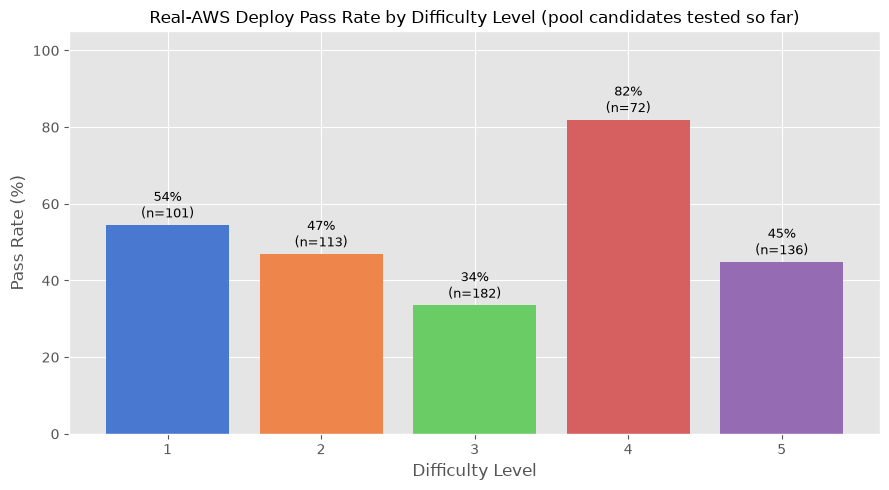

,difficulty,dest_file,deploy_status,error_preview
0,5,cfn_templates_greenfield/Sage-Bionetworks__Synapse-Stack-Builder/src/test/resources/vpc/private-...,ROLLBACK_COMPLETE,"bedrockagentVPCEndpoint: Resource handler returned message: "" (Service: Ec2, Status Code: 400, R..."
1,5,cfn_templates/aws__aws-database-encryption-sdk-dynamodb/cfn/CI.yaml,ROLLBACK_COMPLETE,ROLLBACK_COMPLETE: no StackStatusReason or FAILED resource event found
2,5,cfn_templates/Yoshiki0705__FSx-for-ONTAP-S3AccessPoints-Serverless-Patterns/shared/cfn/flexclone...,ROLLBACK_COMPLETE,ROLLBACK_COMPLETE: no StackStatusReason or FAILED resource event found
3,5,cfn_templates/aws-amplify__amplify-cli/amplify-migration-apps/mood-board/_snapshot.pre.refactor/...,ROLLBACK_COMPLETE,QueryGetKinesisEventsAuthFNQueryGetKinesisEventsAuthFNAppSyncFunctionC22C8158: Resource handler ...
4,5,cfn_templates/DataDog__cloudformation-template/aws_quickstart/main_extended_workflow.yaml,ROLLBACK_COMPLETE,DatadogIntegrationRoleStack: TemplateURL must be a supported URL.
...,...,...,...,...
250,1,cfn_templates/aws-samples__codenator-automatic-code-generation-and-execution-using-llm/deploymen...,ROLLBACK_COMPLETE,cfn-eval-gt-check-27d2e9747a: Validation failed with 3 error(s). Call DescribeEvents to retrieve...
251,1,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_18754_deploy.yml,ROLLBACK_COMPLETE,"paragroup: Resource handler returned message: ""ParameterGroupFamily somefam is not a valid param..."
252,1,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_13710_ecs-task-...,ROLLBACK_COMPLETE,"WorkerTaskDefinition: Resource handler returned message: ""Invalid request provided: Create TaskD..."
253,1,cfn_templates/Tianyi2__IRIS/data/cloudformation_collected_templates_new/template_17852_aws-tgw-t...,ROLLBACK_COMPLETE,"myResourceShare: Resource handler returned message: ""Principal ID is malformed. Verify the ID an..."


/var/folders/mr/k47n2bks0fs1y0cmq922vqbh0000gn/T/ipykernel_44195/3237486538.py:83: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


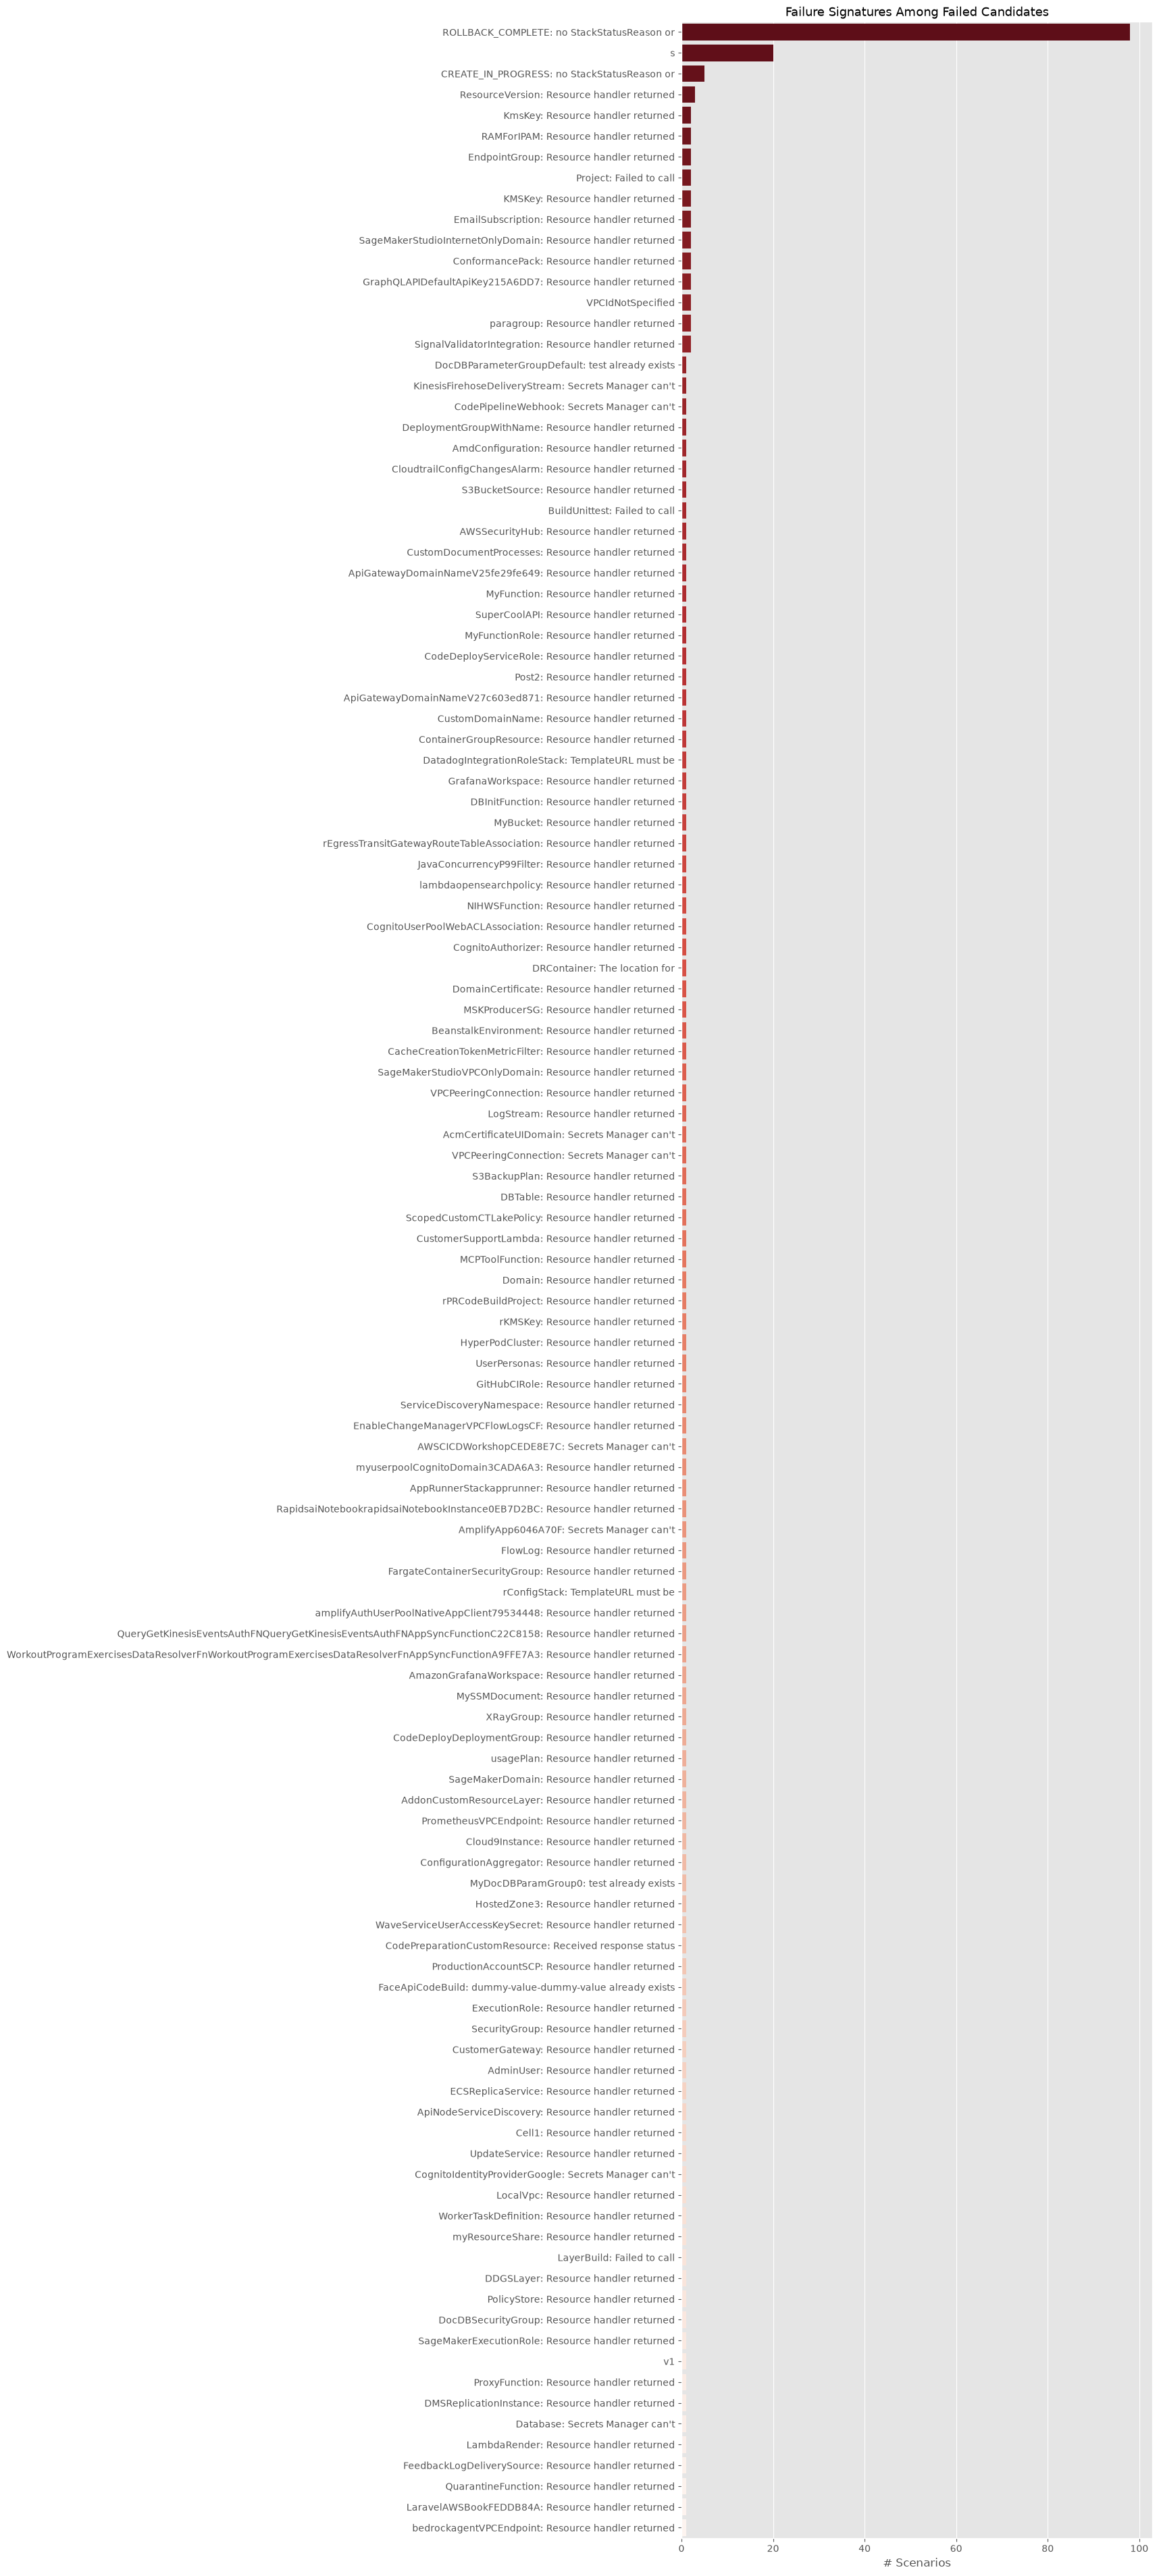


Candidates likely worth a minimal-fix triage pass (mechanical, verifiable, single-cause failures -- not external dependencies):
  [98x] ROLLBACK_COMPLETE: no StackStatusReason or
         - cfn_templates/widdix__aws-cf-templates/ecs/service-cluster-alb.yaml
         - cfn_templates/aws-samples__aws-service-catalog-reference-architectures/blog_content/securing-third-party-data-and-ml-apps/admin-setup-app.yaml
         - cfn_templates/aws-samples__aws-service-catalog-reference-architectures/blog_content/bedrock_genai/content/genairacer/src/genairacer_kb_2_of_2.json
         - cfn_templates/aws-samples__aws-hpc-recipes/recipes/pcs/cfd_cluster/assets/cluster-launch-templates.yaml
         - cfn_templates/aws-samples__aws-hpc-recipes/recipes/pcs/isolated_pcs/assets/cluster/pcs-isolated-cluster.yaml
         ... and 93 more
  [20x] s                                       
         - cfn_templates/kyhau__aws-tools/FinOps/cfn/cost-anomaly-detection.yml
         - cfn_templates/aws-cloudformat

In [240]:
GT_DEPLOY_CACHE_PATH_ANALYTICS = DATASET_DIR / 'ground_truth_deploy_check_aws.csv'

if not GT_DEPLOY_CACHE_PATH_ANALYTICS.exists():
    print(f'⚠️ {GT_DEPLOY_CACHE_PATH_ANALYTICS.name} not found -- run the deploy-check section above '
          f'first (with RUN_DEPLOYMENT = True) to generate results.')
else:
    gt_results_analytics = pd.read_csv(GT_DEPLOY_CACHE_PATH_ANALYTICS)
    gt = df_pool.merge(gt_results_analytics, on='content_hash', how='inner')

    n_checked = len(gt)
    n_total = len(df_pool)
    n_pass = (gt['deploy_pass'] == True).sum()
    n_fail = (gt['deploy_pass'] == False).sum()
    n_error = gt['deploy_pass'].isna().sum()

    print(f'Checked so far: {n_checked} / {n_total} pool candidates ({n_checked / n_total:.1%})')
    print(f'  ✅ Deployed successfully : {n_pass} ({n_pass / n_checked:.1%})' if n_checked else '')
    print(f'  ❌ Deploy failed         : {n_fail} ({n_fail / n_checked:.1%})' if n_checked else '')
    print(f'  ⚠️  Validate/error/skip   : {n_error} ({n_error / n_checked:.1%})' if n_checked else '')

    if 'destroy_pass' in gt.columns:
        orphaned = gt[gt['destroy_pass'] == False]
        if not orphaned.empty:
            print(f"\n🚨 {len(orphaned)} stack(s) FAILED TO DELETE and may still exist in AWS:")
            cols = [c for c in ['dest_file', 'deployed_stack_name', 'destroy_error'] if c in orphaned.columns]
            with pd.option_context('display.max_colwidth', 120, 'display.width', 220):
                display(orphaned[cols].reset_index(drop=True))
            print('   Check the AWS Console / `aws cloudformation describe-stacks --profile default` directly.')
        else:
            n_attempted = gt['destroy_pass'].notna().sum()
            print(f'\n🧹 Cleanup: {n_attempted} stack(s) attempted deletion, 0 orphaned.')

    pass_by_diff = gt.groupby('difficulty')['deploy_pass'].apply(lambda s: (s == True).mean() * 100)
    counts_by_diff = gt.groupby('difficulty').size()

    plt.figure(figsize=(9, 5))
    bars = plt.bar(pass_by_diff.index.astype(str), pass_by_diff.values, color=sns.color_palette('muted'))
    plt.title('Real-AWS Deploy Pass Rate by Difficulty Level (pool candidates tested so far)', fontsize=12)
    plt.xlabel('Difficulty Level')
    plt.ylabel('Pass Rate (%)')
    plt.ylim(0, 105)
    for bar, diff in zip(bars, pass_by_diff.index):
        n = counts_by_diff[diff]
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
                  f'{bar.get_height():.0f}%\n(n={n})', ha='center', fontsize=9)
    plt.tight_layout()
    plt.show()

    failed = gt[gt['deploy_pass'] == False].copy()
    if not failed.empty:
        failed['error_preview'] = failed['deploy_error'].astype(str).str.slice(0, 100)
        cols = [c for c in ['difficulty', 'dest_file', 'deploy_status', 'error_preview'] if c in failed.columns]
        with pd.option_context('display.max_colwidth', 100, 'display.width', 220):
            display(failed.sort_values('difficulty', ascending=False)[cols].reset_index(drop=True))
    else:
        print('\n🎉 No failures among checked candidates so far.')

    if not failed.empty:
        def _error_signature(msg):
            m = re.search(r'\(([A-Za-z][A-Za-z0-9_.]*)\)', str(msg))
            if m:
                return m.group(1)
            return ' '.join(str(msg).split()[:4]) or 'Unknown'

        failed['error_signature'] = failed['deploy_error'].apply(_error_signature)
        sig_counts = failed['error_signature'].value_counts()

        plt.figure(figsize=(9, max(3, 0.4 * len(sig_counts))))
        sns.barplot(y=sig_counts.index, x=sig_counts.values, hue=sig_counts.index,
                    palette='Reds_r', legend=False)
        plt.title('Failure Signatures Among Failed Candidates', fontsize=13)
        plt.xlabel('# Scenarios')
        plt.ylabel('')
        plt.tight_layout()
        plt.show()

        print('\nCandidates likely worth a minimal-fix triage pass (mechanical, verifiable, '
              'single-cause failures -- not external dependencies):')
        for sig, cnt in sig_counts.items():
            examples = failed[failed['error_signature'] == sig]['dest_file'].tolist()
            print(f'  [{cnt:2d}x] {sig:<40s}')
            for ex in examples[:5]:
                print(f'         - {ex}')
            if len(examples) > 5:
                print(f'         ... and {len(examples) - 5} more')

### §17g Manual-fix scenario status

In [241]:
_mf = pd.DataFrame(MANUAL_FIX_SCENARIOS)
_mf['content_hash'] = _mf['gf_dest_file'].map(
    lambda d: content_hash(normalise_cfn(read_cfn_content(d))) if (BASE_DIR / d).exists() else None)


def _latest(path, cols, rename=None):
    if not Path(path).exists():
        return pd.DataFrame(columns=cols)
    _d = pd.read_csv(path, usecols=cols, low_memory=False).drop_duplicates('content_hash', keep='last')
    return _d.rename(columns=rename or {})


_mf = (_mf
       .merge(_latest(LINT_CACHE_PATH, ['content_hash', 'lint_pass']), on='content_hash', how='left')
       .merge(_latest(SEC_CACHE_PATH, ['content_hash', 'trivy_critical', 'trivy_high', 'trivy_error']), on='content_hash', how='left')
       .merge(_latest(LOCALSTACK_DEPLOY_CACHE, ['content_hash', 'deploy_pass'], {'deploy_pass': 'localstack_pass'}), on='content_hash', how='left')
       .merge(_latest(GT_DEPLOY_CACHE_PATH, ['content_hash', 'deploy_pass', 'deploy_error'], {'deploy_pass': 'real_aws_pass'}), on='content_hash', how='left'))
_mf['in_df_aws'] = _mf['content_hash'].isin(set(df_aws['content_hash'])) if 'df_aws' in globals() else np.nan
_mf['in_real_aws_pool'] = _mf['gf_dest_file'].isin(set(df_pool['dest_file'])) if 'df_pool' in globals() else np.nan
_frozen = set(pd.read_csv(REAL_AWS_PROMPTS_CSV, usecols=['dest_file'])['dest_file']) if REAL_AWS_PROMPTS_CSV.exists() else set()
_mf['in_final_benchmark'] = _mf['gf_dest_file'].isin(_frozen)


def _mf_status(r):
    if r['content_hash'] is None:
        return 'greenfield file missing'
    if r['in_df_aws'] is False:
        return 'filtered before lint (§10-§13)'
    if pd.isna(r['lint_pass']):
        return 'not yet linted'
    if str(r['lint_pass']).lower() != 'true':
        return 'lint failed'
    if pd.isna(r['trivy_critical']):
        return 'not yet scanned'
    if r['trivy_critical'] > 0 or r['trivy_high'] > 0 or str(r['trivy_error']) not in ('', 'nan'):
        return 'Trivy CRITICAL/HIGH'
    if pd.isna(r['real_aws_pass']):
        return 'not yet real-AWS tested'
    if str(r['real_aws_pass']).lower() != 'true':
        return f"real-AWS failed: {str(r['deploy_error'])[:60]}"
    return 'real-AWS verified'


_mf['status'] = _mf.apply(_mf_status, axis=1)
print(_mf['status'].map(lambda s: s.split(':')[0]).value_counts().rename('manual fixes by status').to_string())
with pd.option_context('display.max_colwidth', 90, 'display.width', 250):
    display(_mf[['category', 'gf_dest_file', 'lint_pass', 'trivy_critical', 'trivy_high', 'localstack_pass',
                 'real_aws_pass', 'in_final_benchmark', 'status']])

status
real-AWS verified                 64
real-AWS failed                   12
not yet real-AWS tested            9
Trivy CRITICAL/HIGH                1
filtered before lint (§10-§13)     1


,category,gf_dest_file,lint_pass,trivy_critical,trivy_high,localstack_pass,real_aws_pass,in_final_benchmark,status
0,security_suppression_removed,cfn_templates_greenfield/estanqueiroa__awscode/cloudformation/vpc-endpoints-tags/vpce-...,True,0,0,NaN,True,True,real-AWS verified
1,managed_policy_typo,cfn_templates_greenfield/Tianyi2__IRIS/data/cloudformation_collected_templates_new/tem...,True,-1,-1,True,NaN,False,Trivy CRITICAL/HIGH
2,hardcoded_az,cfn_templates_greenfield/aws-samples__aws-cloudformation-security-automation-for-wazuh...,True,0,0,True,False,False,"real-AWS failed: rMgmtBastionInstance: Resource handler returned message: ""In"
3,missing_glue_database,cfn_templates_greenfield/aws-samples__sample-aws-sa-genai/2_Quick_Admin_Suite/CFT/Fina...,True,0,0,True,False,False,real-AWS failed: FeedbackLogDeliverySource: Resource handler returned message
4,sam_codeuri_local_path,cfn_templates_greenfield/eijikominami__aws-cloudformation-templates/notification/sam-a...,True,0,0,False,NaN,False,not yet real-AWS tested
...,...,...,...,...,...,...,...,...,...
82,security_suppression_removed,cfn_templates_greenfield/aws-samples__sample-multi-region-resilient-microservice-on-aw...,True,0,0,NaN,True,False,real-AWS verified
83,security_suppression_removed,cfn_templates_greenfield/awslabs__genai-idp-terraform/sources/scripts/alb-test-vpc.yaml,True,0,0,NaN,True,True,real-AWS verified
84,security_suppression_removed,cfn_templates_greenfield/aws-solutions-library-samples__guidance-for-multi-region-resi...,True,0,0,NaN,True,True,real-AWS verified
85,security_suppression_removed,cfn_templates_greenfield/aws-samples__sample-emr-eks-spark-kerberos-hms/data-infra/eks...,True,0,0,NaN,True,True,real-AWS verified


### §17h Cost-safety sweep: aws-nuke (gated by `RUN_NUKE_SWEEP`)

In [ ]:
import subprocess
from datetime import datetime

NUKE_CONFIG_PATH = Path('nuke-config.yml')
NUKE_LOG_DIR = DATASET_DIR / 'nuke_logs'

if not RUN_NUKE_SWEEP:
    print('⏸️  RUN_NUKE_SWEEP is False -- skipping. This is a full-account, unattended')
    print('   `aws-nuke run --no-dry-run --no-prompt` -- test manually with a plain dry run')
    print('   first, then set RUN_NUKE_SWEEP = True when you\'re confident in the config.')
else:
    if not NUKE_CONFIG_PATH.exists():
        raise FileNotFoundError(f'{NUKE_CONFIG_PATH} not found -- expected it next to this notebook.')

    NUKE_LOG_DIR.mkdir(parents=True, exist_ok=True)
    log_path = NUKE_LOG_DIR / f"nuke_{datetime.now().strftime('%Y%m%dT%H%M%S')}.log"

    cmd = [
        'aws-nuke', 'run',
        '--profile', AWS_PROFILE,
        '-c', str(NUKE_CONFIG_PATH),
        '--no-alias-check',
        '--no-dry-run',
        '--no-prompt',
    ]
    print(f'🧨 Running: {" ".join(cmd)}')
    print(f'   Full output -> {log_path}')

    result = subprocess.run(cmd, capture_output=True, text=True, timeout=1800)
    log_path.write_text(f"$ {' '.join(cmd)}\n\n--- stdout ---\n{result.stdout}\n\n--- stderr ---\n{result.stderr}\n")

    print(f'\nExit code: {result.returncode}')
    print('--- last 40 lines of output ---')
    for line in (result.stdout + result.stderr).splitlines()[-40:]:
        print(line)

    if result.returncode != 0:
        print(f'\n🚨 aws-nuke exited non-zero -- read the full log at {log_path} before assuming the account is clean.')
    else:
        print(f'\n✅ Sweep completed. Full log at {log_path}.')

### §17i Post-flight: disable services enabled by pre-flight (gated by `RUN_POSTFLIGHT_TEARDOWN`)

In [30]:
import os
import boto3
import botocore


_PREFLIGHT_STACK_NAME = 'cfn-eval-gt-config-prereq'


def _postflight_config():
    cfn = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('cloudformation')
    configservice = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('config')
    s3 = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('s3')

    try:
        desc = cfn.describe_stacks(StackName=_PREFLIGHT_STACK_NAME)
        status = desc['Stacks'][0]['StackStatus']
    except botocore.exceptions.ClientError:
        print(f"✅ Prereq stack {_PREFLIGHT_STACK_NAME!r} doesn't exist -- nothing to tear down.")
        return

    print(f"🔧 Tearing down AWS Config prerequisite stack {_PREFLIGHT_STACK_NAME!r} (status={status})...")
    try:
        configservice.stop_configuration_recorder(ConfigurationRecorderName='default')
        print("   Stopped configuration recorder.")
    except botocore.exceptions.ClientError as e:
        print(f"   (recorder already stopped or missing: {e.response.get('Error', {}).get('Code', '')})")

    bucket_name = None
    for res in cfn.list_stack_resources(StackName=_PREFLIGHT_STACK_NAME)['StackResourceSummaries']:
        if res['LogicalResourceId'] == 'ConfigBucket':
            bucket_name = res['PhysicalResourceId']
            break
    if bucket_name:
        paginator = s3.get_paginator('list_object_versions')
        to_delete = []
        for page in paginator.paginate(Bucket=bucket_name):
            for v in page.get('Versions', []) + page.get('DeleteMarkers', []):
                to_delete.append({'Key': v['Key'], 'VersionId': v['VersionId']})
        for i in range(0, len(to_delete), 1000):
            batch = to_delete[i:i + 1000]
            if batch:
                s3.delete_objects(Bucket=bucket_name, Delete={'Objects': batch})
        if to_delete:
            print(f"   Emptied {len(to_delete)} object(s) from {bucket_name} before stack deletion.")

    cfn.delete_stack(StackName=_PREFLIGHT_STACK_NAME)
    waiter = cfn.get_waiter('stack_delete_complete')
    waiter.wait(StackName=_PREFLIGHT_STACK_NAME, WaiterConfig={'Delay': 10, 'MaxAttempts': 60})
    print("✅ Config recorder + delivery channel + bucket + role deleted.")


def _postflight_security_hub():
    securityhub = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('securityhub')
    try:
        securityhub.describe_hub()
    except botocore.exceptions.ClientError as e:
        code = e.response.get('Error', {}).get('Code', '')
        if code in ('InvalidAccessException', 'ResourceNotFoundException'):
            print('✅ Security Hub already disabled -- nothing to do.')
            return
        raise

    print('🔧 Disabling Security Hub...')
    securityhub.disable_security_hub()
    print('✅ Security Hub disabled.')


def _postflight_inspector_ec2():
    inspector2 = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('inspector2')
    sts = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('sts')
    account_id = sts.get_caller_identity()['Account']

    status = inspector2.batch_get_account_status(accountIds=[account_id])
    resource_state = status['accounts'][0]['resourceState'] if status['accounts'] else {}
    ec2_state = resource_state.get('ec2', {}).get('status')
    if ec2_state in (None, 'DISABLED', 'DISABLING'):
        print('✅ Amazon Inspector for EC2 already disabled -- nothing to do.')
        return

    print('🔧 Disabling Amazon Inspector for EC2...')
    inspector2.disable(accountIds=[account_id], resourceTypes=['EC2'])
    print('✅ Amazon Inspector for EC2 disabled.')


def _postflight_ami_block_public_access():
    ec2 = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION).client('ec2')
    current = ec2.get_image_block_public_access_state()
    if current.get('ImageBlockPublicAccessState') == 'block-new-sharing':
        print('✅ EC2 AMI block-public-access already restored -- nothing to do.')
        return

    print('🔧 Restoring EC2 "Block Public Access for AMIs" to its default...')
    ec2.enable_image_block_public_access(ImageBlockPublicAccessState='block-new-sharing')
    print('✅ AMI block-public-access restored (this setting has no cost either way -- restored for symmetry).')


if not RUN_POSTFLIGHT_TEARDOWN:
    print('⏸️  RUN_POSTFLIGHT_TEARDOWN is False -- skipping. Set to True to disable everything the')
    print('   pre-flight cell turned on (AWS Config, Security Hub, Inspector-for-EC2, AMI public-access),')
    print('   so none of it keeps billing between benchmark runs.')
else:
    _postflight_config()
    _postflight_security_hub()
    _postflight_inspector_ec2()
    _postflight_ami_block_public_access()
    print('\n✅ Post-flight teardown complete -- account restored to its pre-benchmark state.')

🔧 Tearing down AWS Config prerequisite stack 'cfn-eval-gt-config-prereq' (status=CREATE_COMPLETE)...
   Stopped configuration recorder.


KeyboardInterrupt: 

## §18 Final Benchmark Assembly (fill the gaps only)

### §18a Optional: merge reviewed prompts (gated by `RUN_PROMPT_MERGE`)

In [242]:
if not RUN_PROMPT_MERGE:
    print('⏸️  RUN_PROMPT_MERGE is False -- prompts not merged.')
else:

    REVIEWED_PROMPTS_CSV = Path('cfn_output.csv')

    OVERWRITE_EXISTING_PROMPTS = False

    if not REVIEWED_PROMPTS_CSV.exists():
        print(f"⏸️  {REVIEWED_PROMPTS_CSV} not found -- skipping prompt merge.")
    else:
        df_reviewed = pd.read_csv(REVIEWED_PROMPTS_CSV, dtype=str)
        if 'content_hash' not in df_reviewed.columns or 'user_prompt' not in df_reviewed.columns:
            raise ValueError(
                f"{REVIEWED_PROMPTS_CSV.name} is missing 'content_hash' or 'user_prompt' -- wrong file?"
            )

        df_reviewed_valid = df_reviewed[
            df_reviewed['user_prompt'].notna()
            & (df_reviewed['user_prompt'].str.strip() != '')
            & (~df_reviewed['user_prompt'].str.startswith('ERROR:'))
        ].drop_duplicates('content_hash', keep='last')

        n_unverified = 0
        if 'tag_verified' in df_reviewed_valid.columns:
            n_unverified = int((df_reviewed_valid['tag_verified'].astype(str).str.lower() != 'true').sum())

        reviewed_prompt_map = dict(zip(df_reviewed_valid['content_hash'], df_reviewed_valid['user_prompt']))
        print(f"Loaded {len(reviewed_prompt_map)} usable prompt(s) from {REVIEWED_PROMPTS_CSV.name} "
              f"({len(df_reviewed) - len(df_reviewed_valid)} row(s) skipped as blank/ERROR/duplicate).")
        if n_unverified:
            print(f"   ⚠️  {n_unverified} of those have tag_verified != True -- "
                  f"gemini_cfn_prompt_generator.py could not confirm the response matched the "
                  f"request for these; worth a manual re-check before fully trusting them.")

        for _target_path in [DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv',
                              DATASET_DIR / 'final_benchmark_real_aws_custom.csv']:
            if not _target_path.exists():
                print(f"⏸️  {_target_path.name} not found -- skipping.")
                continue

            df_target = pd.read_csv(_target_path)
            if 'content_hash' not in df_target.columns:
                print(f"⏸️  {_target_path.name} has no 'content_hash' column -- skipping.")
                continue

            df_target['user_prompt'] = df_target['user_prompt'].astype('object')

            has_match = df_target['content_hash'].isin(reviewed_prompt_map)
            new_values = df_target['content_hash'].map(reviewed_prompt_map)
            is_blank = df_target['user_prompt'].isna() | (df_target['user_prompt'].astype(str).str.strip() == '')
            n_no_match = int((~has_match).sum())

            if OVERWRITE_EXISTING_PROMPTS:
                eligible = has_match
                differs = df_target['user_prompt'].fillna('') != new_values.fillna('')
                actually_changed = eligible & differs
                n_written = int(actually_changed.sum())
                n_already_matched = int((eligible & ~differs).sum())

                df_target.loc[eligible, 'user_prompt'] = new_values[eligible]
                df_target.to_csv(_target_path, index=False)

                print(f"✅ {_target_path.name}: overwrote {n_written} row(s) with the prompt from "
                      f"{REVIEWED_PROMPTS_CSV.name} (by content_hash).")
                if n_already_matched:
                    print(f"   ℹ️ {n_already_matched} row(s) already matched exactly -- no change.")
            else:
                eligible = has_match & is_blank
                n_written = int(eligible.sum())
                n_skipped_had_prompt = int((has_match & ~is_blank).sum())

                df_target.loc[eligible, 'user_prompt'] = new_values[eligible]
                df_target.to_csv(_target_path, index=False)

                print(f"✅ {_target_path.name}: filled {n_written} previously-blank row(s) from "
                      f"{REVIEWED_PROMPTS_CSV.name} (by content_hash).")
                if n_skipped_had_prompt:
                    print(f"   ℹ️ {n_skipped_had_prompt} row(s) already had a non-blank prompt -- left "
                          f"untouched (set OVERWRITE_EXISTING_PROMPTS = True to force-overwrite these too).")

            if n_no_match:
                print(f"   ℹ️ {n_no_match} row(s) have no matching content_hash in "
                      f"{REVIEWED_PROMPTS_CSV.name} -- not yet processed by gemini_cfn_prompt_generator.py.")

⏸️  RUN_PROMPT_MERGE is False -- prompts not merged.


### §18b Assembly

In [243]:
import pandas as pd
import numpy as np
import difflib
from collections import defaultdict
from pathlib import Path

ASSEMBLY_DRY_RUN = False

REAL_AWS_CUSTOM_CSV = DATASET_DIR / 'final_benchmark_real_aws_custom.csv'
REAL_AWS_PROMPTS_CSV = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'
GT_DEPLOY_CACHE_PATH = DATASET_DIR / 'ground_truth_deploy_check_aws.csv'
PROTECTED_BASELINE_CSV = DATASET_DIR / 'cfn_eval_benchmark_real_aws_diff345_v1.csv'

TARGETS_PER_LEVEL = {1: 50, 2: 50, 3: 50, 4: 50, 5: 50}

if not GT_DEPLOY_CACHE_PATH.exists():
    raise FileNotFoundError(
        f"{GT_DEPLOY_CACHE_PATH} not found -- run the real-AWS deploy-check section "
        f"(RUN_DEPLOYMENT = True) at least once first."
    )

gt_cache = pd.read_csv(GT_DEPLOY_CACHE_PATH)[['content_hash', 'deploy_pass']].drop_duplicates('content_hash')
df_deployable_real = df_pool.merge(gt_cache, on='content_hash', how='inner')
df_deployable_real = df_deployable_real[df_deployable_real['deploy_pass'] == True].copy()
df_deployable_real['content'] = df_deployable_real['dest_file'].apply(
    lambda d: (BASE_DIR / str(d)).read_text(encoding='utf-8', errors='ignore') if (BASE_DIR / str(d)).exists() else ''
)
print(f"Real-AWS-verified, lint+Trivy-clean candidates: {len(df_deployable_real):,}")

protected_ground_truth_paths = set()
protected_row_map, protected_prompt_map = {}, {}
if PROTECTED_BASELINE_CSV.exists():
    df_protected = pd.read_csv(PROTECTED_BASELINE_CSV)
    protected_ground_truth_paths = set(df_protected['ground_truth_path'])
    protected_row_map = dict(zip(df_protected['ground_truth_path'], df_protected['row_number']))
    protected_prompt_map = dict(zip(df_protected['ground_truth_path'], df_protected['prompt']))
    print(f"🔒 Loaded {len(protected_ground_truth_paths)} protected scenario(s) from "
          f"{PROTECTED_BASELINE_CSV.name}.")

    if REAL_AWS_PROMPTS_CSV.exists():
        _frozen_owner = pd.read_csv(REAL_AWS_PROMPTS_CSV, usecols=['row_number', 'dest_file'])
        _owner_by_rn = dict(zip(_frozen_owner['row_number'], _frozen_owner['dest_file']))
        _stale_protected = {p for p, rn in protected_row_map.items()
                            if rn in _owner_by_rn and _owner_by_rn[rn] != p}
        if _stale_protected:
            print(f"\u26a0\ufe0f Ignoring {len(_stale_protected)} stale protected entr(y/ies): the frozen "
                  f"benchmark has since moved their row_number to a different dest_file. "
                  f"Refresh {PROTECTED_BASELINE_CSV.name} if this is unexpected.")
            for _p in sorted(_stale_protected):
                _rn = protected_row_map[_p]
                print(f"   - row {int(_rn)}: {_p}  ->  now {_owner_by_rn[_rn]}")
            protected_ground_truth_paths -= _stale_protected
            for _p in _stale_protected:
                protected_row_map.pop(_p, None)
                protected_prompt_map.pop(_p, None)

    protected_still_valid = protected_ground_truth_paths & set(df_pool['dest_file'])
    protected_broken = protected_ground_truth_paths - protected_still_valid
    if protected_broken:
        print(f"⚠️ {len(protected_broken)} protected scenario(s) are no longer lint+Trivy-clean "
              f"in the current pool and CANNOT be protected: {sorted(protected_broken)}")

    protected_missing_deploy = protected_still_valid - set(
        df_deployable_real.loc[df_deployable_real['dest_file'].isin(protected_still_valid), 'dest_file']
    )
    _gt_by_hash_p = dict(zip(gt_cache['content_hash'], gt_cache['deploy_pass']))
    _pool_hash_p = dict(zip(df_pool['dest_file'], df_pool['content_hash']))
    _protected_failing = {_d for _d in protected_missing_deploy
                          if _gt_by_hash_p.get(_pool_hash_p.get(_d)) == False}
    if _protected_failing:
        print(f"\u274c {len(_protected_failing)} protected scenario(s) are a CONFIRMED real-AWS "
              f"failure under their current content_hash -- NOT force-carried, eligible for "
              f"resampling: {sorted(_protected_failing)}")
        protected_missing_deploy = protected_missing_deploy - _protected_failing

    if protected_missing_deploy:
        df_protected_extra = df_pool[df_pool['dest_file'].isin(protected_missing_deploy)].copy()
        df_protected_extra['deploy_pass'] = pd.NA
        df_protected_extra['content'] = df_protected_extra['dest_file'].apply(
            lambda d: (BASE_DIR / str(d)).read_text(encoding='utf-8', errors='ignore') if (BASE_DIR / str(d)).exists() else ''
        )
        print(f"🔒 {len(df_protected_extra)} protected scenario(s) have no real-AWS deploy_pass entry "
              f"under their current content_hash yet -- carried through anyway: "
              f"{sorted(df_protected_extra['dest_file'].tolist())}")
        df_deployable_real = pd.concat([df_deployable_real, df_protected_extra], ignore_index=True, sort=False)
else:
    print(f"ℹ️ No protected baseline found at {PROTECTED_BASELINE_CSV.name} -- skipping.")

existing_row_map, existing_prompt_map, existing_difficulty_map = {}, {}, {}
existing_extra_maps = {}
max_existing_row_number = -1
old_dest_files = set()

if REAL_AWS_PROMPTS_CSV.exists():
    df_old = pd.read_csv(REAL_AWS_PROMPTS_CSV)
    existing_row_map = dict(zip(df_old['dest_file'], df_old['row_number']))
    max_existing_row_number = int(df_old['row_number'].max())
    existing_prompt_map = dict(zip(df_old['dest_file'], df_old['user_prompt']))
    existing_difficulty_map = dict(zip(df_old['dest_file'], df_old['difficulty']))
    old_dest_files = set(df_old['dest_file'])
    extra_cols = [c for c in df_old.columns if c not in df_deployable_real.columns
                  and c not in ('dest_file', 'row_number', 'user_prompt')]
    existing_extra_maps = {c: dict(zip(df_old['dest_file'], df_old[c])) for c in extra_cols}
    print(f"Loaded existing real-AWS benchmark: {len(df_old)} scenarios.")
else:
    print("No existing real-AWS benchmark found -- building from scratch.")

if protected_row_map:
    max_existing_row_number = max(max_existing_row_number, int(max(protected_row_map.values())))

if old_dest_files:
    gt_by_hash = dict(zip(gt_cache['content_hash'], gt_cache['deploy_pass']))
    pool_hash_by_dest = dict(zip(df_pool['dest_file'], df_pool['content_hash']))
    existing_missing_deploy = (old_dest_files & set(df_pool['dest_file'])) - set(df_deployable_real['dest_file'])
    existing_confirmed_failed = {
        d for d in existing_missing_deploy
        if gt_by_hash.get(pool_hash_by_dest.get(d)) == False
    }
    existing_untested = existing_missing_deploy - existing_confirmed_failed
    if existing_untested:
        df_existing_extra = df_pool[df_pool['dest_file'].isin(existing_untested)].copy()
        df_existing_extra['deploy_pass'] = pd.NA
        df_existing_extra['content'] = df_existing_extra['dest_file'].apply(
            lambda d: (BASE_DIR / str(d)).read_text(encoding='utf-8', errors='ignore') if (BASE_DIR / str(d)).exists() else ''
        )
        print(f"📌 {len(df_existing_extra)} existing scenario(s) have no real-AWS deploy_pass entry "
              f"under their current content_hash yet -- carried through (not confirmed failing) "
              f"rather than randomly resampled.")
        df_deployable_real = pd.concat([df_deployable_real, df_existing_extra], ignore_index=True, sort=False)
    if existing_confirmed_failed:
        print(f"❌ {len(existing_confirmed_failed)} existing scenario(s) have a CONFIRMED real-AWS "
              f"failure under their current content_hash -- NOT carried through, eligible for "
              f"resampling: {sorted(existing_confirmed_failed)}")


surviving_dest_files = (old_dest_files & set(df_deployable_real['dest_file'])) - MANUAL_EXCLUDE_SET
protected_restore = (protected_ground_truth_paths & set(df_deployable_real['dest_file'])) - MANUAL_EXCLUDE_SET
newly_restored = protected_restore - surviving_dest_files
if newly_restored:
    print(f"🔒 Restoring {len(newly_restored)} protected scenario(s) a previous run had dropped: "
          f"{sorted(newly_restored)}")
surviving_dest_files |= protected_restore

df_kept = df_deployable_real[df_deployable_real['dest_file'].isin(surviving_dest_files)].copy()
combined_row_map = {**existing_row_map, **protected_row_map}
combined_prompt_map = {**existing_prompt_map, **protected_prompt_map}
df_kept['row_number'] = df_kept['dest_file'].map(combined_row_map)
df_kept['user_prompt'] = df_kept['dest_file'].map(combined_prompt_map)
for _col, _mapping in existing_extra_maps.items():
    df_kept[_col] = df_kept['dest_file'].map(_mapping)

kept_by_block = defaultdict(list)
for _, row in df_kept.iterrows():
    kept_by_block[_block_key(row)].append(row['content'])

def _norm_source_path(dest):
    _d = str(dest)
    for _root in ('cfn_templates_greenfield/', 'cfn_templates/'):
        if _d.startswith(_root):
            return _d[len(_root):]
    return _d


kept_source_paths = {_norm_source_path(d) for d in df_kept['dest_file']}

final_dfs = []
next_row_number = max_existing_row_number + 1
scenarios_dropped, scenarios_added = [], []
level_status = []

print("\n⚖️ Assembling real-AWS benchmark (target 50/level, honest shortfall reporting)...")

for level in range(1, 6):
    target = TARGETS_PER_LEVEL.get(level, 0)
    df_lvl_kept = df_kept[df_kept['difficulty'] == level].copy()
    n_kept = len(df_lvl_kept)
    sampled = pd.DataFrame()

    if n_kept > target:
        excess = n_kept - target
        protected_in_level = set(df_lvl_kept.loc[
            df_lvl_kept['dest_file'].isin(protected_ground_truth_paths), 'dest_file'
        ])
        df_lvl_kept = df_lvl_kept.set_index('aws_services')
        for _ in range(excess):
            dropped_one = False
            for top_arch in df_lvl_kept.index.value_counts().index:
                arch_rows = df_lvl_kept.loc[[top_arch]]
                droppable = arch_rows[~arch_rows['dest_file'].isin(protected_in_level)]
                if droppable.empty:
                    continue
                row_to_drop = droppable.iloc[0]
                scenarios_dropped.append(row_to_drop['dest_file'])
                df_lvl_kept = df_lvl_kept[df_lvl_kept['dest_file'] != row_to_drop['dest_file']]
                dropped_one = True
                break
            if not dropped_one:
                print(f"  ⚠️ Level {level}: {excess} over target but every remaining excess "
                      f"candidate is protected -- leaving {len(df_lvl_kept)} in place rather "
                      f"than dropping a protected scenario.")
                break
        df_lvl_kept = df_lvl_kept.reset_index()
        print(f"  ➖ Level {level}: dropped {len(scenarios_dropped)} excess (redundant-first, "
              f"protected scenarios exempted) toward {target}.")

    elif n_kept < target:
        shortfall = target - n_kept
        candidates = df_deployable_real[
            (df_deployable_real['difficulty'] == level) &
            (~df_deployable_real['dest_file'].isin(df_kept['dest_file'])) &
            (~df_deployable_real['dest_file'].isin(MANUAL_EXCLUDE_SET))
        ].copy()

        ordered = sample_diverse(candidates, len(candidates), group_col='aws_services').to_dict('records')
        accepted = []
        accepted_content_by_block = defaultdict(list)
        for rec in ordered:
            if len(accepted) >= shortfall:
                break
            _src = _norm_source_path(rec['dest_file'])
            if _src in kept_source_paths:
                continue
            key = _block_key(rec)
            against = kept_by_block.get(key, []) + accepted_content_by_block.get(key, [])
            is_dup = any(difflib.SequenceMatcher(None, rec['content'], other).quick_ratio() >= 0.90 for other in against)
            if not is_dup:
                kept_source_paths.add(_src)
                accepted.append(rec)
                accepted_content_by_block[key].append(rec['content'])
                scenarios_added.append(rec['dest_file'])

        sampled = pd.DataFrame(accepted)
        if not sampled.empty:
            assigned = list(range(next_row_number, next_row_number + len(sampled)))
            next_row_number += len(sampled)
            sampled['row_number'] = assigned
            sampled['user_prompt'] = np.nan
            df_lvl_kept = pd.concat([df_lvl_kept, sampled], ignore_index=True)

        n_have = len(df_lvl_kept)
        if n_have < target:
            print(f"  🚧 Level {level}: only {n_have}/{target} real-AWS-verified -- {target - n_have} short. "
                  f"See the testing-queue section's queue_by_level[{level}] for what to test next.")
        else:
            print(f"  ➕ Level {level}: kept {n_kept}, added {len(sampled)} real-AWS-verified to reach {n_have}.")

    else:
        print(f"  ✅ Level {level}: exactly {target} real-AWS-verified.")

    level_status.append({'difficulty': level, 'target': target, 'have': len(df_lvl_kept)})
    final_dfs.append(df_lvl_kept)

df_final = pd.concat(final_dfs, ignore_index=True).sort_values('row_number').reset_index(drop=True)
if 'content' in df_final.columns:
    df_final = df_final.drop(columns=['content'])

_dupe_rns = df_final['row_number'][df_final['row_number'].duplicated()].unique()
if len(_dupe_rns):
    raise AssertionError(
        f"❌ {len(_dupe_rns)} duplicate row_number value(s) after assembly: {sorted(_dupe_rns)} -- "
        f"NOT saving. This should be structurally impossible; investigate before rerunning."
    )

_final_dests = set(df_final['dest_file'])
dropped_dest_files = sorted(old_dest_files - _final_dests)
_pool_hash = dict(zip(df_pool['dest_file'], df_pool['content_hash']))
_gt_pass = dict(zip(gt_cache['content_hash'], gt_cache['deploy_pass']))
_aws_hash = dict(zip(df_aws['dest_file'], df_aws['content_hash'])) if 'df_aws' in globals() else {}
_lint_ok = set(pd.read_csv(LINT_CACHE_PATH, usecols=['content_hash', 'lint_pass']).query('lint_pass == True')['content_hash'])
_sec_df = pd.read_csv(SEC_CACHE_PATH, usecols=['content_hash', 'trivy_pass']).drop_duplicates('content_hash', keep='last')
_trivy_ok = set(_sec_df.loc[_sec_df['trivy_pass'] == True, 'content_hash'])

drop_reasons = {}
for _d in dropped_dest_files:
    if _d in MANUAL_EXCLUDE_SET:
        _why = 'excluded (MANUAL_EXCLUDE_DEST_FILES)'
    elif _d in globals().get('SUPPRESSED_DEST_FILES', set()):
        _why = 'Trivy suppression (#trivy:ignore) -- dropped from the pool'
    elif _d in _pool_hash:
        _why = ('confirmed real-AWS deploy failure' if _gt_pass.get(_pool_hash[_d]) == False else
                'level over target (redundant architecture trimmed)' if _d in scenarios_dropped else 'other')
    elif _aws_hash and _d not in _aws_hash:
        _why = 'not in df_aws (size/AWS filter, dedup, or file content changed)'
    elif _aws_hash.get(_d) is not None and _aws_hash[_d] not in _lint_ok:
        _why = 'cfn-lint failed / untested'
    elif _aws_hash.get(_d) is not None and _aws_hash[_d] not in _trivy_ok:
        _why = 'Trivy CRITICAL/HIGH (or unscanned)'
    else:
        _why = 'not in real-AWS pool'
    drop_reasons[_d] = _why

if dropped_dest_files:
    print(f"\nFrozen rows that would be dropped ({len(dropped_dest_files)}):")
    _old_rn = existing_row_map
    display(pd.DataFrame([{'row_number': _old_rn.get(d), 'difficulty': existing_difficulty_map.get(d),
                           'reason': drop_reasons[d], 'dest_file': d} for d in dropped_dest_files])
            .sort_values(['reason', 'row_number']).reset_index(drop=True))
    print(pd.Series(drop_reasons).value_counts().rename('drop reasons').to_string())

_mass_drop_frac = (len(dropped_dest_files) / len(old_dest_files)) if old_dest_files else 0.0
MASS_DROP_BLOCKED = _mass_drop_frac > MASS_DROP_THRESHOLD and not ALLOW_MASS_DROP
if MASS_DROP_BLOCKED:
    print(f"\n🛑 {len(dropped_dest_files)}/{len(old_dest_files)} ({_mass_drop_frac:.0%}) frozen rows would be dropped -- above "
          f"MASS_DROP_THRESHOLD={MASS_DROP_THRESHOLD:.0%}. Writing is REFUSED unless ALLOW_MASS_DROP=True.")

if ASSEMBLY_DRY_RUN:
    print(f"\n🧪 ASSEMBLY_DRY_RUN=True -- nothing written. Would write {len(df_final)} rows to "
          f"{REAL_AWS_PROMPTS_CSV.name} / {REAL_AWS_CUSTOM_CSV.name}.")
elif MASS_DROP_BLOCKED:
    raise RuntimeError(f"Refusing to write {REAL_AWS_PROMPTS_CSV.name}: {len(dropped_dest_files)}/{len(old_dest_files)} frozen "
                       f"rows would be dropped ({_mass_drop_frac:.0%}). See the drop reasons above; set ALLOW_MASS_DROP=True "
                       f"only if this is intended.")
else:
    _ts = datetime.now().strftime('%Y%m%d_%H%M%S')
    for _p in (REAL_AWS_PROMPTS_CSV, REAL_AWS_CUSTOM_CSV):
        if _p.exists():
            shutil.copy2(_p, _p.with_name(f"{_p.name}.bak_{_ts}"))
    df_final.to_csv(REAL_AWS_CUSTOM_CSV, index=False)
    df_final.to_csv(REAL_AWS_PROMPTS_CSV, index=False)
    print(f"\n💾 Saved → {REAL_AWS_CUSTOM_CSV.name} and {REAL_AWS_PROMPTS_CSV.name} ({len(df_final)} rows; "
          f"previous versions backed up as *.bak_{_ts})")
print("\nPer-level status:")
for s in level_status:
    flag = '✅' if s['have'] >= s['target'] else f"🚧 short by {s['target'] - s['have']}"
    print(f"  L{s['difficulty']}: {s['have']}/{s['target']}  {flag}")
if scenarios_dropped:
    print(f"\nDropped {len(scenarios_dropped)} scenario(s) this run.")
if scenarios_added:
    print(f"Added {len(scenarios_added)} scenario(s) this run.")

missing_prompts = df_final['user_prompt'].isna().sum()
if missing_prompts:
    print(f"\n⚠️ {missing_prompts} row(s) still need a prompt -- run:")
    print(f"   CFN_PROMPTS_CSV={REAL_AWS_PROMPTS_CSV} python3 generate_cfn_prompts.py")

Real-AWS-verified, lint+Trivy-clean candidates: 289
🔒 Loaded 150 protected scenario(s) from cfn_eval_benchmark_real_aws_diff345_v1.csv.
❌ 1 protected scenario(s) are a CONFIRMED real-AWS failure under their current content_hash -- NOT force-carried, eligible for resampling: ['cfn_templates_greenfield/aws-samples__sample-emr-celeborn-shuffle-service/emr-on-eks/cloudformation/emr-nodegroups.yaml']
Loaded existing real-AWS benchmark: 249 scenarios.
🔒 Restoring 1 protected scenario(s) a previous run had dropped: ['cfn_templates_greenfield/aws-ia__cfn-mp-ql-rules/test/fixtures/templates/stackhelper/quickstart-codepipeline-bluegreen-deployment/templates/elasticbeanstalk-sample.template']

⚖️ Assembling real-AWS benchmark (target 50/level, honest shortfall reporting)...
  ✅ Level 1: exactly 50 real-AWS-verified.
  ✅ Level 2: exactly 50 real-AWS-verified.
  ✅ Level 3: exactly 50 real-AWS-verified.
  ➕ Level 4: kept 49, added 1 real-AWS-verified to reach 50.
  ➖ Level 5: dropped 1 excess (redun

,row_number,difficulty,reason,dest_file
0,267.0,5,level over target (redundant architecture trim...,cfn_templates_greenfield/estanqueiroa__awscode...


level over target (redundant architecture trimmed)    1

💾 Saved → final_benchmark_real_aws_custom.csv and final_benchmark_real_aws_with_prompts.csv (250 rows; previous versions backed up as *.bak_20260916_155709)

Per-level status:
  L1: 50/50  ✅
  L2: 50/50  ✅
  L3: 50/50  ✅
  L4: 50/50  ✅
  L5: 50/50  ✅

Dropped 1 scenario(s) this run.
Added 1 scenario(s) this run.

⚠️ 1 row(s) still need a prompt -- run:
   CFN_PROMPTS_CSV=cfn_benchmark/dataset/final_benchmark_real_aws_with_prompts.csv python3 generate_cfn_prompts.py


### §18c Post-assembly near-duplicate check

In [215]:
import difflib
from collections import defaultdict

PROMPTS_CSV = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'

df_check = pd.read_csv(PROMPTS_CSV)

def read_cfn_content(dest_file):
    p = BASE_DIR / str(dest_file)
    return p.read_text(encoding='utf-8', errors='ignore') if p.exists() else ''

df_check['content'] = df_check['dest_file'].apply(read_cfn_content)

def _block_key(row):
    return (row['n_resources'], frozenset(str(row.get('resource_types', '')).split(' | ')))

blocks = defaultdict(list)
for _, row in df_check.iterrows():
    blocks[_block_key(row)].append(row)

DUP_THRESHOLD = 0.90
content_dup_pairs = []
for key, rows in blocks.items():
    if len(rows) < 2:
        continue
    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            a, b = rows[i], rows[j]
            ratio = difflib.SequenceMatcher(None, a['content'], b['content']).quick_ratio()
            if ratio >= DUP_THRESHOLD:
                content_dup_pairs.append((a, b, ratio))

CONTENT_ROOTS = ['cfn_templates_greenfield/', 'cfn_templates/']

def normalize_source_path(dest_file):
    for root in CONTENT_ROOTS:
        if str(dest_file).startswith(root):
            return str(dest_file)[len(root):]
    return str(dest_file)

df_check['source_path_norm'] = df_check['dest_file'].apply(normalize_source_path)
path_groups = defaultdict(list)
for _, row in df_check.iterrows():
    path_groups[row['source_path_norm']].append(row)

source_path_dups = {path: rows for path, rows in path_groups.items() if len(rows) > 1}

any_found = bool(content_dup_pairs) or bool(source_path_dups)

if content_dup_pairs:
    print(f"⚠️ Content-similarity check: {len(content_dup_pairs)} near-duplicate pair(s) (quick_ratio >= {DUP_THRESHOLD}):")
    for a, b, ratio in sorted(content_dup_pairs, key=lambda t: -t[2]):
        print(f"\n  similarity={ratio:.3f}")
        print(f"    row {a['row_number']} (difficulty {a['difficulty']}): {a['dest_file']}")
        print(f"    row {b['row_number']} (difficulty {b['difficulty']}): {b['dest_file']}")
else:
    print(f"✅ Content-similarity check: no pairs found (quick_ratio >= {DUP_THRESHOLD}).")

print()
if source_path_dups:
    print(f"⚠️ Same-source-path check: {len(source_path_dups)} repo file(s) used by more than one row:")
    for path, rows in source_path_dups.items():
        print(f"\n  source: {path}")
        for row in rows:
            print(f"    row {row['row_number']} (difficulty {row['difficulty']}): {row['dest_file']}")
else:
    print("✅ Same-source-path check: no repo file is used by more than one row.")

if any_found:
    print("\nTo resolve: add the dest_file you want dropped to MANUAL_EXCLUDE_DEST_FILES in section 1 "
          "(this notebook's real-AWS pool section, kept in sync with cfn_benchmark_builder.ipynb's own "
          "cell 14) and rerun sections 1 and 7.")

✅ Content-similarity check: no pairs found (quick_ratio >= 0.9).

✅ Same-source-path check: no repo file is used by more than one row.


## §19 Establish the Final Evaluation Dataset

In [142]:
import pandas as pd

PROMPTS_CSV = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'
FINAL_EVAL_CSV = DATASET_DIR / 'cfn_eval_benchmark_real_aws.csv'

if not PROMPTS_CSV.exists():
    raise FileNotFoundError(f"⚠️ {PROMPTS_CSV} not found. Run section 7 (Real-AWS Benchmark Assembly) "
                             f"first, then generate_cfn_prompts.py (pointed at this file via "
                             f"CFN_PROMPTS_CSV) to backfill prompts for newly sampled rows.")

df_prompts = pd.read_csv(PROMPTS_CSV)
print(f"Loaded {len(df_prompts)} total scenarios from {PROMPTS_CSV.name}")

missing_prompts = df_prompts['user_prompt'].isna().sum()
if missing_prompts:
    print(f"⚠️ {missing_prompts} row(s) still have no generated prompt -- "
          f"run:\n"
          f"   CFN_PROMPTS_CSV={PROMPTS_CSV} python3 generate_cfn_prompts.py\n"
          f"before finalising evaluation data.")

df_out = pd.DataFrame({
    'row_number': df_prompts['row_number'],
    'ground_truth_path': df_prompts['dest_file'],
    'prompt': df_prompts['user_prompt'],
    'difficulty': df_prompts['difficulty'],
})
df_out = df_out.sort_values('row_number').reset_index(drop=True)

dupe_rows = df_out['row_number'].duplicated().sum()
if dupe_rows:
    raise ValueError(f"❌ {dupe_rows} duplicate row_number value(s) detected in the final dataset -- "
                      f"check section 7's row_number assignment before saving.")

df_out.to_csv(FINAL_EVAL_CSV, index=False)

print(f"\n✅ Successfully formatted {len(df_out)} rows for evaluation.")
print(f"📁 Saved to: {FINAL_EVAL_CSV}\n")

display(df_out.head())

Loaded 250 total scenarios from final_benchmark_real_aws_with_prompts.csv

✅ Successfully formatted 250 rows for evaluation.
📁 Saved to: cfn_benchmark/dataset/cfn_eval_benchmark_real_aws.csv



,row_number,ground_truth_path,prompt,difficulty
0,0.0,cfn_templates/esabitova__aws-digito-artifacts-...,We need a CloudFormation template that creates...,1
1,1.0,cfn_templates/Vaarun-C__DiagramsToCode/Classes...,We need a CloudFormation template that creates...,1
2,2.0,cfn_templates/aws-samples__aws-config-pci-fsbp...,We need a CloudFormation template that creates...,1
3,3.0,cfn_templates/aws-samples__sample-developer-tu...,We need a CloudFormation template that creates...,1
4,4.0,cfn_templates/aws-samples__apigw-multi-region-...,We need a CloudFormation template that creates...,1


In [143]:
import pandas as pd

DIFF345_EVAL_CSV = DATASET_DIR / 'cfn_eval_benchmark_real_aws_diff345.csv'
DIFF345_OLD_CSV = DATASET_DIR / 'cfn_eval_benchmark_real_aws_diff345.csv'

if not FINAL_EVAL_CSV.exists():
    raise FileNotFoundError(f"⚠️ {FINAL_EVAL_CSV} not found. Run section 8 (Format Real-AWS Dataset "
                             f"for Evaluation) first.")

df_full_eval = pd.read_csv(FINAL_EVAL_CSV)
df_new345 = df_full_eval[df_full_eval['difficulty'].isin([3, 4, 5])].copy()
df_new345 = df_new345.sort_values('row_number').reset_index(drop=True)

if not DIFF345_EVAL_CSV.exists():
    print(f"ℹ️ {DIFF345_EVAL_CSV.name} doesn't exist yet -- nothing to diff against "
          f"(this must be the first time section 8b has run). Skipping changelog; "
          f"all {len(df_new345)} rows will be written as a fresh file.")
else:
    df_old345 = pd.read_csv(DIFF345_EVAL_CSV)

    df_old345.to_csv(DIFF345_OLD_CSV, index=False)
    print(f"💾 Preserved the previous diff345 ({len(df_old345)} rows) → {DIFF345_OLD_CSV.name}\n")

    old_by_rn = df_old345.set_index('row_number')
    new_by_rn = df_new345.set_index('row_number')

    old_rns = set(old_by_rn.index)
    new_rns = set(new_by_rn.index)
    added_rns = sorted(new_rns - old_rns)
    removed_rns = sorted(old_rns - new_rns)
    shared_rns = sorted(old_rns & new_rns)

    changed = []
    for rn in shared_rns:
        o, n = old_by_rn.loc[rn], new_by_rn.loc[rn]
        reasons = []
        if o['ground_truth_path'] != n['ground_truth_path']:
            reasons.append('ground truth changed')
        if o['prompt'] != n['prompt']:
            reasons.append('prompt changed')
        if o['difficulty'] != n['difficulty']:
            reasons.append('difficulty changed')
        if reasons:
            changed.append({
                'row_number': rn,
                'reason': ' + '.join(reasons),
                'old_ground_truth_path': o['ground_truth_path'],
                'new_ground_truth_path': n['ground_truth_path'],
            })

    changed_row_numbers = sorted(c['row_number'] for c in changed)

    print(f"Diff345 changelog vs. previously-frozen file:")
    print(f"  Added row_numbers   : {added_rns if added_rns else '(none)'}")
    print(f"  Removed row_numbers : {removed_rns if removed_rns else '(none)'}")
    print(f"  Changed row_numbers : {changed_row_numbers if changed_row_numbers else '(none)'}")
    print(f"  Unchanged           : {len(shared_rns) - len(changed)} / {len(shared_rns)} shared rows")

    if added_rns:
        print(f"\nAdded rows ({len(added_rns)}):")
        for rn in added_rns:
            n = new_by_rn.loc[rn]
            print(f"  row {rn}: new scenario — {n['ground_truth_path']}")

    if removed_rns:
        print(f"\nRemoved rows ({len(removed_rns)}):")
        for rn in removed_rns:
            o = old_by_rn.loc[rn]
            print(f"  row {rn}: no longer in the benchmark — {o['ground_truth_path']}")

    if changed:
        print(f"\nChanged rows ({len(changed)}):")
        for c in changed:
            print(f"  row {c['row_number']}: {c['reason']}")
            if c['old_ground_truth_path'] != c['new_ground_truth_path']:
                print(f"      ground_truth_path: {c['old_ground_truth_path']}")
                print(f"                      -> {c['new_ground_truth_path']}")

    df_diff345_changelog = pd.DataFrame(changed)
    if not df_diff345_changelog.empty:
        display(df_diff345_changelog)

💾 Preserved the previous diff345 (150 rows) → cfn_eval_benchmark_real_aws_diff345.csv

Diff345 changelog vs. previously-frozen file:
  Added row_numbers   : (none)
  Removed row_numbers : (none)
  Changed row_numbers : (none)
  Unchanged           : 150 / 150 shared rows


In [144]:
import pandas as pd

DIFF345_EVAL_CSV = DATASET_DIR / 'cfn_eval_benchmark_real_aws_diff345.csv'

if not FINAL_EVAL_CSV.exists():
    raise FileNotFoundError(f"⚠️ {FINAL_EVAL_CSV} not found. Run section 8 (Format Real-AWS Dataset "
                             f"for Evaluation) first.")

df_full_eval = pd.read_csv(FINAL_EVAL_CSV)
df_diff345 = df_full_eval[df_full_eval['difficulty'].isin([3, 4, 5])].copy()
df_diff345 = df_diff345.sort_values('row_number').reset_index(drop=True)

dupe_rows_345 = df_diff345['row_number'].duplicated().sum()
if dupe_rows_345:
    raise ValueError(f"❌ {dupe_rows_345} duplicate row_number value(s) detected in the L3/4/5 slice.")

missing_prompts_345 = df_diff345['prompt'].isna().sum()
if missing_prompts_345:
    print(f"⚠️ {missing_prompts_345} row(s) in the L3/4/5 slice still have no generated prompt.")

df_diff345.to_csv(DIFF345_EVAL_CSV, index=False)

print(f"✅ Formatted {len(df_diff345)} L3/L4/L5 rows for evaluation "
      f"({(df_diff345['difficulty'] == 3).sum()} L3, "
      f"{(df_diff345['difficulty'] == 4).sum()} L4, "
      f"{(df_diff345['difficulty'] == 5).sum()} L5).")
print(f"📁 Saved to: {DIFF345_EVAL_CSV}\n")

display(df_diff345.head())

✅ Formatted 150 L3/L4/L5 rows for evaluation (50 L3, 50 L4, 50 L5).
📁 Saved to: cfn_benchmark/dataset/cfn_eval_benchmark_real_aws_diff345.csv



,row_number,ground_truth_path,prompt,difficulty
0,70.0,cfn_templates/Tianyi2__IRIS/data/cloudformatio...,We need a CloudFormation template that creates...,3
1,71.0,cfn_templates/aws-samples__aws-cloud-complianc...,We need a CloudFormation template that creates...,3
2,72.0,cfn_templates/Barnard-PL-Labs__IaCAnalysis/pip...,We need a CloudFormation template that creates...,3
3,73.0,cfn_templates_greenfield/Tianyi2__IaCGen/Data/...,We need a CloudFormation template that creates...,3
4,74.0,cfn_templates/Tianyi2__IRIS/data/cloudformatio...,We need a CloudFormation template that creates...,3


## §20 Analytics

In [4]:
LOCALSTACK_BENCHMARK_CSV = DATASET_DIR / 'final_benchmark_with_prompts.csv'
REAL_AWS_BENCHMARK_CSV = DATASET_DIR / 'final_benchmark_real_aws_with_prompts.csv'

df_localstack = (pd.read_csv(LOCALSTACK_BENCHMARK_CSV) if LOCALSTACK_BENCHMARK_CSV.exists() else
                 pd.DataFrame(columns=['source_slug', 'source_category', 'licence_spdx', 'file_ext', 'loc', 'tokens',
                                       'n_resources', 'n_parameters', 'resource_types', 'aws_services', 'difficulty',
                                       'dest_file', 'row_number', 'user_prompt']))
df_localstack['benchmark'] = 'LocalStack'
print(f"Loaded {len(df_localstack)} scenarios from {LOCALSTACK_BENCHMARK_CSV.name}")

if REAL_AWS_BENCHMARK_CSV.exists():
    df_real_aws = pd.read_csv(REAL_AWS_BENCHMARK_CSV)
    df_real_aws['benchmark'] = 'Real-AWS'
    print(f"Loaded {len(df_real_aws)} scenarios from {REAL_AWS_BENCHMARK_CSV.name}")
else:
    df_real_aws = pd.DataFrame(columns=list(df_localstack.columns))
    print(f"⚠️ {REAL_AWS_BENCHMARK_CSV.name} not found yet -- run the real-AWS assembly section "
          f"above at least once. Comparison charts below will show the LocalStack benchmark only.")

for _d, _name in ((df_localstack, 'LocalStack'), (df_real_aws, 'Real-AWS')):
    if len(_d) and len(_d) != _d['row_number'].nunique():
        print(f"⚠️ {_name} benchmark has duplicate row_number values -- check it before trusting "
              f"its charts below.")

BENCHMARK_PALETTE = {'LocalStack': '#4c72b0', 'Real-AWS': '#dd8452'}
BENCHMARK_ORDER = ['LocalStack', 'Real-AWS']

df_compare = pd.concat([df_localstack, df_real_aws], ignore_index=True, sort=False)

print('\nScenario count by benchmark:')
print(df_compare['benchmark'].value_counts().reindex(BENCHMARK_ORDER).to_string())
print('\nDifficulty distribution by benchmark:')
print(df_compare.groupby('benchmark')['difficulty'].value_counts().unstack().reindex(BENCHMARK_ORDER).to_string())

def _word_count(x):
    return len(str(x).split()) if pd.notna(x) else 0

def _char_count(x):
    return len(str(x)) if pd.notna(x) else 0

df_compare['prompt_word_count'] = df_compare['user_prompt'].apply(_word_count)
df_compare['prompt_char_count'] = df_compare['user_prompt'].apply(_char_count)
df_compare['has_prompt'] = df_compare['user_prompt'].notna()

df_compare = df_compare[df_compare['benchmark'] == 'Real-AWS']

Loaded 250 scenarios from final_benchmark_with_prompts.csv
Loaded 250 scenarios from final_benchmark_real_aws_with_prompts.csv

Scenario count by benchmark:
benchmark
LocalStack    250
Real-AWS      250

Difficulty distribution by benchmark:
difficulty   1   2   3   4   5
benchmark                     
LocalStack  50  50  50  50  50
Real-AWS    50  50  50  50  50


,Difficulty Level,LoC (this benchmark),#Resources (this benchmark),LoC (DPIaC-Eval),#Resources (DPIaC-Eval)
0,1,< 80,< 2,< 50,< 2
1,2,80-149,2-3,< 100,< 4
2,3,150-249,4-7,< 150,< 6
3,4,250-399,8-11,< 200,< 12
4,5,>= 400,>= 12,>= 200,>= 12


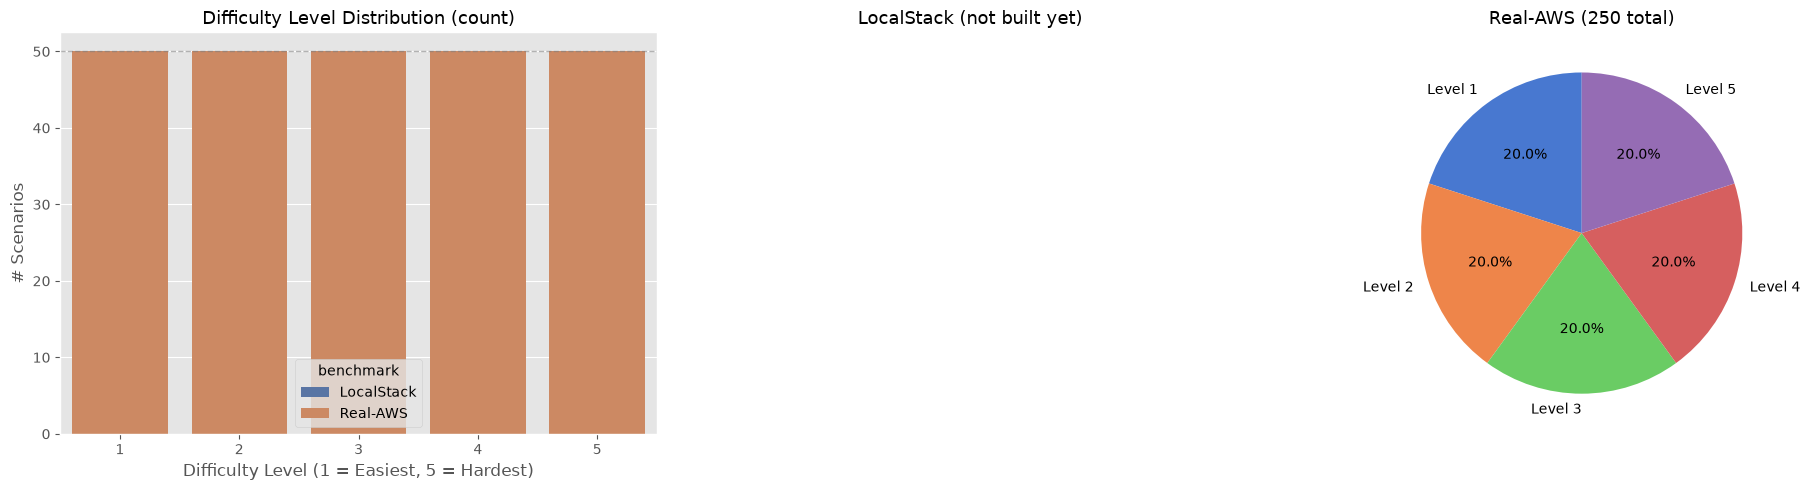

In [5]:
difficulty_criteria = pd.DataFrame({
    'Difficulty Level': [1, 2, 3, 4, 5],
    'LoC (this benchmark)':        ['< 80', '80-149', '150-249', '250-399', '>= 400'],
    '#Resources (this benchmark)': ['< 2',  '2-3',    '4-7',     '8-11',    '>= 12'],
    'LoC (DPIaC-Eval)':            ['< 50', '< 100',  '< 150',   '< 200',   '>= 200'],
    '#Resources (DPIaC-Eval)':     ['< 2',  '< 4',     '< 6',    '< 12',    '>= 12'],
})
display(difficulty_criteria)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.countplot(data=df_compare, x='difficulty', hue='benchmark', hue_order=BENCHMARK_ORDER,
              palette=BENCHMARK_PALETTE, ax=axes[0])
axes[0].set_title('Difficulty Level Distribution (count)', fontsize=13)
axes[0].set_xlabel('Difficulty Level (1 = Easiest, 5 = Hardest)')
axes[0].set_ylabel('# Scenarios')
axes[0].axhline(50, color='gray', linestyle='--', linewidth=1, alpha=0.6)

for ax, bench in zip(axes[1:], BENCHMARK_ORDER):
    d = df_compare[df_compare['benchmark'] == bench]
    if d.empty:
        ax.set_title(f'{bench} (not built yet)', fontsize=13)
        ax.axis('off')
        continue
    counts = d['difficulty'].value_counts().sort_index()
    ax.pie(counts.values, labels=[f'Level {i}' for i in counts.index],
           autopct='%1.1f%%', startangle=90, colors=sns.color_palette('muted'))
    ax.set_title(f'{bench} ({len(d)} total)', fontsize=13)

plt.tight_layout()
plt.show()

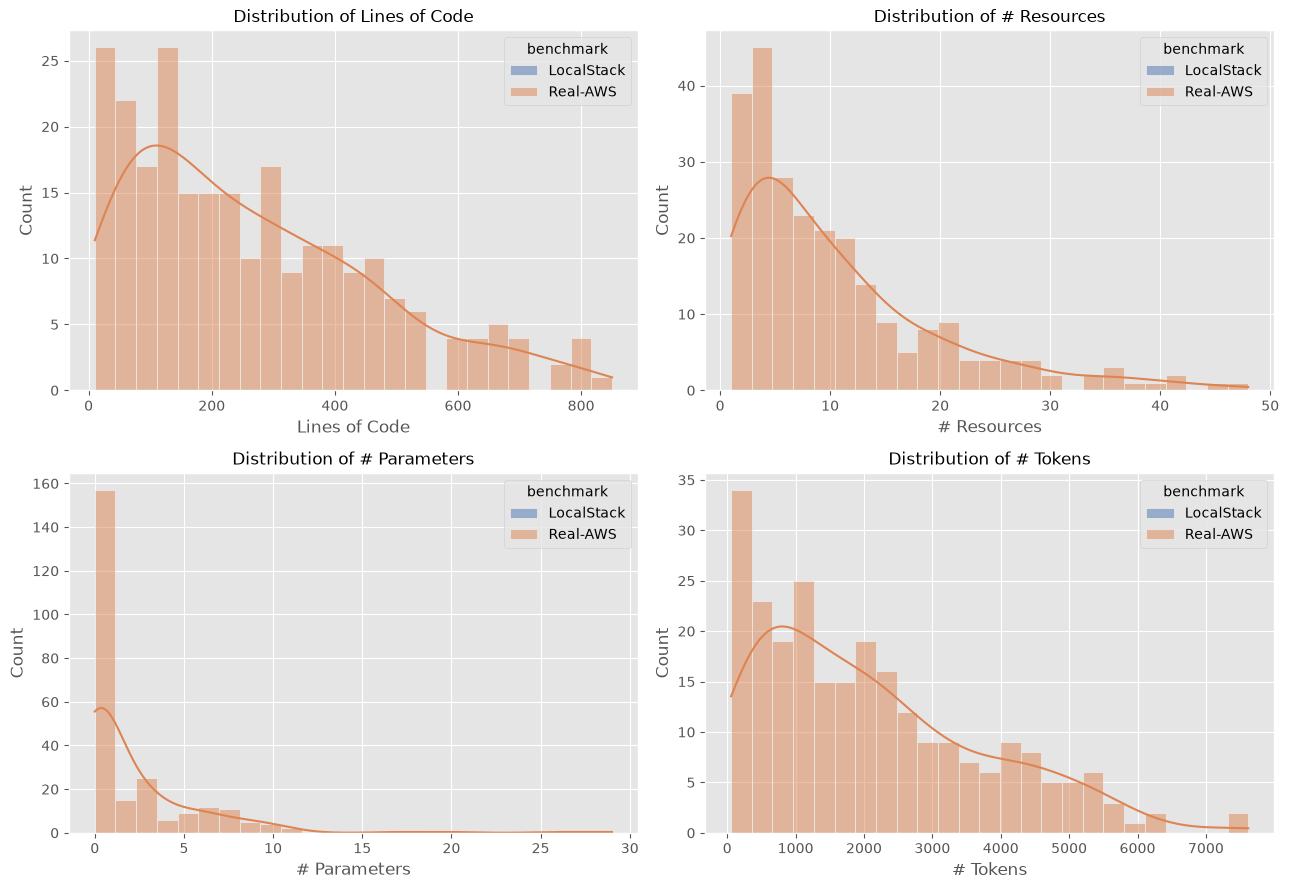

benchmark           Real-AWS
loc          count     250.0
             mean      265.0
             std       198.8
             min        10.0
             25%        97.2
             50%       224.5
             75%       392.0
             max       850.0
n_resources  count     250.0
             mean       10.5
             std         9.4
             min         1.0
             25%         4.0
             50%         8.0
             75%        14.0
             max        48.0
n_parameters count     250.0
             mean        2.3
             std         3.8
             min         0.0
             25%         0.0
             50%         1.0
             75%         3.0
             max        29.0
tokens       count     250.0
             mean     2099.3
             std      1644.6
             min        57.0
             25%       714.5
             50%      1718.5
             75%      3085.2
             max      7619.0


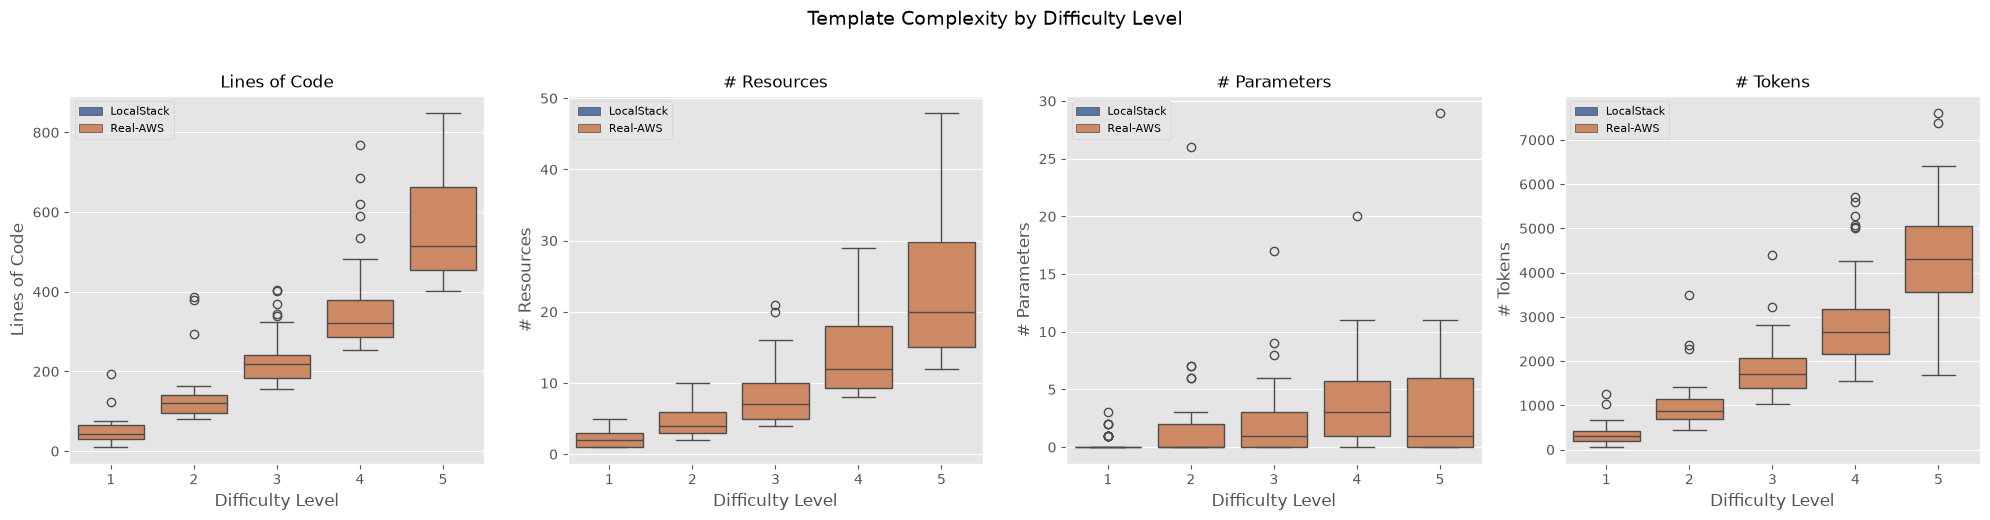

In [6]:
metrics = ['loc', 'n_resources', 'n_parameters', 'tokens']
metric_labels = {'loc': 'Lines of Code', 'n_resources': '# Resources',
                  'n_parameters': '# Parameters', 'tokens': '# Tokens'}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, m in zip(axes.flat, metrics):
    sns.histplot(data=df_compare, x=m, hue='benchmark', hue_order=BENCHMARK_ORDER,
                 palette=BENCHMARK_PALETTE, bins=25, kde=True, ax=ax, alpha=0.5)
    ax.set_title(f'Distribution of {metric_labels[m]}', fontsize=12)
    ax.set_xlabel(metric_labels[m])
plt.tight_layout()
plt.show()

print(df_compare.groupby('benchmark')[metrics].describe().round(1).T.to_string())

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, m in zip(axes, metrics):
    sns.boxplot(data=df_compare, x='difficulty', y=m, hue='benchmark', hue_order=BENCHMARK_ORDER,
                palette=BENCHMARK_PALETTE, ax=ax)
    ax.set_title(metric_labels[m], fontsize=12)
    ax.set_xlabel('Difficulty Level')
    ax.set_ylabel(metric_labels[m])
    ax.legend(fontsize=8)
plt.suptitle('Template Complexity by Difficulty Level', fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

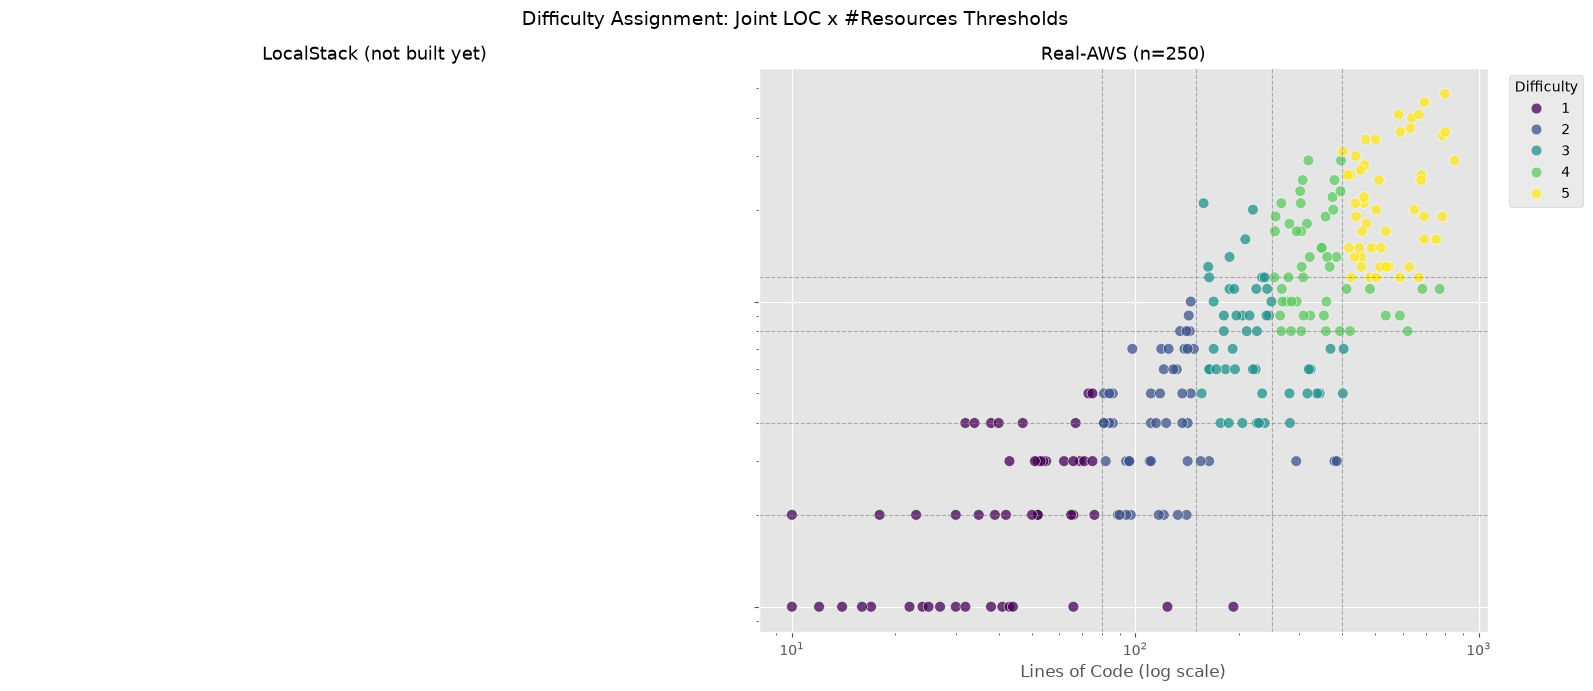

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

thresholds = [(80, 2), (150, 4), (250, 8), (400, 12)]

for i, (ax, bench) in enumerate(zip(axes, BENCHMARK_ORDER)):
    d = df_compare[df_compare['benchmark'] == bench]
    if d.empty:
        ax.set_title(f'{bench} (not built yet)', fontsize=13)
        ax.axis('off')
        continue
    sns.scatterplot(
        data=d, x='loc', y='n_resources', hue='difficulty', palette='viridis',
        s=60, alpha=0.75, edgecolor='white', linewidth=0.5, ax=ax,
        legend='full' if i == len(axes) - 1 else False,
    )
    for loc_t, res_t in thresholds:
        ax.axvline(loc_t, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
        ax.axhline(res_t, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f'{bench} (n={len(d)})', fontsize=13)
    ax.set_xlabel('Lines of Code (log scale)')
    ax.set_ylabel('# Resources (log scale)')

if not df_compare[df_compare['benchmark'] == BENCHMARK_ORDER[-1]].empty:
    axes[-1].legend(title='Difficulty', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.suptitle('Difficulty Assignment: Joint LOC x #Resources Thresholds', fontsize=14)
plt.tight_layout()
plt.show()

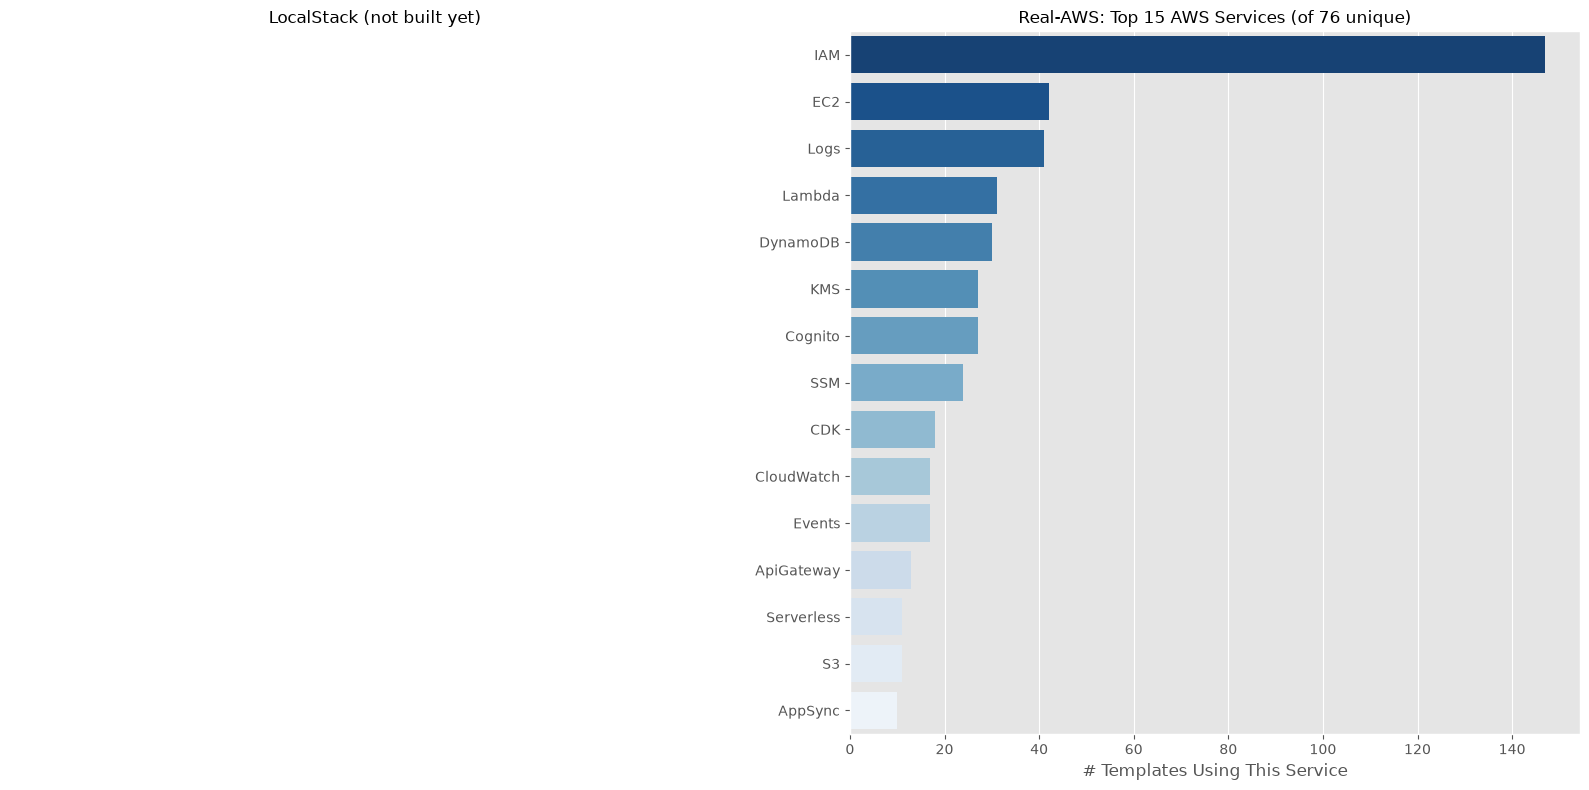

Real-AWS: 76 unique AWS services, avg 2.4 services/template


In [8]:
n_unique_services_by_bench = {}

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, bench in zip(axes, BENCHMARK_ORDER):
    d = df_compare[df_compare['benchmark'] == bench]
    if d.empty:
        ax.set_title(f'{bench} (not built yet)', fontsize=12)
        ax.axis('off')
        n_unique_services_by_bench[bench] = 0
        continue
    service_counter = Counter()
    for services in d['aws_services'].dropna():
        for svc in str(services).split(', '):
            if svc:
                service_counter[svc] += 1
    n_unique_services_by_bench[bench] = len(service_counter)
    top_services = pd.DataFrame(service_counter.most_common(15), columns=['Service', 'Templates'])
    sns.barplot(data=top_services, y='Service', x='Templates', hue='Service',
                palette='Blues_r', legend=False, ax=ax)
    ax.set_title(f'{bench}: Top 15 AWS Services (of {len(service_counter)} unique)', fontsize=12)
    ax.set_xlabel('# Templates Using This Service')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

for bench in BENCHMARK_ORDER:
    d = df_compare[df_compare['benchmark'] == bench]
    if d.empty:
        continue
    avg_services = d['aws_services'].dropna().apply(lambda s: len(str(s).split(', '))).mean()
    print(f'{bench}: {n_unique_services_by_bench[bench]} unique AWS services, '
          f'avg {avg_services:.1f} services/template')

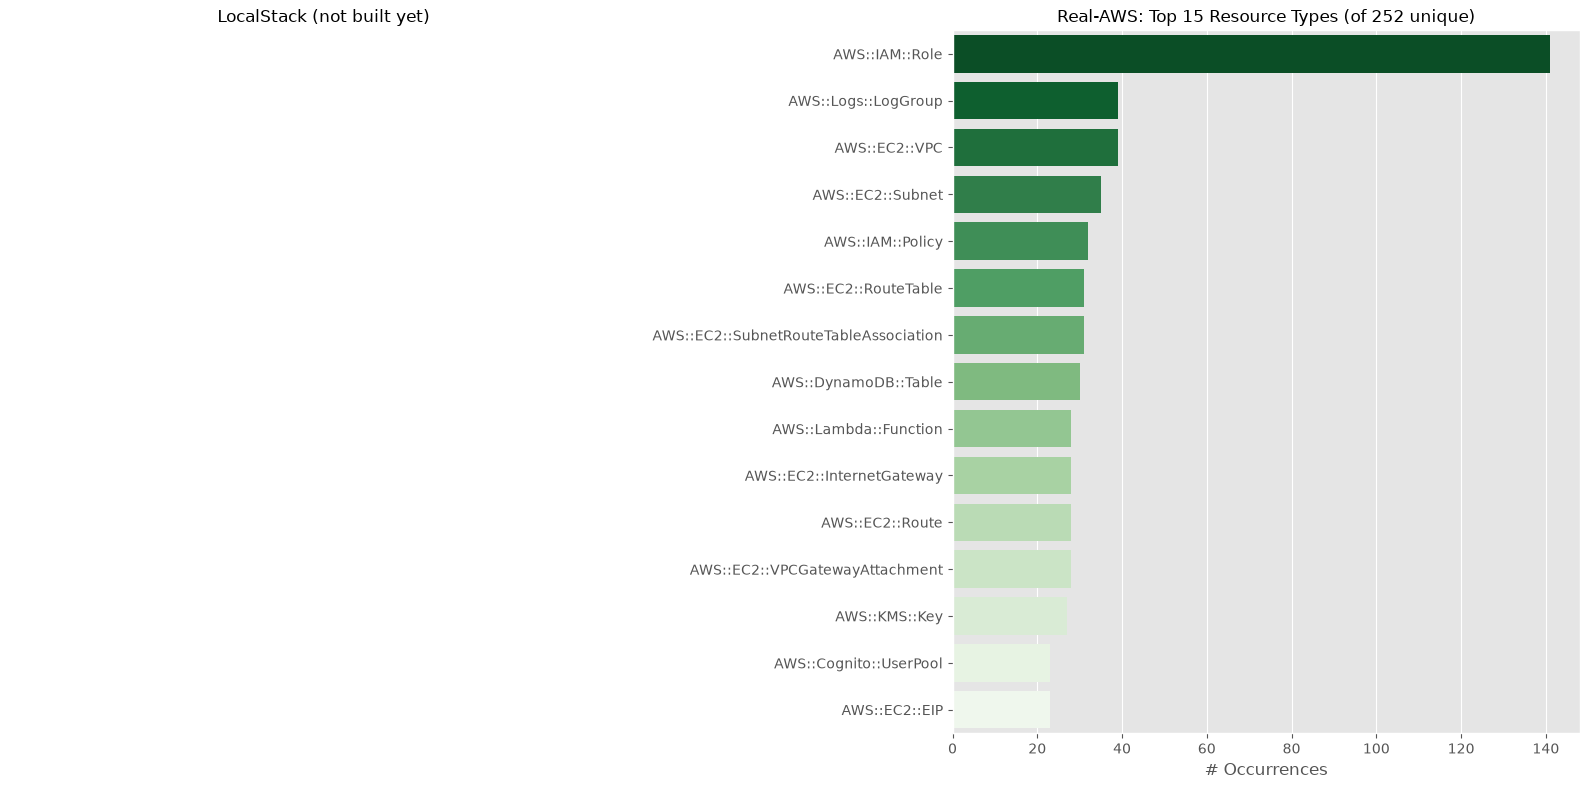

LocalStack: 0 unique CFN resource types represented
Real-AWS: 252 unique CFN resource types represented


In [9]:
n_unique_types_by_bench = {}

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, bench in zip(axes, BENCHMARK_ORDER):
    d = df_compare[df_compare['benchmark'] == bench]
    if d.empty:
        ax.set_title(f'{bench} (not built yet)', fontsize=12)
        ax.axis('off')
        n_unique_types_by_bench[bench] = 0
        continue
    resource_type_counter = Counter()
    for types in d['resource_types'].dropna():
        for rtype in str(types).split(' | '):
            if rtype:
                resource_type_counter[rtype] += 1
    n_unique_types_by_bench[bench] = len(resource_type_counter)
    top_types = pd.DataFrame(resource_type_counter.most_common(15), columns=['Resource Type', 'Count'])
    sns.barplot(data=top_types, y='Resource Type', x='Count', hue='Resource Type',
                palette='Greens_r', legend=False, ax=ax)
    ax.set_title(f'{bench}: Top 15 Resource Types (of {len(resource_type_counter)} unique)', fontsize=12)
    ax.set_xlabel('# Occurrences')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

for bench in BENCHMARK_ORDER:
    print(f'{bench}: {n_unique_types_by_bench[bench]} unique CFN resource types represented')

In [ ]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

CFN_FINAL_CSV = Path('cfn_benchmark/dataset/final_benchmark_real_aws_with_prompts.csv')
TF_FINAL_CSV = Path('iac_benchmark/dataset/final_benchmark_real_aws_with_prompts.csv')
TF_REGISTRY_DOCS = Path('../tf_registry_docs.json')
TOP_N = 12

_registry = json.loads(TF_REGISTRY_DOCS.read_text())
TF_TYPE_TO_SERVICE = {k: v['subcategory'] for k, v in _registry.items() if v.get('subcategory')}

SERVICE_ALIAS = {
    'Logs': 'CloudWatch Logs', 'Events': 'EventBridge', 'Cognito IDP': 'Cognito',
    'Cognito Identity': 'Cognito', 'ApiGateway': 'API Gateway', 'ApiGatewayV2': 'API Gateway V2',
    'StepFunctions': 'SFN', 'SecretsManager': 'Secrets Manager', 'Route53': 'Route 53',
    'ElasticLoadBalancingV2': 'ELB', 'ELB Classic': 'ELB',
}
SAM_TO_SERVICE = {
    'Function': 'Lambda', 'LayerVersion': 'Lambda', 'Api': 'API Gateway',
    'HttpApi': 'API Gateway V2', 'SimpleTable': 'DynamoDB', 'StateMachine': 'SFN',
}
RESOURCE_ALIAS = {
    'AWS::Logs::LogGroup': 'aws_cloudwatch_log_group',
    'AWS::EC2::SubnetRouteTableAssociation': 'aws_route_table_association',
    'AWS::EC2::VPCGatewayAttachment': 'aws_internet_gateway',
    'AWS::IAM::ManagedPolicy': 'aws_iam_policy',
    'AWS::IAM::Policy': 'aws_iam_role_policy',
    'AWS::IAM::RolePolicy': 'aws_iam_role_policy',
}
EXCLUDED_NAMESPACES = {'CDK', 'CloudFormation'}
RESOURCE_LABELS = {
    'aws_iam_role': 'IAM role', 'aws_vpc': 'VPC', 'aws_iam_policy': 'Managed policy',
    'aws_iam_role_policy': 'Inline policy', 'aws_subnet': 'Subnet',
    'aws_route_table': 'Route table', 'aws_internet_gateway': 'Internet gateway',
    'aws_kms_key': 'KMS key', 'aws_route_table_association': 'Route table assoc.',
    'aws_security_group': 'Security group', 'aws_iam_role_policy_attachment': 'Role policy attach.',
    'aws_eip': 'Elastic IP', 'aws_route': 'Route', 'aws_cloudwatch_log_group': 'Log group',
    'aws_nat_gateway': 'NAT gateway', 'aws_s3_bucket': 'S3 bucket',
    'aws_dynamodb_table': 'DynamoDB table', 'aws_lambda_function': 'Lambda function',
    'aws_iam_instance_profile': 'Instance profile',
}


def _snake(name):
    return re.sub(r'(?<=[a-z0-9])(?=[A-Z])|(?<=[A-Z])(?=[A-Z][a-z])', '_', name).lower()


def _short_service(subcategory):
    label = re.sub(r'\s*\(.*\)$', '', subcategory).strip()
    return SERVICE_ALIAS.get(label, label)


def cfn_to_tf_type(cfn_type):
    if cfn_type in RESOURCE_ALIAS:
        return RESOURCE_ALIAS[cfn_type]
    m = re.match(r'AWS::(\w+)::(\w+)$', cfn_type)
    if not m:
        return cfn_type
    ns, rt = m.groups()
    for cand in (f'aws_{_snake(ns)}_{_snake(rt)}', f'aws_{_snake(rt)}'):
        if cand in TF_TYPE_TO_SERVICE:
            return cand
    return cfn_type


def cfn_service(cfn_type):
    m = re.match(r'AWS::(\w+)::(\w+)$', cfn_type)
    if not m:
        return None
    ns, rt = m.groups()
    if ns in EXCLUDED_NAMESPACES:
        return None
    if ns == 'Serverless':
        return SAM_TO_SERVICE.get(rt, 'Lambda')
    tf_type = cfn_to_tf_type(cfn_type)
    if tf_type in TF_TYPE_TO_SERVICE:
        return _short_service(TF_TYPE_TO_SERVICE[tf_type])
    if ns == 'EC2':
        return 'VPC'
    return SERVICE_ALIAS.get(ns, ns)


def tf_resource_types(folder_path):
    types = set()
    for tf_file in Path(folder_path).glob('*.tf'):
        text = tf_file.read_text(encoding='utf-8', errors='ignore')
        types.update(re.findall(r'resource\s+"(aws_[a-zA-Z0-9_]+)"', text))
    return types


df_cfn_final = pd.read_csv(CFN_FINAL_CSV)
df_tf_final = pd.read_csv(TF_FINAL_CSV)

cfn_type_sets = [{t for t in str(s).split(' | ') if t} for s in df_cfn_final['resource_types'].fillna('')]
tf_type_sets = [tf_resource_types(fp) for fp in df_tf_final['folder_path']]

cfn_services = Counter(s for types in cfn_type_sets for s in {cfn_service(t) for t in types} - {None})
tf_services = Counter(s for types in tf_type_sets
                      for s in {_short_service(TF_TYPE_TO_SERVICE[t]) if t in TF_TYPE_TO_SERVICE else t
                                for t in types})
cfn_types_matched = Counter(t for types in cfn_type_sets for t in {cfn_to_tf_type(x) for x in types})
tf_types = Counter(t for types in tf_type_sets for t in types)

n_cfn, n_tf = len(df_cfn_final), len(df_tf_final)
print(f'CFN: {len(cfn_services)} services, '
      f'{len({t for s in cfn_type_sets for t in s})} resource types ({n_cfn} templates)')
print(f'TF : {len(tf_services)} services, {len(tf_types)} resource types ({n_tf} templates)')
print(f'Services in both: {len(set(cfn_services) & set(tf_services))}, '
      f'in either: {len(set(cfn_services) | set(tf_services))}')

top_services = [s for s, _ in (cfn_services + tf_services).most_common(TOP_N)]
_type_totals = Counter({t: cfn_types_matched[t] + tf_types[t] for t in set(cfn_types_matched) | set(tf_types)})
top_types = [t for t, _ in _type_totals.most_common(TOP_N)]

df_services_cmp = pd.DataFrame({
    'service': top_services,
    'cfn_pct': [100 * cfn_services[s] / n_cfn for s in top_services],
    'tf_pct': [100 * tf_services[s] / n_tf for s in top_services],
})
df_types_cmp = pd.DataFrame({
    'resource_type': top_types,
    'label': [RESOURCE_LABELS.get(t, t) for t in top_types],
    'cfn_pct': [100 * cfn_types_matched[t] / n_cfn for t in top_types],
    'tf_pct': [100 * tf_types[t] / n_tf for t in top_types],
})
display(df_services_cmp.round(1))
display(df_types_cmp.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, df_cmp, label_col, title in [
    (axes[0], df_services_cmp, 'service', 'AWS services'),
    (axes[1], df_types_cmp, 'label', 'Resource types'),
]:
    y = range(len(df_cmp))
    ax.barh([i - 0.2 for i in y], df_cmp['cfn_pct'], height=0.4, label='CloudFormation', color='#6f7fe0')
    ax.barh([i + 0.2 for i in y], df_cmp['tf_pct'], height=0.4, label='Terraform', color='#f5a142')
    ax.set_yticks(list(y))
    ax.set_yticklabels(df_cmp[label_col])
    ax.invert_yaxis()
    ax.set_xlabel('% of templates')
    ax.set_title(f'Top {TOP_N} {title}')
axes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

def _pgf(values):
    return ' '.join(f'({v:.1f},{i})' for i, v in enumerate(values))

print('\n% (a) services yticklabels={' + ', '.join(df_services_cmp['service']) + '}')
print('%   CFN: ' + _pgf(df_services_cmp['cfn_pct']))
print('%   TF : ' + _pgf(df_services_cmp['tf_pct']))
print('% (b) resource types yticklabels={' + ', '.join(df_types_cmp['label']) + '}')
print('%   CFN: ' + _pgf(df_types_cmp['cfn_pct']))
print('%   TF : ' + _pgf(df_types_cmp['tf_pct']))

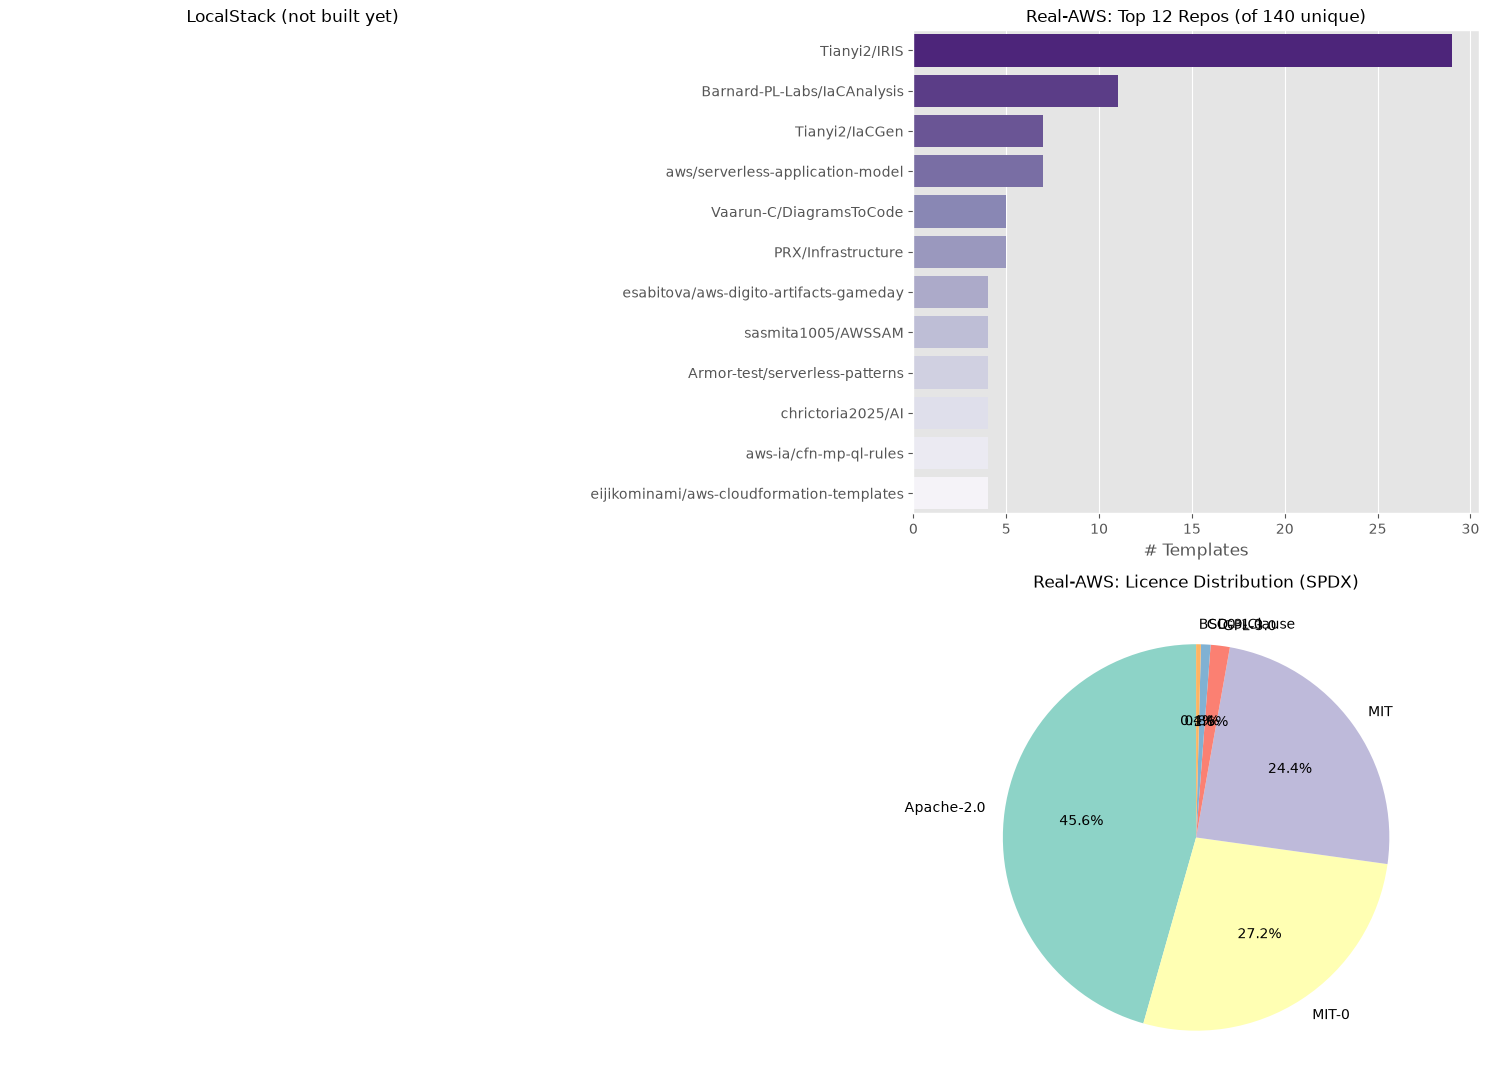

Real-AWS: 140 unique source repositories, max 29 templates from a single repo (Tianyi2/IRIS)


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

for col, bench in enumerate(BENCHMARK_ORDER):
    d = df_compare[df_compare['benchmark'] == bench]
    ax_repo, ax_lic = axes[0][col], axes[1][col]
    if d.empty:
        ax_repo.set_title(f'{bench} (not built yet)', fontsize=12)
        ax_repo.axis('off')
        ax_lic.axis('off')
        continue

    top_repos = d['source_slug'].value_counts().head(12)
    sns.barplot(y=top_repos.index, x=top_repos.values, hue=top_repos.index,
                ax=ax_repo, palette='Purples_r', legend=False)
    ax_repo.set_title(f'{bench}: Top 12 Repos (of {d["source_slug"].nunique()} unique)', fontsize=12)
    ax_repo.set_xlabel('# Templates')
    ax_repo.set_ylabel('')

    licence_counts = d['licence_spdx'].value_counts()
    ax_lic.pie(licence_counts.values, labels=licence_counts.index, autopct='%1.1f%%',
               startangle=90, colors=sns.color_palette('Set3'))
    ax_lic.set_title(f'{bench}: Licence Distribution (SPDX)', fontsize=12)

plt.tight_layout()
plt.show()

for bench in BENCHMARK_ORDER:
    d = df_compare[df_compare['benchmark'] == bench]
    if d.empty:
        continue
    print(f'{bench}: {d["source_slug"].nunique()} unique source repositories, '
          f'max {d["source_slug"].value_counts().max()} templates from a single repo '
          f'({d["source_slug"].value_counts().idxmax()})')

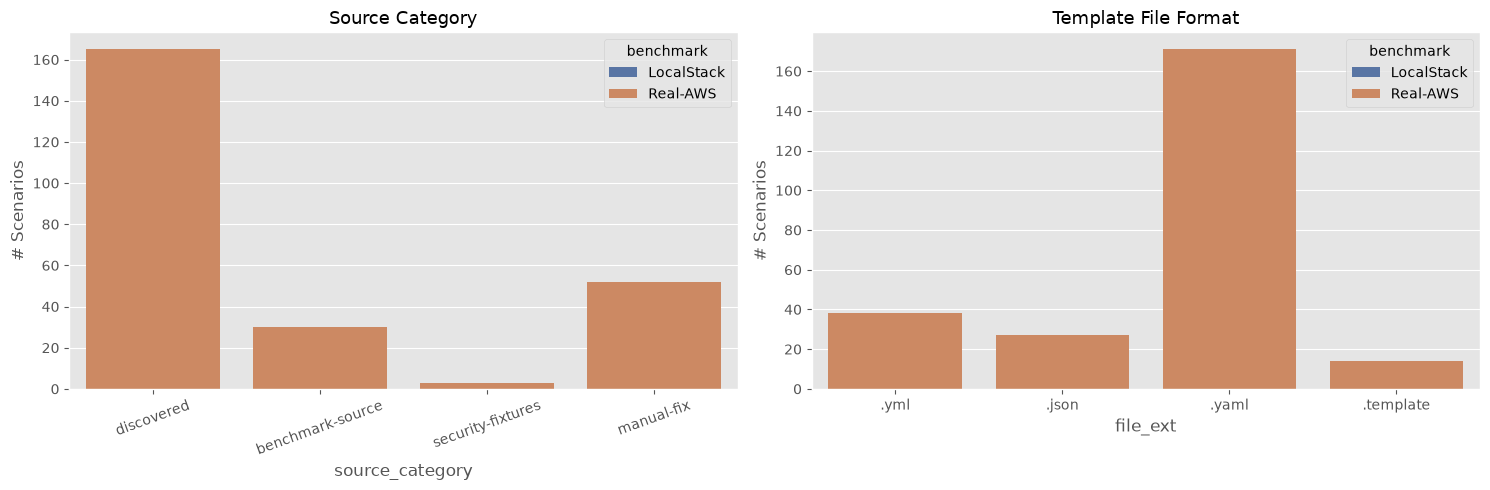

source_category breakdown by benchmark:
source_category  benchmark-source  discovered  manual-fix  security-fixtures
benchmark                                                                   
LocalStack                    NaN         NaN         NaN                NaN
Real-AWS                     30.0       165.0        52.0                3.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=df_compare, x='source_category', hue='benchmark', hue_order=BENCHMARK_ORDER,
              palette=BENCHMARK_PALETTE, ax=axes[0])
axes[0].set_title('Source Category', fontsize=13)
axes[0].set_ylabel('# Scenarios')
axes[0].tick_params(axis='x', rotation=20)

sns.countplot(data=df_compare, x='file_ext', hue='benchmark', hue_order=BENCHMARK_ORDER,
              palette=BENCHMARK_PALETTE, ax=axes[1])
axes[1].set_title('Template File Format', fontsize=13)
axes[1].set_ylabel('# Scenarios')

plt.tight_layout()
plt.show()

print('source_category breakdown by benchmark:')
print(df_compare.groupby('benchmark')['source_category'].value_counts().unstack().reindex(BENCHMARK_ORDER).to_string())

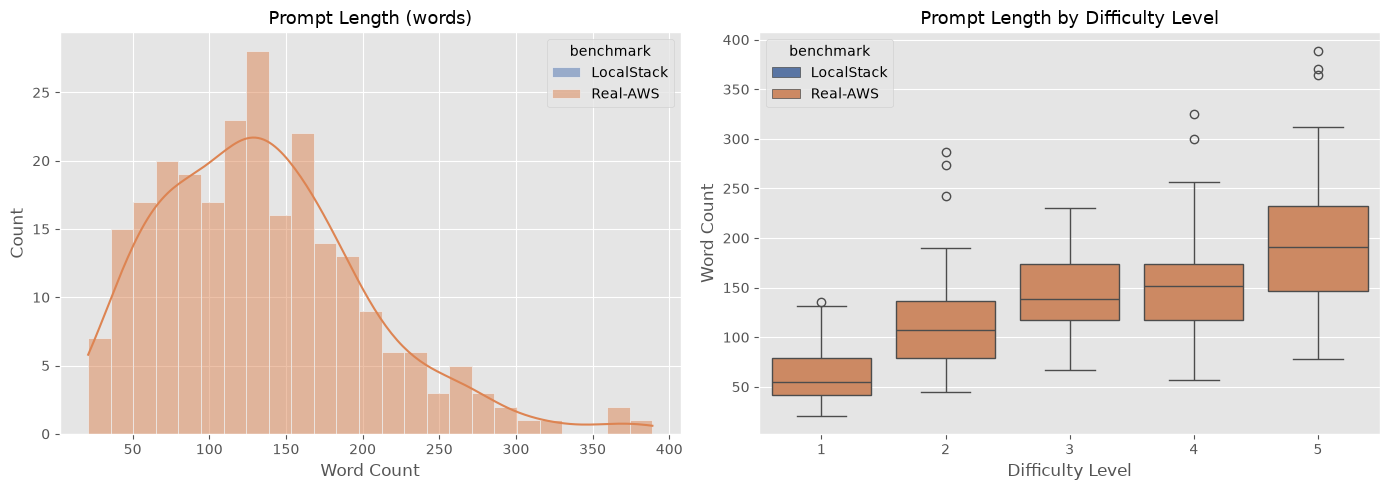


Real-AWS (0 scenario(s) still missing a prompt):
       prompt_word_count  prompt_char_count
count              250.0              250.0
mean               134.3              899.1
std                 67.6              466.0
min                 21.0              155.0
25%                 82.2              555.5
50%                128.0              854.0
75%                172.8             1165.2
max                389.0             2692.0


In [12]:
_has_prompt = df_compare['has_prompt']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df_compare[_has_prompt], x='prompt_word_count', hue='benchmark',
             hue_order=BENCHMARK_ORDER, palette=BENCHMARK_PALETTE, bins=25, kde=True,
             ax=axes[0], alpha=0.5)
axes[0].set_title('Prompt Length (words)', fontsize=13)
axes[0].set_xlabel('Word Count')

sns.boxplot(data=df_compare[_has_prompt], x='difficulty', y='prompt_word_count', hue='benchmark',
            hue_order=BENCHMARK_ORDER, palette=BENCHMARK_PALETTE, ax=axes[1])
axes[1].set_title('Prompt Length by Difficulty Level', fontsize=13)
axes[1].set_xlabel('Difficulty Level')
axes[1].set_ylabel('Word Count')

plt.tight_layout()
plt.show()

for bench in BENCHMARK_ORDER:
    d = df_compare[(df_compare['benchmark'] == bench) & _has_prompt]
    if d.empty:
        continue
    n_missing = (df_compare['benchmark'] == bench).sum() - len(d)
    print(f'\n{bench} ({n_missing} scenario(s) still missing a prompt):')
    print(d[['prompt_word_count', 'prompt_char_count']].describe().round(1).to_string())

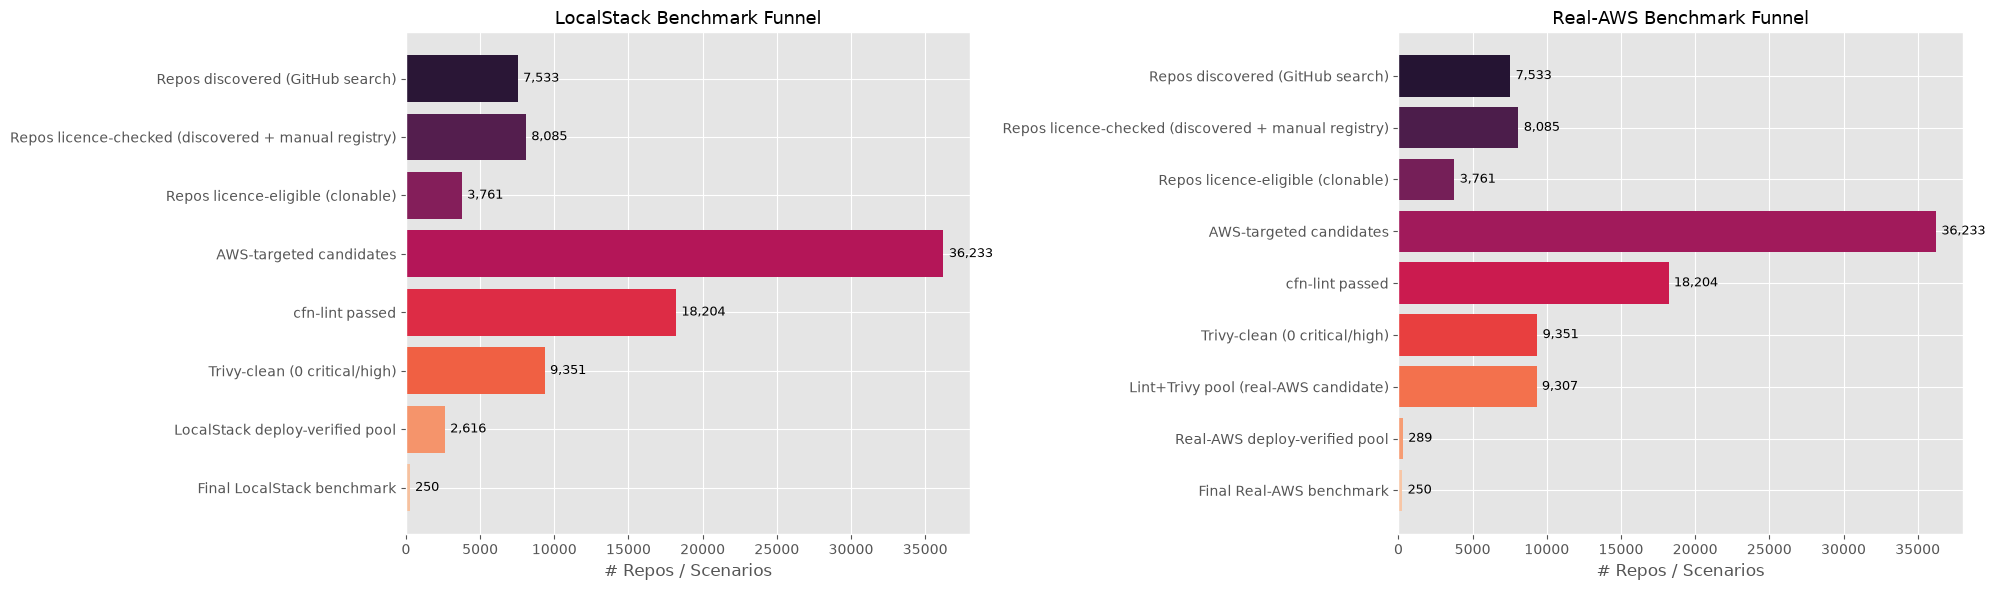

LocalStack overall yield: 250 / 36,233 = 0.7% of AWS-targeted candidates.
Real-AWS overall yield:   250 / 36,233 = 0.7% of AWS-targeted candidates.
Repo-to-benchmark yield: 250 LocalStack / 250 Real-AWS scenarios drawn from 7,533 discovered repos (3,761 licence-eligible).


In [13]:
import json

DISCOVERED_REPOS_CACHE_FUNNEL = DATASET_DIR / 'discovered_repos_cache.json'
LICENCE_CACHE_FUNNEL = DATASET_DIR / 'licence_cache.csv'

repo_stages = []
if DISCOVERED_REPOS_CACHE_FUNNEL.exists():
    with open(DISCOVERED_REPOS_CACHE_FUNNEL, 'r', encoding='utf-8') as _f:
        repo_stages.append(('Repos discovered (GitHub search)', len(json.load(_f))))
if LICENCE_CACHE_FUNNEL.exists():
    _licence_df_funnel = pd.read_csv(LICENCE_CACHE_FUNNEL, low_memory=False)
    repo_stages.append(('Repos licence-checked (discovered + manual registry)', len(_licence_df_funnel)))
    repo_stages.append(('Repos licence-eligible (clonable)',
                         int((_licence_df_funnel['eligible'] == True).sum())))

AWS_CACHE_PATH = DATASET_DIR / 'df_aws_cache.csv'
LINT_CACHE_PATH = DATASET_DIR / 'lint_cache.csv'
SEC_CACHE_PATH = DATASET_DIR / 'security_cache.csv'
LOCALSTACK_DEPLOY_POOL_PATH = DATASET_DIR / 'cfn_benchmark.csv'

shared_stages = list(repo_stages)
_n_aws_targeted_funnel = None
if AWS_CACHE_PATH.exists():
    df_aws_funnel = pd.read_csv(AWS_CACHE_PATH, low_memory=False)
    _n_aws_targeted_funnel = len(df_aws_funnel)
    shared_stages.append(('AWS-targeted candidates', len(df_aws_funnel)))

    if LINT_CACHE_PATH.exists():
        lint_funnel = pd.read_csv(LINT_CACHE_PATH, low_memory=False)[['content_hash', 'lint_pass']].drop_duplicates('content_hash')
        m = df_aws_funnel.merge(lint_funnel, on='content_hash', how='left')
        lint_passed = m[m['lint_pass'] == True]
        shared_stages.append(('cfn-lint passed', len(lint_passed)))

        if SEC_CACHE_PATH.exists():
            sec_funnel = pd.read_csv(SEC_CACHE_PATH, low_memory=False)[
                ['content_hash', 'trivy_critical', 'trivy_high']].drop_duplicates('content_hash')
            m2 = lint_passed.merge(sec_funnel, on='content_hash', how='left')
            sec_clean = m2[(m2['trivy_critical'].fillna(-1) == 0) & (m2['trivy_high'].fillna(-1) == 0)]
            shared_stages.append(('Trivy-clean (0 critical/high)', len(sec_clean)))

localstack_stages = list(shared_stages)
if LOCALSTACK_DEPLOY_POOL_PATH.exists():
    localstack_pool = pd.read_csv(LOCALSTACK_DEPLOY_POOL_PATH, low_memory=False)
    localstack_stages.append(('LocalStack deploy-verified pool', len(localstack_pool)))
localstack_stages.append(('Final LocalStack benchmark', len(df_localstack)))

REAL_AWS_POOL_CSV_FUNNEL = DATASET_DIR / 'real_aws_candidate_pool.csv'
GT_DEPLOY_CACHE_PATH_FUNNEL = DATASET_DIR / 'ground_truth_deploy_check_aws.csv'

real_aws_stages = list(shared_stages)
if REAL_AWS_POOL_CSV_FUNNEL.exists():
    real_aws_pool_funnel = pd.read_csv(REAL_AWS_POOL_CSV_FUNNEL, low_memory=False)
    real_aws_stages.append(('Lint+Trivy pool (real-AWS candidate)', len(real_aws_pool_funnel)))
    if GT_DEPLOY_CACHE_PATH_FUNNEL.exists():
        gt_funnel = pd.read_csv(GT_DEPLOY_CACHE_PATH_FUNNEL)[['content_hash', 'deploy_pass']].drop_duplicates('content_hash')
        real_aws_deploy_verified = real_aws_pool_funnel.merge(gt_funnel, on='content_hash', how='inner')
        real_aws_deploy_verified = real_aws_deploy_verified[real_aws_deploy_verified['deploy_pass'] == True]
        real_aws_stages.append(('Real-AWS deploy-verified pool', len(real_aws_deploy_verified)))
real_aws_stages.append(('Final Real-AWS benchmark', len(df_real_aws)))

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for ax, stages, title in zip(
    axes, [localstack_stages, real_aws_stages],
    ['LocalStack Benchmark Funnel', 'Real-AWS Benchmark Funnel'],
):
    funnel_df = pd.DataFrame(stages, columns=['Stage', 'Count'])
    bars = ax.barh(funnel_df['Stage'], funnel_df['Count'], color=sns.color_palette('rocket', len(funnel_df)))
    ax.invert_yaxis()
    ax.set_xlabel('# Repos / Scenarios')
    ax.set_title(title, fontsize=13)
    for bar, count in zip(bars, funnel_df['Count']):
        ax.text(bar.get_width() + max(funnel_df['Count']) * 0.01, bar.get_y() + bar.get_height() / 2,
                 f'{count:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

if _n_aws_targeted_funnel:
    ls_yield = len(df_localstack) / _n_aws_targeted_funnel
    print(f'LocalStack overall yield: {len(df_localstack):,} / {_n_aws_targeted_funnel:,} = {ls_yield:.1%} '
          f'of AWS-targeted candidates.')
    if len(df_real_aws):
        ra_yield = len(df_real_aws) / _n_aws_targeted_funnel
        print(f'Real-AWS overall yield:   {len(df_real_aws):,} / {_n_aws_targeted_funnel:,} = {ra_yield:.1%} '
              f'of AWS-targeted candidates.')
if repo_stages:
    print(f'Repo-to-benchmark yield: {len(df_localstack):,} LocalStack / {len(df_real_aws):,} Real-AWS scenarios '
          f'drawn from {repo_stages[0][1]:,} discovered repos '
          f'({repo_stages[-1][1]:,} licence-eligible).')

,Stage,Templates
0,Collected templates (repos + DPIaC-Eval + Mult...,NaN
1,Unique normalised contents,NaN
2,Size-filtered (LoC/tokens/resources/params),NaN
3,AWS-targeted,NaN
4,Deduplicated,NaN
5,cfn-lint passed,NaN
6,Trivy-clean (0 critical/high),NaN
7,LocalStack deploy-passed (informational),NaN
8,Real-AWS candidate pool (after exclusions),NaN
9,Real-AWS deploy-passed,NaN


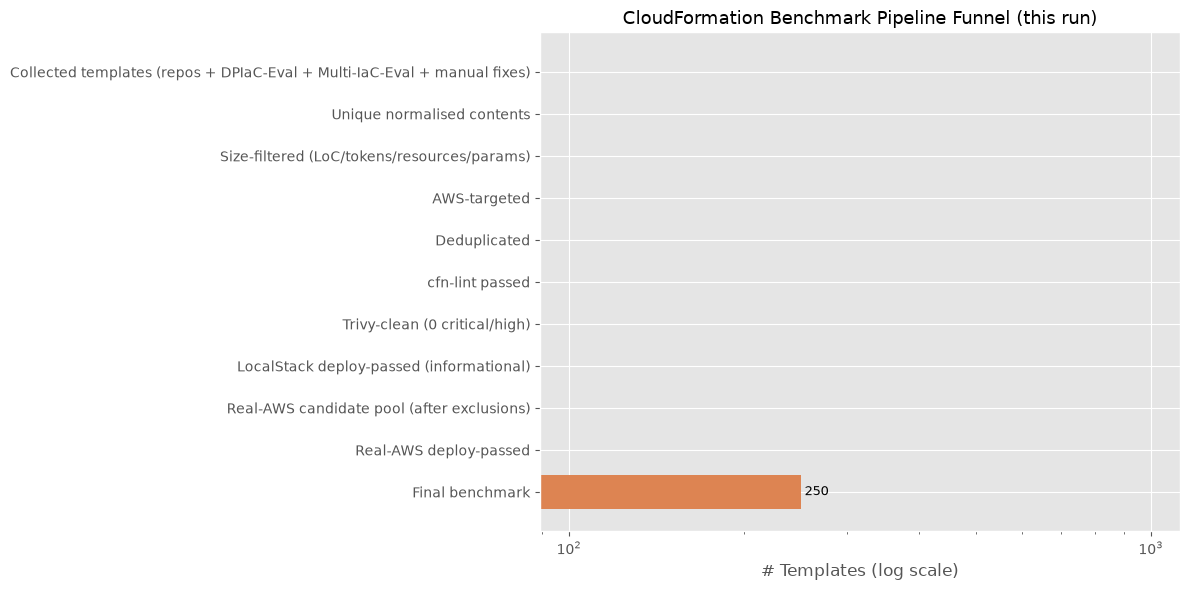

In [14]:
def _n(name, fn):
    return fn(globals()[name]) if name in globals() and isinstance(globals()[name], pd.DataFrame) else np.nan


_gt_all = pd.read_csv(GT_DEPLOY_CACHE_PATH, usecols=['content_hash', 'deploy_pass']) if GT_DEPLOY_CACHE_PATH.exists() else pd.DataFrame(columns=['content_hash', 'deploy_pass'])
_ls_all = pd.read_csv(LOCALSTACK_DEPLOY_CACHE, usecols=['content_hash', 'deploy_pass']) if LOCALSTACK_DEPLOY_CACHE.exists() else pd.DataFrame(columns=['content_hash', 'deploy_pass'])
_pool_hashes = set(df_pool['content_hash']) if 'df_pool' in globals() else set()
funnel_run = pd.DataFrame([
    ('Collected templates (repos + DPIaC-Eval + Multi-IaC-Eval + manual fixes)', _n('df_raw', len)),
    ('Unique normalised contents',                  _n('df_raw', lambda d: d['content_hash'].nunique())),
    ('Size-filtered (LoC/tokens/resources/params)', _n('df_sized', len)),
    ('AWS-targeted',                                _n('df_sized', lambda d: int(d['is_aws_target'].sum())) if 'is_aws_target' in globals().get('df_sized', pd.DataFrame()).columns else np.nan),
    ('Deduplicated',                                _n('df_aws', len)),
    ('cfn-lint passed',                             _n('df_linted', lambda d: int((d['lint_pass'] == True).sum()))),
    ('Trivy-clean (0 critical/high)',               _n('df_deploy_ready', len)),
    ('LocalStack deploy-passed (informational)',    int(_ls_all.loc[_ls_all['content_hash'].isin(_pool_hashes), 'deploy_pass'].eq(True).sum()) if _pool_hashes else np.nan),
    ('Real-AWS candidate pool (after exclusions)',  len(_pool_hashes) or np.nan),
    ('Real-AWS deploy-passed',                      int(_gt_all.loc[_gt_all['content_hash'].isin(_pool_hashes), 'deploy_pass'].eq(True).sum()) if _pool_hashes else np.nan),
    ('Final benchmark',                             len(df_real_aws)),
], columns=['Stage', 'Templates'])
display(funnel_run)

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(funnel_run['Stage'][::-1], funnel_run['Templates'].fillna(0)[::-1], color=BENCHMARK_PALETTE['Real-AWS'])
ax.set_xscale('log')
ax.set_xlabel('# Templates (log scale)')
ax.set_title('CloudFormation Benchmark Pipeline Funnel (this run)', fontsize=13)
for i, v in enumerate(funnel_run['Templates'].fillna(0)[::-1]):
    if v:
        ax.text(v, i, f' {int(v):,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

,Benchmark,Scenarios,Avg LoC,Avg # Resources,AWS Services,Difficulty Levels
0,This benchmark (LocalStack),250,269.1,10.3,0,5.0
1,This benchmark (Real-AWS),250,265.0,10.5,76,5.0
2,DPIaC-Eval,153,155.0,7.0,58,5.0
3,IaC-Eval,458,42.0,4.0,~60,6.0
4,Multi-IaC-Eval (CFN),263,168.8,7.3,47,NaN


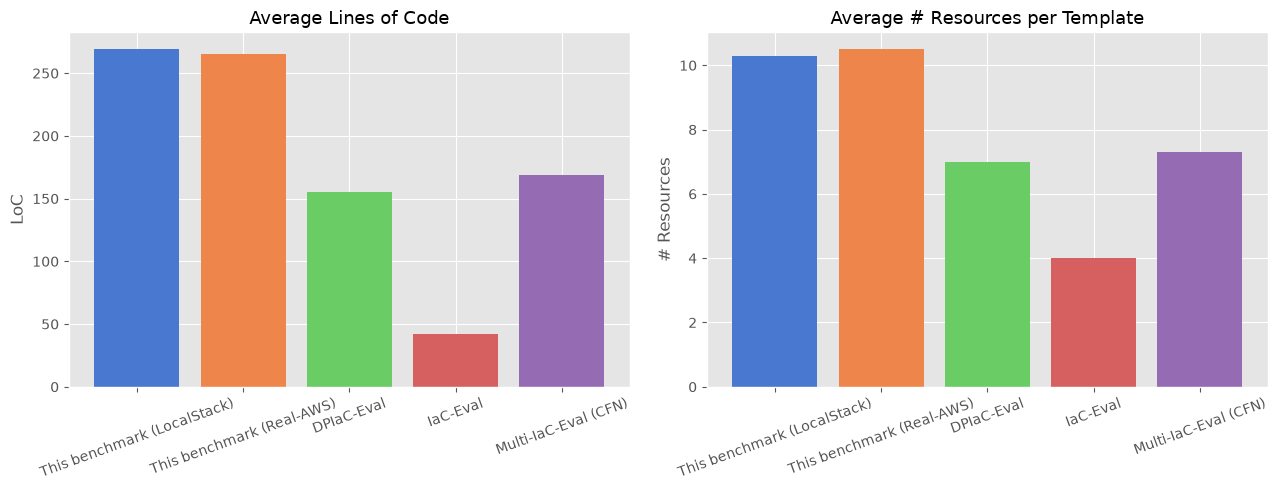

In [15]:
MULTI_IAC_EVAL_CACHE_PATH = DATASET_DIR / 'multi_iac_eval_cache.json'
multi_iac_eval_stats = {'Scenarios': None, 'Avg LoC': None, 'Avg # Resources': None, 'AWS Services': None}

if MULTI_IAC_EVAL_CACHE_PATH.exists():
    import json as _json
    import yaml as _yaml
    import hashlib as _hashlib

    class _CfnYamlLoader(_yaml.SafeLoader):
        pass

    def _cfn_multi_constructor(loader, tag_suffix, node):
        key = tag_suffix if tag_suffix == 'Ref' else f'Fn::{tag_suffix}'
        if isinstance(node, _yaml.ScalarNode):
            value = loader.construct_scalar(node)
            if key == 'Fn::GetAtt' and isinstance(value, str) and '.' in value:
                value = value.split('.')
        elif isinstance(node, _yaml.SequenceNode):
            value = loader.construct_sequence(node)
        else:
            value = loader.construct_mapping(node)
        return {key: value}

    _CfnYamlLoader.add_multi_constructor('!', _cfn_multi_constructor)

    def _parse_cfn_content_for_comparison(content):
        for loader in (_json.loads, lambda c: _yaml.load(c, Loader=_CfnYamlLoader)):
            try:
                parsed = loader(content)
                if isinstance(parsed, dict):
                    return parsed
            except Exception:
                continue
        return None

    _AWS_SERVICE_RE = re.compile(r'^AWS::([A-Za-z0-9]+)::')

    with open(MULTI_IAC_EVAL_CACHE_PATH, 'r', encoding='utf-8') as f:
        _multi_iac_eval_raw = _json.load(f)

    if _multi_iac_eval_raw:
        _mie_locs = []
        _mie_n_resources = []
        _mie_svc_counter = Counter()
        for _rec in _multi_iac_eval_raw:
            _content = _rec.get('content') or ''
            _mie_locs.append(_content.count('\n') + 1)
            _parsed = _parse_cfn_content_for_comparison(_content)
            _resources = (_parsed or {}).get('Resources', {}) if isinstance(_parsed, dict) else {}
            _resources = _resources if isinstance(_resources, dict) else {}
            _mie_n_resources.append(len(_resources))
            for _v in _resources.values():
                if isinstance(_v, dict) and _v.get('Type'):
                    _m = _AWS_SERVICE_RE.match(str(_v['Type']).strip())
                    if _m:
                        _mie_svc_counter[_m.group(1)] += 1

        multi_iac_eval_stats = {
            'Scenarios': len(_multi_iac_eval_raw),
            'Avg LoC': round(sum(_mie_locs) / len(_mie_locs), 1),
            'Avg # Resources': round(sum(_mie_n_resources) / len(_mie_n_resources), 1),
            'AWS Services': len(_mie_svc_counter),
        }
else:
    print(f'  {MULTI_IAC_EVAL_CACHE_PATH} not found -- Multi-IaC-Eval row will be blank.')

comparison = pd.DataFrame({
    'Benchmark': ['This benchmark (LocalStack)', 'This benchmark (Real-AWS)', 'DPIaC-Eval', 'IaC-Eval', 'Multi-IaC-Eval (CFN)'],
    'Scenarios': [len(df_localstack), len(df_real_aws) or None, 153, 458, multi_iac_eval_stats['Scenarios']],
    'Avg LoC': [
        round(df_localstack['loc'].mean(), 1),
        round(df_real_aws['loc'].mean(), 1) if len(df_real_aws) else None,
        155, 42, multi_iac_eval_stats['Avg LoC'],
    ],
    'Avg # Resources': [
        round(df_localstack['n_resources'].mean(), 1),
        round(df_real_aws['n_resources'].mean(), 1) if len(df_real_aws) else None,
        7, 4, multi_iac_eval_stats['Avg # Resources'],
    ],
    'AWS Services': [
        n_unique_services_by_bench.get('LocalStack'),
        n_unique_services_by_bench.get('Real-AWS') or None,
        58, '~60', multi_iac_eval_stats['AWS Services'],
    ],
    'Difficulty Levels': [5, 5 if len(df_real_aws) else None, 5, 6, None],
})
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bench_names = comparison['Benchmark']
avg_loc_plot = pd.to_numeric(comparison['Avg LoC'], errors='coerce').fillna(0)
avg_res_plot = pd.to_numeric(comparison['Avg # Resources'], errors='coerce').fillna(0)

axes[0].bar(bench_names, avg_loc_plot, color=sns.color_palette('muted'))
axes[0].set_title('Average Lines of Code', fontsize=13)
axes[0].set_ylabel('LoC')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(bench_names, avg_res_plot, color=sns.color_palette('muted'))
axes[1].set_title('Average # Resources per Template', fontsize=13)
axes[1].set_ylabel('# Resources')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

In [16]:
for bench in BENCHMARK_ORDER:
    d = df_compare[df_compare['benchmark'] == bench]
    print('=' * 70)
    print(f'CFN BENCHMARK SUMMARY — {bench}')
    print('=' * 70)
    if d.empty:
        print('(not built yet)')
        print()
        continue

    n_unique_svc = n_unique_services_by_bench.get(bench, 0)
    n_unique_rtype = n_unique_types_by_bench.get(bench, 0)
    print(f'Total scenarios              : {len(d)}')
    print(f'Difficulty levels            : {sorted(d["difficulty"].unique())} (target 50 each)')
    print(f'Unique AWS services          : {n_unique_svc}')
    print(f'Unique CFN resource types    : {n_unique_rtype}')
    print(f'Unique source repositories   : {d["source_slug"].nunique()}')
    print(f'Licences represented         : {d["licence_spdx"].nunique()} '
          f'({", ".join(sorted(d["licence_spdx"].dropna().unique()))})')
    print()
    print(f'Avg / Median LoC             : {d["loc"].mean():.1f} / {d["loc"].median():.1f}')
    print(f'Avg / Median # Resources     : {d["n_resources"].mean():.1f} / {d["n_resources"].median():.1f}')
    print(f'Avg / Median # Parameters    : {d["n_parameters"].mean():.1f} / {d["n_parameters"].median():.1f}')
    print(f'Avg / Median # Tokens        : {d["tokens"].mean():.1f} / {d["tokens"].median():.1f}')
    _prompt_words = d.loc[d['has_prompt'], 'prompt_word_count']
    if len(_prompt_words):
        print(f'Avg / Median prompt length   : {_prompt_words.mean():.1f} / {_prompt_words.median():.1f} words')
    print()
    print('source_category breakdown:')
    for cat, cnt in d['source_category'].value_counts().items():
        print(f'  {cat:<20s} {cnt:4d}')
    print('=' * 70)
    print()

CFN BENCHMARK SUMMARY — LocalStack
(not built yet)

CFN BENCHMARK SUMMARY — Real-AWS
Total scenarios              : 250
Difficulty levels            : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] (target 50 each)
Unique AWS services          : 76
Unique CFN resource types    : 252
Unique source repositories   : 140
Licences represented         : 6 (Apache-2.0, BSD-3-Clause, CC0-1.0, GPL-3.0, MIT, MIT-0)

Avg / Median LoC             : 265.0 / 224.5
Avg / Median # Resources     : 10.5 / 8.0
Avg / Median # Parameters    : 2.3 / 1.0
Avg / Median # Tokens        : 2099.3 / 1718.5
Avg / Median prompt length   : 134.3 / 128.0 words

source_category breakdown:
  discovered            165
  manual-fix             52
  benchmark-source       30
  security-fixtures       3



### §20c L3/L4/L5 slice: real-AWS vs LocalStack (runs when both `_diff345` files exist)

LocalStack diff345: 150 rows -- {3: 50, 4: 50, 5: 50}
Real-AWS diff345:   150 rows -- {3: 50, 4: 50, 5: 50}

Scenario overlap (by ground_truth_path):
  Shared (deployable on both targets)      : 88
  Only in LocalStack diff345                : 62
  Only in Real-AWS diff345                  : 62
  Jaccard overlap                            : 41.5%


,Only LocalStack,Shared,Only Real-AWS
difficulty,,,
3,23,27,23
4,20,30,20
5,20,30,20


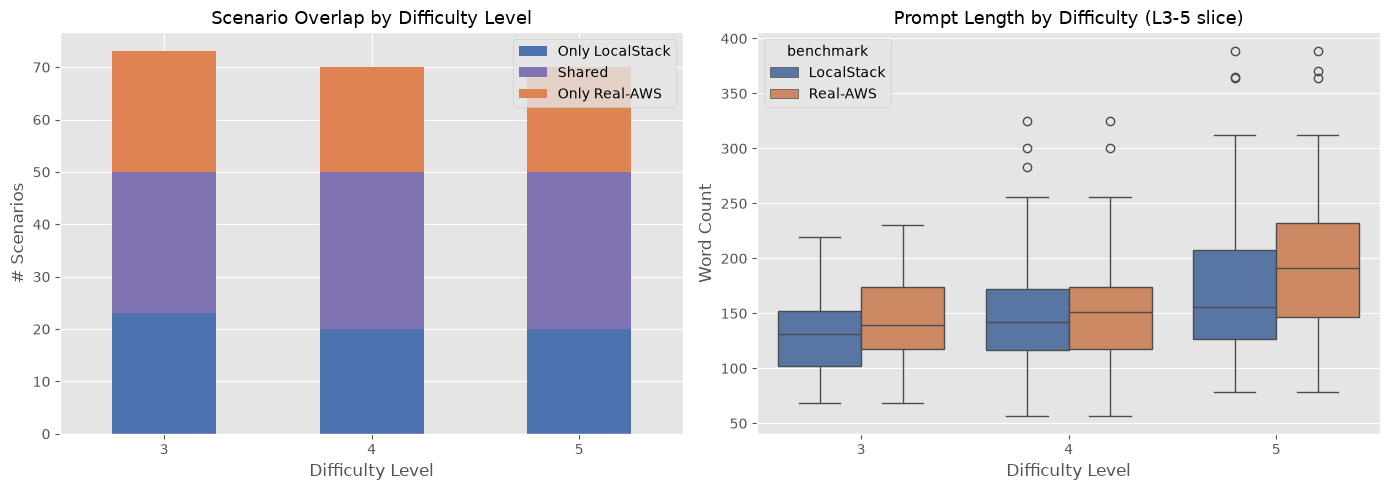


Prompt length (words), L3-5 slice only:
            count   mean    50%   min    max
benchmark                                   
LocalStack  150.0  152.8  143.5  57.0  389.0
Real-AWS    150.0  164.0  154.5  57.0  389.0


In [17]:
_DIFF345_BOTH = (DATASET_DIR / 'cfn_eval_benchmark_diff_345.csv').exists() and (DATASET_DIR / 'cfn_eval_benchmark_real_aws_diff345.csv').exists()
if not _DIFF345_BOTH:
    print('⏸️  One of the diff345 files is missing -- comparison skipped.')
else:
    import pandas as pd

    LOCALSTACK_DIFF345_CSV = DATASET_DIR / 'cfn_eval_benchmark_diff_345.csv'
    REAL_AWS_DIFF345_CSV = DATASET_DIR / 'cfn_eval_benchmark_real_aws_diff345.csv'

    if not LOCALSTACK_DIFF345_CSV.exists():
        raise FileNotFoundError(f"⚠️ {LOCALSTACK_DIFF345_CSV} not found -- this is produced by "
                                 f"cfn_benchmark_builder.ipynb's own L3/4/5 export, not this notebook.")
    if not REAL_AWS_DIFF345_CSV.exists():
        raise FileNotFoundError(f"⚠️ {REAL_AWS_DIFF345_CSV} not found -- run section 8b above first.")

    df_ls345 = pd.read_csv(LOCALSTACK_DIFF345_CSV)
    df_ra345 = pd.read_csv(REAL_AWS_DIFF345_CSV)

    print(f"LocalStack diff345: {len(df_ls345)} rows -- "
          f"{df_ls345['difficulty'].value_counts().sort_index().to_dict()}")
    print(f"Real-AWS diff345:   {len(df_ra345)} rows -- "
          f"{df_ra345['difficulty'].value_counts().sort_index().to_dict()}")

    ls_paths = set(df_ls345['ground_truth_path'])
    ra_paths = set(df_ra345['ground_truth_path'])
    shared_paths = ls_paths & ra_paths
    only_ls_paths = ls_paths - ra_paths
    only_ra_paths = ra_paths - ls_paths

    print(f"\nScenario overlap (by ground_truth_path):")
    print(f"  Shared (deployable on both targets)      : {len(shared_paths)}")
    print(f"  Only in LocalStack diff345                : {len(only_ls_paths)}")
    print(f"  Only in Real-AWS diff345                  : {len(only_ra_paths)}")
    print(f"  Jaccard overlap                            : {len(shared_paths) / len(ls_paths | ra_paths):.1%}")

    overlap_rows = []
    for lvl in [3, 4, 5]:
        lvl_ls = set(df_ls345.loc[df_ls345['difficulty'] == lvl, 'ground_truth_path'])
        lvl_ra = set(df_ra345.loc[df_ra345['difficulty'] == lvl, 'ground_truth_path'])
        overlap_rows.append({
            'difficulty': lvl,
            'Only LocalStack': len(lvl_ls - lvl_ra),
            'Shared': len(lvl_ls & lvl_ra),
            'Only Real-AWS': len(lvl_ra - lvl_ls),
        })
    overlap_df = pd.DataFrame(overlap_rows).set_index('difficulty')
    display(overlap_df)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    overlap_df.plot(kind='bar', stacked=True, ax=axes[0],
                     color=['#4c72b0', '#8172b2', '#dd8452'])
    axes[0].set_title('Scenario Overlap by Difficulty Level', fontsize=13)
    axes[0].set_xlabel('Difficulty Level')
    axes[0].set_ylabel('# Scenarios')
    axes[0].tick_params(axis='x', rotation=0)
    axes[0].legend(title=None)

    df_ls345 = df_ls345.copy()
    df_ra345 = df_ra345.copy()
    df_ls345['prompt_word_count'] = df_ls345['prompt'].apply(
        lambda x: len(str(x).split()) if pd.notna(x) else 0)
    df_ra345['prompt_word_count'] = df_ra345['prompt'].apply(
        lambda x: len(str(x).split()) if pd.notna(x) else 0)

    df_ls345['benchmark'] = 'LocalStack'
    df_ra345['benchmark'] = 'Real-AWS'
    df_345_compare = pd.concat([df_ls345, df_ra345], ignore_index=True)

    sns.boxplot(data=df_345_compare, x='difficulty', y='prompt_word_count', hue='benchmark',
                palette={'LocalStack': '#4c72b0', 'Real-AWS': '#dd8452'}, ax=axes[1])
    axes[1].set_title('Prompt Length by Difficulty (L3-5 slice)', fontsize=13)
    axes[1].set_xlabel('Difficulty Level')
    axes[1].set_ylabel('Word Count')

    plt.tight_layout()
    plt.show()

    print(f"\nPrompt length (words), L3-5 slice only:")
    print(df_345_compare.groupby('benchmark')['prompt_word_count'].describe()[
        ['count', 'mean', '50%', 'min', 'max']].round(1).to_string())

## Appendix: L5 Failure Funnel & Minimal-Fix Triage (gated by `RUN_L5_TRIAGE`)

In [18]:
if not RUN_L5_TRIAGE:
    print('⏸️  RUN_L5_TRIAGE is False -- skipped.')
else:
    import pandas as pd
    from pathlib import Path
    from collections import Counter


    df_aws_l5 = pd.read_csv(DATASET_DIR / 'df_aws_cache.csv')
    l5 = df_aws_l5[df_aws_l5['difficulty'] == 5].copy()
    print(f'L5 raw pool (post-licence, pre-lint): {len(l5):,}')

    lint = pd.read_csv(DATASET_DIR / 'lint_cache.csv')
    l5 = l5.merge(lint[['content_hash', 'lint_pass', 'lint_error_codes', 'lint_error_msg']], on='content_hash', how='left')

    print(f'  lint_pass True  : {(l5["lint_pass"]==True).sum():,}')
    print(f'  lint_pass False : {(l5["lint_pass"]==False).sum():,}')
    print('\nTop lint failure codes (L5):')
    lint_codes = Counter()
    for codes_str in l5.loc[l5['lint_pass'] == False, 'lint_error_codes'].dropna():
        for code in str(codes_str).split(' | '):
            if code:
                lint_codes[code] += 1
    for code, cnt in lint_codes.most_common(15):
        print(f'  [{cnt:4d}] {code}')

    lint_ok = l5[l5['lint_pass'] == True].copy()
    sec = pd.read_csv(DATASET_DIR / 'security_cache.csv')
    lint_ok = lint_ok.merge(
        sec[['content_hash', 'trivy_critical', 'trivy_high', 'trivy_error', 'trivy_checks_with_severity']],
        on='content_hash', how='left'
    )
    trivy_clean = (
        (lint_ok['trivy_critical'].fillna(-1) == 0)
        & (lint_ok['trivy_high'].fillna(-1) == 0)
        & (lint_ok['trivy_error'].fillna('') == '')
    )
    print(f'\n  of lint-passed, trivy-clean : {trivy_clean.sum():,} / {len(lint_ok):,}')
    print(f'  of lint-passed, trivy-failed: {(~trivy_clean).sum():,}')
    print('\nTop Trivy findings among lint-passed L5 rows that fail the severity gate:')
    trivy_findings = Counter()
    for checks_str in lint_ok.loc[~trivy_clean, 'trivy_checks_with_severity'].dropna():
        for check in str(checks_str).split(' | '):
            cid = check.split(':')[0] if ':' in check else check
            if cid:
                trivy_findings[cid] += 1
    for cid, cnt in trivy_findings.most_common(15):
        print(f'  [{cnt:4d}] {cid}')

    dep = pd.read_csv(DATASET_DIR / 'deploy_cache_aws_stack.csv', usecols=['content_hash', 'validate_pass', 'deploy_pass', 'deploy_error'])
    sec_ok = lint_ok[trivy_clean].merge(dep, on='content_hash', how='left')
    tested   = sec_ok[sec_ok['deploy_pass'].notna()]
    failed   = sec_ok[sec_ok['deploy_pass'] == False]
    untested = sec_ok[sec_ok['deploy_pass'].isna()]

    print(f'\n  of trivy-clean, deploy attempted : {len(tested):,}')
    print(f'  of trivy-clean, deploy passed    : {(sec_ok["deploy_pass"]==True).sum():,}')
    print(f'  of trivy-clean, deploy failed    : {len(failed):,}')
    print(f'  of trivy-clean, NEVER deploy-tested (run cell 9c + 10 on these first): {len(untested):,}')

    print('\nTop deploy failure reasons (already licence+lint+security-clean L5 rows -- good minimal-fix candidates):')
    deploy_errs = Counter()
    for err in failed['deploy_error'].dropna():
        deploy_errs[str(err)[:120]] += 1
    for err, cnt in deploy_errs.most_common(15):
        print(f'  [{cnt:2d}] {err}')

    EXPORT_COLS = ['content_hash', 'dest_file', 'source_slug', 'licence_spdx', 'loc', 'n_resources']

    triage_rows = []
    for _, row in l5[l5['lint_pass'] == False].iterrows():
        triage_rows.append({**{c: row.get(c) for c in EXPORT_COLS}, 'failure_stage': 'lint', 'failure_reason': row.get('lint_error_msg')})
    for _, row in lint_ok[~trivy_clean].iterrows():
        triage_rows.append({**{c: row.get(c) for c in EXPORT_COLS}, 'failure_stage': 'security', 'failure_reason': row.get('trivy_checks_with_severity')})
    for _, row in failed.iterrows():
        triage_rows.append({**{c: row.get(c) for c in EXPORT_COLS}, 'failure_stage': 'deploy', 'failure_reason': str(row.get('deploy_error'))[:300]})

    df_triage = pd.DataFrame(triage_rows)
    TRIAGE_CSV = DATASET_DIR / 'l5_failure_triage.csv'
    df_triage.to_csv(TRIAGE_CSV, index=False)
    print(f'\n💾 Full triage sheet ({len(df_triage):,} rows) saved to: {TRIAGE_CSV}')
    print("   Prioritize 'deploy' and 'security' stage rows first -- they already cleared the most")
    print("   gates, so they usually need only one small, targeted fix to become deploy-verified.")

⏸️  RUN_L5_TRIAGE is False -- skipped.
